# Assignment 1

Computer Vision - COMP9320 - Fall 2026 

Submission deadline: 13.11.2026

Instructor: Dr. Yazan Abu Farha

Student: Ruwa AbuHweidi

**Objective**
The objective of this assignment is to implement and analyze fundamental digital
image processing techniques using Python and OpenCV. You will explore image
smoothing, noise reduction, edge detection, and multiresolution image blending.

**Submission Requirements**
- Write Python code to complete all the tasks.
- Use a Jupyter Notebook (.ipynb) to implement and document your solutions.
- Include the input images, processed results, and appropriate visualizations.
- Add brief explanations of the methods used and observations about the results.
- Submit the completed Jupyter Notebook.

In [1]:
# Import the libraries used throughout the assignment.
%matplotlib inline
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Set the input and output paths relative to the project or notebook directory.
ASSIGNMENT_DIR = Path.cwd()
if not (ASSIGNMENT_DIR / "data" / "uni.jpeg").is_file():
    ASSIGNMENT_DIR = ASSIGNMENT_DIR / "Assignments" / "Assign_1"
DATA_DIR = ASSIGNMENT_DIR / "data"
OUTPUT_DIR = ASSIGNMENT_DIR / "outputs"

## Task 1: Image Loading and Grayscale Conversion

### 1. Use OpenCV to read the image uni.jpeg.

In [3]:
# Read the original color image in OpenCV BGR format.
image_path = DATA_DIR / "uni.jpeg"
original_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)  
if original_bgr is None:
    raise FileNotFoundError(f"Unable to read image: {image_path}")

### 2. Display the original image and report its properties.

#### Spatial dimensions

- **Pixel:** one spatial sample of a digital image; a color pixel contains values for its color channels.
- **Spatial dimensions:** image height (rows) and width (columns), measured in pixels. For a color array, `shape` is `(height, width, channels)`; `shape[:2]` selects only the spatial dimensions.
- **BGR and RGB:** channel orders for blue, green, and red values. OpenCV loads this image in BGR order; Matplotlib expects RGB. Reordering channels preserves the spatial dimensions and displays the intended colors.

Spatial dimensions (height x width): 476 x 645 pixels


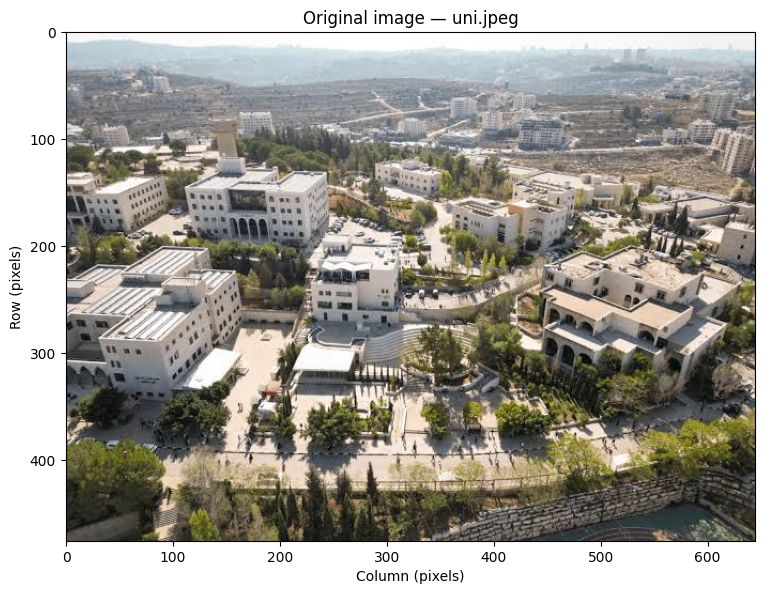

In [4]:
# Display the original image in RGB order and report its height and width.
original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
height, width = original_bgr.shape[:2]
print(f"Spatial dimensions (height x width): {height} x {width} pixels")

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(original_rgb)
ax.set_title("Original image — uni.jpeg")
ax.set_xlabel("Column (pixels)")
ax.set_ylabel("Row (pixels)")
plt.tight_layout()
plt.show()

**Observation:** The image has 476 rows and 645 columns.

#### Number of color channels

A **color channel** is a two-dimensional array containing one color component at every pixel. This image has blue, green, and red channels. OpenCV stores them in BGR order; each pixel therefore contains three values. The third element of `shape` gives the channel count, whereas `ndim` counts array axes.

In [5]:
# Report the color channel count, channel order, and array structure.
channel_count = original_bgr.shape[2]
print(f"Number of color channels: {channel_count}")
print("OpenCV channel order: BGR (Blue, Green, Red)")
print("Display channel order: RGB (Red, Green, Blue)")
print(f"Image array shape (height, width, channels): {original_bgr.shape}")
print(f"Number of array axes: {original_bgr.ndim}")
for index, name in enumerate(("Blue", "Green", "Red")):
    print(f"Channel {index}: {name}; spatial shape: {original_bgr[:, :, index].shape}")

Number of color channels: 3
OpenCV channel order: BGR (Blue, Green, Red)
Display channel order: RGB (Red, Green, Blue)
Image array shape (height, width, channels): (476, 645, 3)
Number of array axes: 3
Channel 0: Blue; spatial shape: (476, 645)
Channel 1: Green; spatial shape: (476, 645)
Channel 2: Red; spatial shape: (476, 645)


**Observation:** There are three color channels, each with 476 rows and 645 columns. The channel axis stores color components.

#### Data type and numerical intensity range

- **Data type (`dtype`):** the representation used to store each channel value. `uint8` is an unsigned 8-bit integer: it represents 256 integer levels from 0 to 255.
- **Channel intensity:** the stored value of one color component at a pixel. Zero is the minimum component level; 255 is the maximum. A single channel value is not the overall brightness of a color pixel.
- **Representable range:** the limits allowed by the data type, obtained with `np.iinfo`. 
- **Observed range:** the minimum and maximum actually present in the image, obtained with `min()` and `max()`. These ranges need not be equal.

In [6]:
# Report the data type, representable limits, and observed channel intensities.
dtype_limits = np.iinfo(original_bgr.dtype)
print(f"Data type: {original_bgr.dtype}")
print(f"Bits per channel value: {dtype_limits.bits}")
print(f"Representable intensity range: [{dtype_limits.min}, {dtype_limits.max}]")
print(f"Representable intensity levels: {int(dtype_limits.max) - int(dtype_limits.min) + 1}")
print(f"Observed intensity range across all channels: [{original_bgr.min()}, {original_bgr.max()}]")
for index, name in enumerate(("Blue", "Green", "Red")):
    channel = original_bgr[:, :, index]
    print(f"Observed {name} channel range: [{channel.min()}, {channel.max()}]")

Data type: uint8
Bits per channel value: 8
Representable intensity range: [0, 255]
Representable intensity levels: 256
Observed intensity range across all channels: [0, 255]
Observed Blue channel range: [0, 255]
Observed Green channel range: [0, 255]
Observed Red channel range: [0, 255]


**Observation:** The image uses `uint8`. The observed range is [0, 255] both overall and in each color channel.

#### Memory requirements

- **Byte:** 8 bits. A `uint8` channel value occupies one byte (`itemsize`).
- **Array data memory:** the bytes occupied by the decoded pixel values (`nbytes`), excluding Python object metadata and other arrays. For this image: $M = H \times W \times C \times \text{bytes per channel value}$.
- **Units:** 1 KiB = 1,024 bytes; 1 MiB = 1,048,576 bytes; 1 MB = 1,000,000 bytes.
- **JPEG file size:** compressed storage on disk; it differs from the decoded array memory.

In [7]:
# Calculate decoded image memory and compare it with the compressed JPEG file size.
pixel_count = height * width
bytes_per_value = original_bgr.itemsize
expected_bytes = pixel_count * channel_count * bytes_per_value
image_bytes = original_bgr.nbytes
jpeg_bytes = image_path.stat().st_size
print(f"Number of spatial pixels: {pixel_count:,}")
print(f"Number of stored channel values: {original_bgr.size:,}")
print(f"Bytes per channel value: {bytes_per_value}")
print(f"Bytes per color pixel: {channel_count * bytes_per_value}")
print(f"Memory calculation: {height} x {width} x {channel_count} x {bytes_per_value} = {expected_bytes:,} bytes")
print(f"Decoded array data (nbytes): {image_bytes:,} bytes")
print(f"Decoded array data: {image_bytes / 1024:.2f} KiB; {image_bytes / 1024**2:.4f} MiB; {image_bytes / 10**6:.5f} MB")
print(f"Compressed JPEG file: {jpeg_bytes:,} bytes ({jpeg_bytes / 1024:.2f} KiB)")
print(f"Calculated memory matches nbytes: {expected_bytes == image_bytes}")

Number of spatial pixels: 307,020
Number of stored channel values: 921,060
Bytes per channel value: 1
Bytes per color pixel: 3
Memory calculation: 476 x 645 x 3 x 1 = 921,060 bytes
Decoded array data (nbytes): 921,060 bytes
Decoded array data: 899.47 KiB; 0.8784 MiB; 0.92106 MB
Compressed JPEG file: 67,589 bytes (66.00 KiB)
Calculated memory matches nbytes: True


**Observation:** The decoded BGR pixel data occupies 921,060 bytes, whereas the JPEG file occupies 67,589 bytes. JPEG stores a compressed representation. The reported array memory excludes the separate RGB display copy, plotting buffers, and Python object overhead.

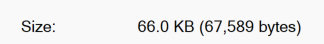

### 3. Convert the original image to grayscale.

**Grayscale** represents each pixel with one intensity value instead of three color components. For `uint8`, 0 represents black and 255 white. OpenCV combines the channels using:

$$Y = 0.299R + 0.587G + 0.114B.$$

The unequal weights approximate the different contributions of the color components to perceived brightness; this is not a simple channel average or a physical luminance measurement. `COLOR_BGR2GRAY` matches the input BGR order. Integer conversion quantizes the result, so manually computed floating-point values may differ slightly.

The conversion preserves height and width but discards color information; the original colors cannot generally be recovered from the grayscale image.

In [8]:
# Convert the original BGR image to one grayscale channel and report its properties.
gray = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2GRAY)
print("Conversion: cv2.COLOR_BGR2GRAY")
print("Weighted intensity: Y = 0.299R + 0.587G + 0.114B")
print(f"Grayscale shape (height, width): {gray.shape}")
print("Number of grayscale channels: 1")
print(f"Number of array axes: {gray.ndim}")
print(f"Data type: {gray.dtype}")
print(f"Observed intensity range: [{gray.min()}, {gray.max()}]")
print(f"Spatial dimensions preserved: {gray.shape == original_bgr.shape[:2]}")
print(f"Grayscale array data: {gray.nbytes:,} bytes")

Conversion: cv2.COLOR_BGR2GRAY
Weighted intensity: Y = 0.299R + 0.587G + 0.114B
Grayscale shape (height, width): (476, 645)
Number of grayscale channels: 1
Number of array axes: 2
Data type: uint8
Observed intensity range: [0, 255]
Spatial dimensions preserved: True
Grayscale array data: 307,020 bytes


**Observation:** The grayscale image is a two-dimensional `uint8` array of shape (476, 645), with intensities from 0 to 255. It stores one value per pixel and uses 307,020 bytes of pixel data, one-third of the original BGR array.

### 4. Display the grayscale image.

A **colormap** maps stored values to display colors. `cmap="gray"` displays low intensities as dark and high intensities as light. Setting `vmin=0` and `vmax=255` fixes the display scale to the full 8-bit range; it does not modify the image values. `interpolation="nearest"` avoids smoothing between pixels during rendering.

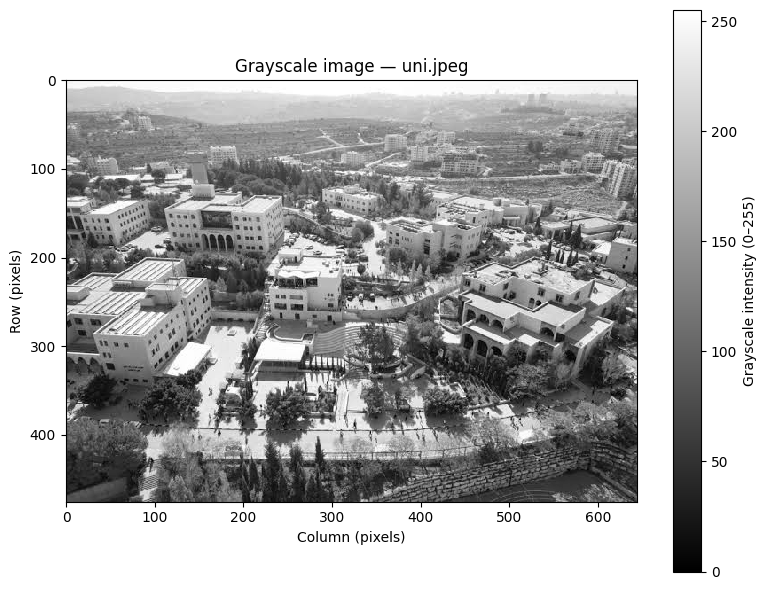

In [9]:
# Display the grayscale image with a fixed intensity scale and labeled axes.
fig, ax = plt.subplots(figsize=(8, 6))
gray_plot = ax.imshow(gray, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
ax.set_title("Grayscale image — uni.jpeg")
ax.set_xlabel("Column (pixels)")
ax.set_ylabel("Row (pixels)")
fig.colorbar(gray_plot, ax=ax, label="Grayscale intensity (0–255)")
plt.tight_layout()
plt.show()

**Observation:** The grayscale view retains the spatial layout while removing color distinctions. Dark and light areas represent low and high weighted intensities. Different colors can map to similar gray values, so some color-based distinctions may be lost.

## Task 2: Edge Detection Using Canny

### 1. Use the grayscale image obtained in Task 1.

An **edge** is a location of a rapid spatial change in image intensity. It may indicate an object boundary, texture, or a lighting change; not every detected edge is an object boundary. **Edge detection** identifies these changes to emphasize image structure.

Reuse `gray` from Task 1 as the single-channel input.

In [10]:
# Reuse the Task 1 grayscale image and validate the input for edge detection.
assert gray.ndim == 2, "Expected a single-channel grayscale image."
assert gray.dtype == np.uint8, "Expected an 8-bit unsigned integer image."
assert gray.shape == original_bgr.shape[:2], "Spatial dimensions do not match."
canny_input = gray
print("Input source: Task 1 grayscale image (gray)")
print(f"Input shape (height, width): {canny_input.shape}")
print("Number of channels: 1")
print(f"Input data type: {canny_input.dtype}")
print(f"Observed intensity range: [{canny_input.min()}, {canny_input.max()}]")
print(f"Same array as Task 1 grayscale image: {canny_input is gray}")

Input source: Task 1 grayscale image (gray)
Input shape (height, width): (476, 645)
Number of channels: 1
Input data type: uint8
Observed intensity range: [0, 255]
Same array as Task 1 grayscale image: True


**Observation:** The input is the existing (476, 645) `uint8` grayscale array. `canny_input = gray` creates another reference to the same array, not a copy; this step does not change its values.

### 2. Apply the Canny edge detection algorithm to extract the edges.

**Gaussian smoothing** averages nearby pixels with greater weight near the center to reduce noise before detecting intensity changes. We explicitly apply a 5 × 5 Gaussian kernel with standard deviation $\sigma=1$ pixel.

A **gradient** measures the spatial change in intensity. Canny uses gradients, thins candidate edges, then links them using **hysteresis**: strong responses above the upper threshold seed edges; weaker candidates between the thresholds survive only when connected to strong edges. Thresholds apply to gradient magnitude, not directly to grayscale values.

Use initial thresholds of 50 and 150. `apertureSize=3` selects a 3 × 3 Sobel derivative kernel; `L2gradient=True` uses $\sqrt{G_x^2+G_y^2}$. The threshold choice will be assessed in Steps 5–6. A **binary edge map** contains two labels: 255 for detected edges and 0 for non-edges.

**Parameter glossary:**

| Term / variable | Meaning in this implementation |
| --- | --- |
| Kernel | A small matrix of filter weights applied over a pixel neighborhood. |
| Sobel operator | A discrete derivative filter approximating intensity changes along columns ($G_x$) and rows ($G_y$). It combines differentiation with smoothing in the perpendicular direction. |
| `sobel_aperture` | Our variable for the Sobel kernel side length; passed to Canny as `apertureSize`. A value of 3 means a 3 × 3 neighborhood, not three passes or a camera aperture. |
| `gaussian_kernel` | Width and height of the separate Gaussian smoothing kernel: (5, 5). |
| `gaussian_sigma` | Gaussian standard deviation in pixels; controls the spread of smoothing weights. |
| `use_l2_gradient` | Our Boolean variable passed as `L2gradient`; `True` selects Euclidean gradient magnitude. |
| `BORDER_REFLECT_101` | Extends image values by reflection without repeating the boundary pixel, allowing filtering near image borders. |

In [11]:
# Smooth the grayscale input, apply Canny, and report the settings and output.
gaussian_kernel = (5, 5) # (3,3) or (7,7) or (9,9)
gaussian_sigma = 1.0 # 0.5 or 1.5
lower_threshold = 50 # 25 or 50 or 75 or 100 
upper_threshold = 150 # 100 or 150 or 200 or 250
sobel_aperture = 3 # 3 or 5 or 7
use_l2_gradient = True
smoothed_gray = cv2.GaussianBlur(
    canny_input, gaussian_kernel, sigmaX=gaussian_sigma,
    sigmaY=gaussian_sigma, borderType=cv2.BORDER_REFLECT_101
)
edges = cv2.Canny(
    smoothed_gray, lower_threshold, upper_threshold,
    apertureSize=sobel_aperture, L2gradient=use_l2_gradient
)
edge_pixel_count = np.count_nonzero(edges)
print(f"Gaussian kernel: {gaussian_kernel}; sigma: {gaussian_sigma} pixel")
print("Gaussian border handling: BORDER_REFLECT_101")
print(f"Hysteresis thresholds (lower, upper): ({lower_threshold}, {upper_threshold})")
print(f"Sobel aperture size: {sobel_aperture}; L2gradient: {use_l2_gradient}")
print(f"Edge map shape: {edges.shape}; data type: {edges.dtype}")
print(f"Unique output values: {np.unique(edges).tolist()}")
print(f"Detected edge pixels: {edge_pixel_count:,} / {edges.size:,}")
print(f"Edge pixel percentage: {100 * edge_pixel_count / edges.size:.2f}%")

Gaussian kernel: (5, 5); sigma: 1.0 pixel
Gaussian border handling: BORDER_REFLECT_101
Hysteresis thresholds (lower, upper): (50, 150)
Sobel aperture size: 3; L2gradient: True
Edge map shape: (476, 645); data type: uint8
Unique output values: [0, 255]
Detected edge pixels: 45,729 / 307,020
Edge pixel percentage: 14.89%


**Interpretation:** White pixels label retained edges; black pixels label non-edges. The edge pixel percentage describes output density, not detection accuracy. The same smoothing and gradient settings must be retained when comparing thresholds.

### 3. Display the grayscale image and the resulting edge image side by side.

The **grayscale image** stores intensity values, whereas the **edge map** stores binary edge labels. Both panels use the same spatial coordinates and a fixed 0–255 display range. The left panel shows the original Task 1 grayscale image; Canny was applied to its Gaussian-smoothed version in Step 2.

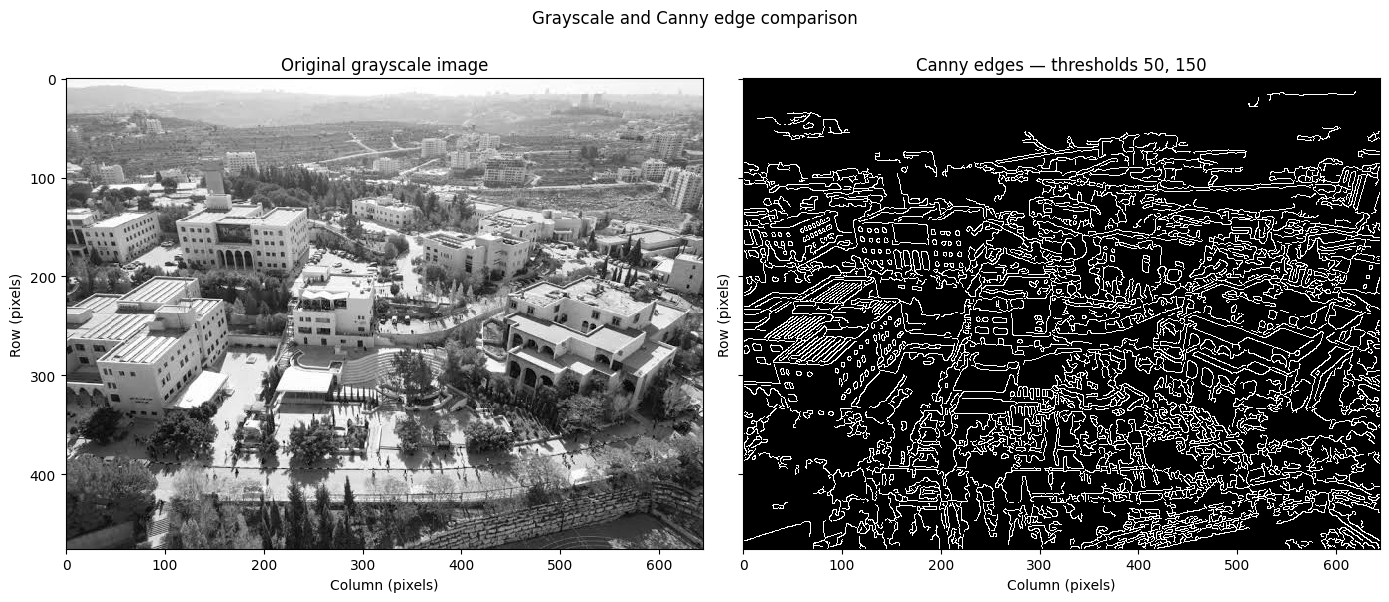

In [12]:
# Compare the original grayscale image with the Canny edge map at matching scales.
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
axes[0].imshow(canny_input, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[0].set_title("Original grayscale image")
axes[1].imshow(edges, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[1].set_title(f"Canny edges — thresholds {lower_threshold}, {upper_threshold}")
for ax in axes:
    ax.set_xlabel("Column (pixels)")
    ax.set_ylabel("Row (pixels)")
fig.suptitle("Grayscale and Canny edge comparison")
plt.tight_layout()
plt.show()

**Observation:** The edge map highlights building outlines, paths, and fine vegetation or architectural texture while discarding the grayscale shading. Some visible responses arise from texture and shadows rather than object boundaries. White pixels represent detected edges, not brighter scene regions; visual comparison alone does not establish detection accuracy.

### 4. Explain the five fundamental stages of the Canny algorithm.

The Canny edge detection pipeline systematically transforms a raw grayscale image into a clean binary edge map through five sequential stages: it begins with Gaussian smoothing, convolving the image with a Gaussian kernel to suppress high-frequency sensor noise that would otherwise trigger false edge responses, then proceeds to gradient computation, applying directional derivative operators (such as Sobel filters) along the horizontal and vertical axes to measure abrupt spatial changes in pixel intensity, followed by gradient magnitude and orientation estimation, where these directional derivatives are mathematically combined to quantify the exact strength of each intensity transition and determine the angle perpendicular to the edge contour; because these initial gradient responses produce thick, multi-pixel ridges around true boundaries, non-maximum suppression evaluates each pixel against its neighbors along the gradient direction and zeroes out any value that is not a local maximum, thinning the detected boundaries into precise, single-pixel-wide contours, before finally executing hysteresis thresholding, which classifies candidate edge pixels using upper and lower intensity bounds-retaining strong edges above the high threshold, discarding weak responses below the low threshold, and preserving intermediate edges only if they maintain continuous connectivity to a verified strong edge.

**In detail:** From 4.1 to 4.5

#### 4.1 Gaussian smoothing

**Smoothing** reduces rapid local intensity variations. A Gaussian filter replaces each pixel with a weighted average of its neighborhood, assigning larger weights near the center:

$$K(i,j)=\frac{\exp\left[-(i^2+j^2)/(2\sigma^2)\right]}{\sum_{u,v}\exp\left[-(u^2+v^2)/(2\sigma^2)\right]},\qquad I_s(x,y)=\sum_{i,j}K(i,j)I(x-i,y-j).$$

Here, $I$ is the grayscale image, $I_s$ is the smoothed image, and $(i,j)$ are kernel offsets. **Normalization** makes the finite kernel weights sum to 1, preserving constant intensities away from numerical rounding.

**Why before differentiation?** Derivatives respond strongly to rapid variations, including noise. Smoothing suppresses some unwanted responses, but also softens real edges and fine texture. Larger $\sigma$ generally increases this tradeoff when the kernel support is sufficient.

**Connection to Step 2:** `cv2.GaussianBlur` explicitly produces `smoothed_gray` with a 5 × 5 kernel and $\sigma_x=\sigma_y=1$. The separate Gaussian operation is not an additional Gaussian stage automatically applied by `cv2.Canny`. Sobel's built-in perpendicular smoothing does not replace this explicit preprocessing.

#### 4.2 Gradient computation

A **partial derivative** measures change along one coordinate while holding the other fixed. The image **gradient** is the vector $\nabla I_s=(G_x,G_y)$: $G_x$ approximates change along columns (left to right), and $G_y$ along rows (top to bottom). Sobel estimates these derivatives from neighboring pixels of the smoothed image.

For the 3 × 3 Sobel operator, the correlation kernels are:

$$K_x=\begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix},\qquad K_y=\begin{bmatrix}-1&-2&-1\\0&0&0\\1&2&1\end{bmatrix}.$$

**Correlation** multiplies each kernel weight by the corresponding neighborhood value and sums the products without flipping the kernel. Thus $G_x$ is positive for intensity increasing to the right, while $G_y$ is positive for intensity increasing downward. A large absolute response indicates a strong change; $G_x$ emphasizes vertical boundaries and $G_y$ horizontal boundaries.

**Code parameters:** `dx` and `dy` are derivative orders: `(1, 0)` computes the first x derivative, and `(0, 1)` the first y derivative. `ksize=sobel_aperture` selects the 3 × 3 kernel. `ddepth=cv2.CV_32F` stores signed 32-bit floating-point responses, preserving negative derivatives that `uint8` cannot represent. `BORDER_REPLICATE` extends the nearest boundary value for derivative filtering.

The following cell illustrates this stage separately:

In [13]:
# Compute signed Sobel derivatives of the Gaussian-smoothed image for illustration.
gradient_x = cv2.Sobel(
    smoothed_gray, cv2.CV_32F, dx=1, dy=0,
    ksize=sobel_aperture, borderType=cv2.BORDER_REPLICATE
)
gradient_y = cv2.Sobel(
    smoothed_gray, cv2.CV_32F, dx=0, dy=1,
    ksize=sobel_aperture, borderType=cv2.BORDER_REPLICATE
)
print(f"Sobel kernel size: {sobel_aperture} x {sobel_aperture}")
print("Derivative border handling: BORDER_REPLICATE")
for name, derivative in (("Gx: column-direction change", gradient_x),
                         ("Gy: row-direction change", gradient_y)):
    print(f"{name}; shape: {derivative.shape}; dtype: {derivative.dtype}")
    print(f"  Signed response range: [{derivative.min():.1f}, {derivative.max():.1f}]")

Sobel kernel size: 3 x 3
Derivative border handling: BORDER_REPLICATE
Gx: column-direction change; shape: (476, 645); dtype: float32
  Signed response range: [-477.0, 521.0]
Gy: row-direction change; shape: (476, 645); dtype: float32
  Signed response range: [-506.0, 492.0]


**Interpretation:** Derivative responses are signed changes, not grayscale intensities; their range is not restricted to 0–255. Negative responses indicate decreasing intensity in the corresponding coordinate direction. The next stage combines these components into magnitude and orientation.

#### 4.3 Gradient magnitude and orientation estimation

**Magnitude** is the length of the gradient vector and measures the strength of local intensity change. **Orientation** is the direction of greatest increase in intensity, perpendicular to the local edge tangent:

$$M=\sqrt{G_x^2+G_y^2},\qquad \theta=\operatorname{atan2}(G_y,G_x).$$

`np.hypot(Gx, Gy)` computes the Euclidean magnitude element by element. `np.arctan2(Gy, Gx)` uses both signs to select the correct quadrant and avoids explicit division by zero. Its argument order is y first, x second. It returns **radians** (a full turn is $2\pi$); `np.degrees` converts to **degrees** (a full turn is 360°).

Since image rows increase downward, 0° points right, +90° down, and −90° up. Where magnitude is zero, orientation is undefined; the code marks it as `NaN` (not a number). **Modulo 180°** maps opposite gradient directions to the same unoriented axis, useful for comparing neighbors during non-maximum suppression. These illustrative arrays:

In [14]:
# Calculate gradient strength and direction while excluding zero-gradient orientations.
gradient_magnitude = np.hypot(gradient_x, gradient_y)
orientation_degrees = np.degrees(np.arctan2(gradient_y, gradient_x))
valid_orientation = gradient_magnitude > 0
orientation_degrees = np.where(valid_orientation, orientation_degrees, np.nan)
orientation_axis = np.mod(orientation_degrees, 180.0)
print(f"Magnitude shape: {gradient_magnitude.shape}; dtype: {gradient_magnitude.dtype}")
print(f"Magnitude range: [{gradient_magnitude.min():.2f}, {gradient_magnitude.max():.2f}]")
print("Directed angle convention: degrees from +x; positive toward increasing rows")
print("Directed angle interval: [-180, 180] degrees")
print("Unoriented gradient axis interval: [0, 180) degrees")
print(f"Pixels with defined orientation: {np.count_nonzero(valid_orientation):,}")
print(f"Zero-gradient pixels (undefined orientation): {np.count_nonzero(~valid_orientation):,}")
if np.any(valid_orientation):
    print(f"Observed directed angle range: [{np.nanmin(orientation_degrees):.2f}, {np.nanmax(orientation_degrees):.2f}] degrees")

Magnitude shape: (476, 645); dtype: float32
Magnitude range: [0.00, 562.45]
Directed angle convention: degrees from +x; positive toward increasing rows
Directed angle interval: [-180, 180] degrees
Unoriented gradient axis interval: [0, 180) degrees
Pixels with defined orientation: 302,392
Zero-gradient pixels (undefined orientation): 4,628
Observed directed angle range: [-179.84, 180.00] degrees


**Interpretation:** Magnitude is nonnegative and can exceed 255 because it is derived from signed Sobel responses, not stored grayscale intensity. A large magnitude alone does not establish an edge: non-maximum suppression and hysteresis still determine which responses survive. At very small magnitudes, orientation is sensitive to small intensity changes.

#### 4.4 Non-maximum suppression (NMS)

**Suppression** means setting a response to zero. A **local maximum** is a response at least as large as its nearby comparison values. NMS thins broad gradient ridges by retaining local peaks **along the gradient direction**, across the edge rather than along its tangent.

At pixel $p$, compare $M(p)$ with magnitudes on both sides along the gradient axis. Suppress it if either comparison is larger. A common discrete approximation groups orientations into 0°, 45°, 90°, and 135°:

| Gradient axis (image coordinates) | Neighbors compared |
| --- | --- |
| 0° | Left and right |
| 45° | Upper-left and lower-right |
| 90° | Above and below |
| 135° | Upper-right and lower-left |

**Tie handling** determines which equal neighboring peaks survive; implementations may use asymmetric comparisons. NMS retains selected magnitudes and zeros others; its conceptual output is not yet the final binary edge map. Hysteresis subsequently selects and links candidates.

The following one-dimensional profile illustrates a cross-section along the gradient direction. It uses strict comparisons for a unique peak and sets its two endpoints to zero (Toy example).

In [15]:
# Illustrate thinning of a gradient ridge using a unique local maximum.
nms_profile = np.array([0, 20, 60, 100, 70, 30, 0], dtype=np.float32)
nms_profile_thinned = np.zeros_like(nms_profile)
local_peak_mask = (
    (nms_profile[1:-1] > nms_profile[:-2])
    & (nms_profile[1:-1] > nms_profile[2:])
)
nms_profile_thinned[1:-1] = np.where(local_peak_mask, nms_profile[1:-1], 0)
print("Illustrative gradient magnitudes:", nms_profile.tolist())
print("After non-maximum suppression:", nms_profile_thinned.tolist())
print(f"Nonzero responses before: {np.count_nonzero(nms_profile)}")
print(f"Nonzero responses after: {np.count_nonzero(nms_profile_thinned)}")

Illustrative gradient magnitudes: [0.0, 20.0, 60.0, 100.0, 70.0, 30.0, 0.0]
After non-maximum suppression: [0.0, 0.0, 0.0, 100.0, 0.0, 0.0, 0.0]
Nonzero responses before: 5
Nonzero responses after: 1


**Interpretation:** The response 100 survives because it exceeds both neighbors. The other positive responses are suppressed, reducing a five-sample ridge to one sample. No lower or upper threshold is applied in this example; NMS compares neighboring strengths rather than selecting edges by absolute strength.

#### 4.5 Hysteresis thresholding

**Hysteresis** uses two thresholds and connectivity to decide which thinned gradient responses form final edges. With lower threshold $T_L$ and upper threshold $T_H$ ($T_L<T_H$), this example uses the following explicit convention:

- **Strong edge seed:** a retained magnitude greater than $T_H$.
- **Weak candidate:** a retained magnitude greater than $T_L$ but no greater than $T_H$.
- **Rejected response:** a magnitude no greater than $T_L$.

**8-connectivity** allows a pixel to connect to its horizontal, vertical, and diagonal neighbors. Keep a weak candidate only if a path of eligible candidates connects it to a strong seed. The path may contain several weak pixels: direct adjacency to a strong seed is not required. An isolated weak component is discarded.

The thresholds apply to magnitudes after non-maximum suppression, not to the original grayscale intensities. The final **binary edge map** uses 255 for retained pixels and 0 otherwise.

The illustrative matrix below represents responses *after* NMS. `connectedComponents` assigns a distinct integer **label** to each connected foreground region; label 0 is background. Keeping components containing strong seeds illustrates hysteresis (Toy example).

In [16]:
# Illustrate hysteresis by keeping candidate components connected to strong seeds.
hysteresis_demo = np.array([
    [0, 200, 90, 70, 0, 0, 0],
    [0,   0,  0,  0, 0, 0, 0],
    [0,   0,  0,  0, 0, 0, 0],
    [0,  80, 60,  0, 0, 0, 0],
    [0,   0,  0,  0, 0, 0, 0]
], dtype=np.float32)
demo_low, demo_high = 50, 150
candidate_mask = hysteresis_demo > demo_low
strong_mask = hysteresis_demo > demo_high
component_count, component_labels = cv2.connectedComponents(
    candidate_mask.astype(np.uint8), connectivity=8
)
strong_component_labels = np.unique(component_labels[strong_mask])
keep_mask = candidate_mask & np.isin(component_labels, strong_component_labels)
hysteresis_result = (keep_mask.astype(np.uint8) * 255)
print(f"Illustrative thresholds: lower={demo_low}, upper={demo_high}")
print("Post-NMS magnitude example:\n", hysteresis_demo)
print("Final binary example:\n", hysteresis_result)
print(f"Candidate components (excluding background): {component_count - 1}")
print(f"Strong seeds: {np.count_nonzero(strong_mask)}")
print(f"Weak candidates retained: {np.count_nonzero(keep_mask & ~strong_mask)}")
print(f"Weak candidates discarded: {np.count_nonzero(candidate_mask & ~strong_mask & ~keep_mask)}")

Illustrative thresholds: lower=50, upper=150
Post-NMS magnitude example:
 [[  0. 200.  90.  70.   0.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.]
 [  0.  80.  60.   0.   0.   0.   0.]
 [  0.   0.   0.   0.   0.   0.   0.]]
Final binary example:
 [[  0 255 255 255   0   0   0]
 [  0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0]]
Candidate components (excluding background): 2
Strong seeds: 1
Weak candidates retained: 2
Weak candidates discarded: 2


**Interpretation:** The seed 200 retains the connected chain 90 → 70, even though 70 does not directly touch the seed. The disconnected weak responses 80 and 60 are discarded. Thus hysteresis can preserve weaker continuations while rejecting isolated weak responses. Connected noise or texture can still survive; connectivity does not guarantee an object boundary.

**Connection to Step 2:** `lower_threshold=50` and `upper_threshold=150` supply the two thresholds to `cv2.Canny`. The five stages are now explained; the following steps assess the selected thresholds and their effects.

### 5. Report suitable lower and upper hysteresis thresholds and justify their selection.

**Selected thresholds:** $T_L=50$ and $T_H=150$, with the existing 5 × 5 Gaussian smoothing ($\sigma=1$), 3 × 3 Sobel aperture, and L2 magnitude.

**Selection criterion:** retain recognizable building and path contours while limiting dense fine-texture responses. Visual inspection of the selected edge map shows a useful compromise: major outlines remain visible, although vegetation, windows, and shadows still produce responses. A lower pair (25, 75) retains noticeably denser texture; a higher pair (100, 200) suppresses more detail and weak contour segments. These are qualitative comparisons, not measured error rates.

The upper threshold selects strong seeds; the lower threshold admits weaker connected continuations. Their 3:1 ratio is a practical choice for this image and preprocessing, not a universal rule. Thresholds are on the Sobel gradient scale, so 150 is not a grayscale brightness cutoff. Changing smoothing, derivative aperture, or magnitude definition requires reassessing them.

No annotated reference edge map is available; therefore, the choice is visually suitable rather than proven optimal. Edge density alone cannot establish accuracy.

In [17]:
# Report the selected thresholds and the fixed preprocessing used to justify them.
print(f"Selected lower threshold: {lower_threshold}")
print(f"Selected upper threshold: {upper_threshold}")
print(f"Upper-to-lower threshold ratio: {upper_threshold / lower_threshold:.1f}:1")
print(f"Gaussian kernel: {gaussian_kernel}; sigma: {gaussian_sigma}")
print(f"Sobel aperture: {sobel_aperture}; L2gradient: {use_l2_gradient}")
print(f"Selected edge pixels: {np.count_nonzero(edges):,} / {edges.size:,}")
print(f"Selected edge density: {100 * np.count_nonzero(edges) / edges.size:.2f}%")
print("Selection basis: visual balance between contour retention and texture suppression.")
print("Validation limit: no ground-truth edge labels; optimality is not established.")

Selected lower threshold: 50
Selected upper threshold: 150
Upper-to-lower threshold ratio: 3.0:1
Gaussian kernel: (5, 5); sigma: 1.0
Sobel aperture: 3; L2gradient: True
Selected edge pixels: 45,729 / 307,020
Selected edge density: 14.89%
Selection basis: visual balance between contour retention and texture suppression.
Validation limit: no ground-truth edge labels; optimality is not established.


### 6. Investigate the effect of changing the lower and upper thresholds.

#### 6.1 Edge connectivity

**Connectivity** describes whether edge pixels form continuous paths. A **connected component** is a group linked by 8-neighbor paths. We report component count and largest component size (in pixels) as descriptive summaries, not accuracy measures: unrelated edges may merge, and legitimate objects may form separate components.

**Controlled comparison:** use the same `smoothed_gray`, Sobel aperture, and L2 setting. In the first row, vary only the lower threshold while fixing the upper at 150; in the second row, vary only the upper while fixing the lower at 50. The baseline (50, 150) appears in both rows. A **threshold sweep** means repeating the detector over specified threshold values.

 Lower  Upper  Edge pixels  Density %   Components  Largest (px)
    25    150       53,098      17.29          594         2,319
    50    150       45,729      14.89          649         1,547
   100    150       33,531      10.92          969           834
    50     75       58,520      19.06        1,832         1,547
    50    150       45,729      14.89          649         1,547
    50    225       34,782      11.33          321         1,547


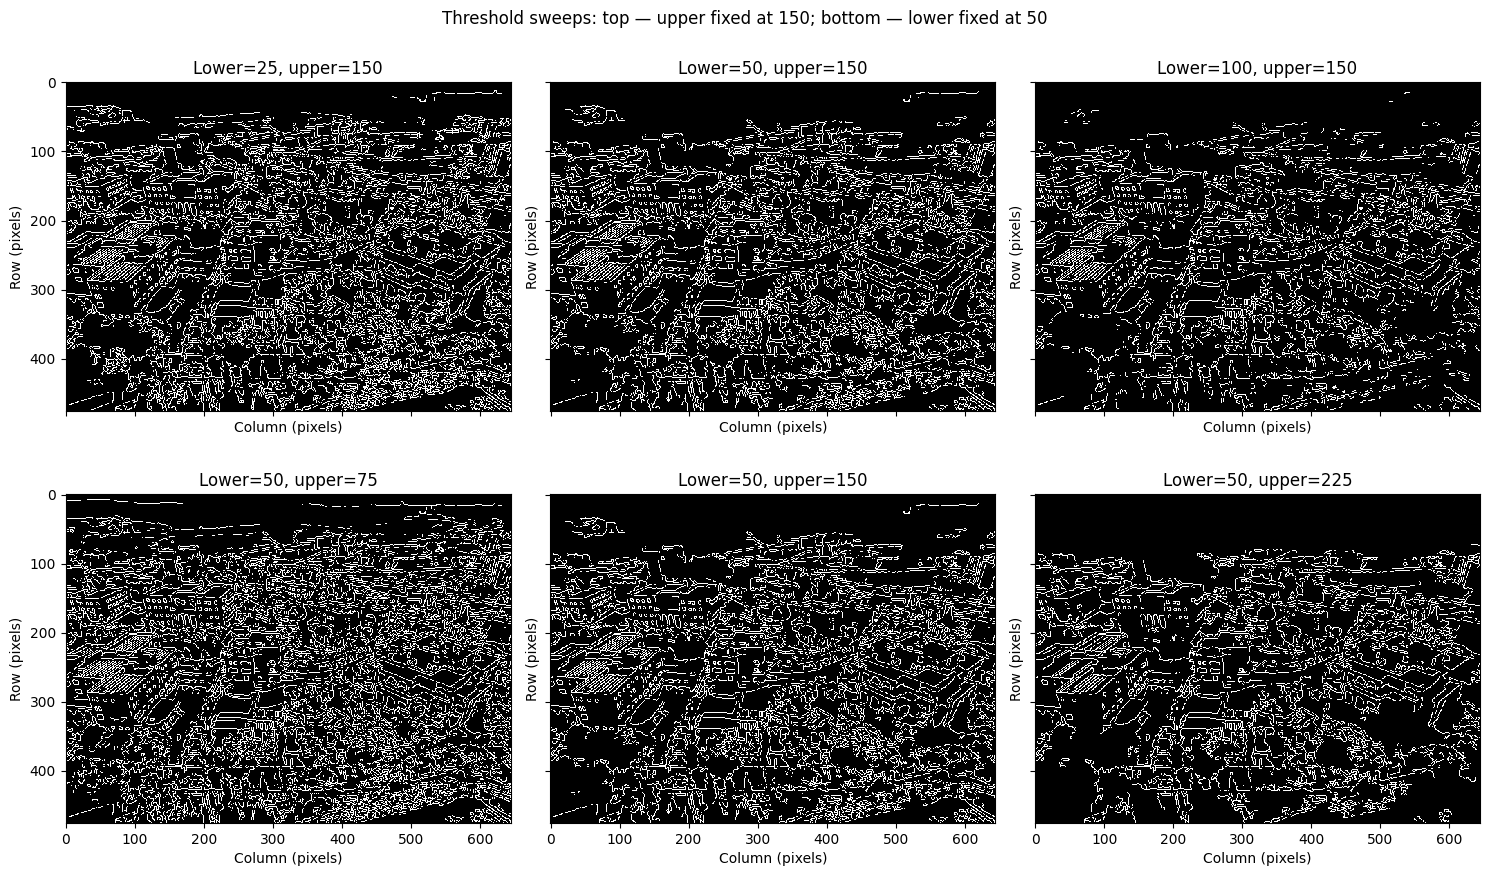

In [18]:
# Sweep one threshold at a time and summarize 8-connected edge components.
threshold_sweeps = [
    [(25, 150), (50, 150), (100, 150)],
    [(50, 75), (50, 150), (50, 225)]
]
connectivity_results = {}
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
print(f"{'Lower':>6} {'Upper':>6} {'Edge pixels':>12} {'Density %':>10} {'Components':>12} {'Largest (px)':>13}")
for row, pairs in enumerate(threshold_sweeps):
    for column, (low, high) in enumerate(pairs):
        trial_edges = cv2.Canny(smoothed_gray, low, high,
                               apertureSize=sobel_aperture, L2gradient=use_l2_gradient)
        count, labels, stats, centroids = cv2.connectedComponentsWithStats(
            trial_edges, connectivity=8
        )
        component_sizes = stats[1:, cv2.CC_STAT_AREA]
        largest_component = int(component_sizes.max()) if component_sizes.size else 0
        trial_count = int(np.count_nonzero(trial_edges))
        connectivity_results[(low, high)] = trial_edges
        print(f"{low:6d} {high:6d} {trial_count:12,d} {100 * trial_count / trial_edges.size:10.2f} {count - 1:12,d} {largest_component:13,d}")
        ax = axes[row, column]
        ax.imshow(trial_edges, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax.set_title(f"Lower={low}, upper={high}")
        ax.set_xlabel("Column (pixels)")
        ax.set_ylabel("Row (pixels)")
fig.suptitle("Threshold sweeps: top — upper fixed at 150; bottom — lower fixed at 50")
plt.tight_layout()
plt.show()

**Reading the output:** `connectedComponentsWithStats` returns labels and component statistics. Label 0 is background, so `count - 1` excludes it; `stats[1:, cv2.CC_STAT_AREA]` selects foreground component sizes. Size counts pixels, not geometric contour length. `centroids` are component mean positions and are unused here.

**Expected mechanism:** Lowering the lower threshold admits weaker links to existing strong seeds and can join fragments; raising it can remove links and fragment or delete contours. Lowering the upper threshold introduces more strong seeds and can retain previously unseeded candidate components; raising it can remove components lacking a sufficiently strong seed. These changes can increase or decrease the total component count, so that count alone cannot prove improved continuity.

**Observed results:** With upper=150, raising the lower threshold from 25 to 100 reduces edge pixels from 53,098 to 33,531, raises component count from 594 to 969, and reduces the largest component from 2,319 to 834 pixels, consistent with loss of weak connecting segments. With lower=50, raising the upper threshold from 75 to 225 reduces component count from 1,832 to 321 while the largest remains 1,547 pixels: many components lose their seeds, rather than the remaining contours necessarily becoming better connected.

#### 6.2 Edge localization

**Localization** is how closely a detected edge position matches the true intensity boundary. Here, smoothing and derivative settings remain fixed: changing hysteresis thresholds selects among the same thinned candidate positions rather than recomputing their locations. It can remove a weak contour or retain a nearby competing response, affecting which boundary is visible.

A **pixel mask** is a Boolean array marking selected coordinates. Compare a relaxed threshold pair with a stricter pair: count shared coordinates and strict-only coordinates. A zero strict-only count supports subset selection for these runs; it does not measure localization error against a true boundary.

For a magnified view, a **region of interest (ROI)** selects rows 160–299 and columns 250–429 using end-exclusive slices. Overlay colors distinguish shared edge pixels (white), pixels retained only at lower=25 (cyan), and pixels retained only at lower=100 (magenta).

           Relaxed -> stricter  Shared pixels  Stricter-only
        (25, 150) -> (50, 150)         45,729              0
       (50, 150) -> (100, 150)         33,531              0
         (50, 75) -> (50, 150)         45,729              0
        (50, 150) -> (50, 225)         34,782              0


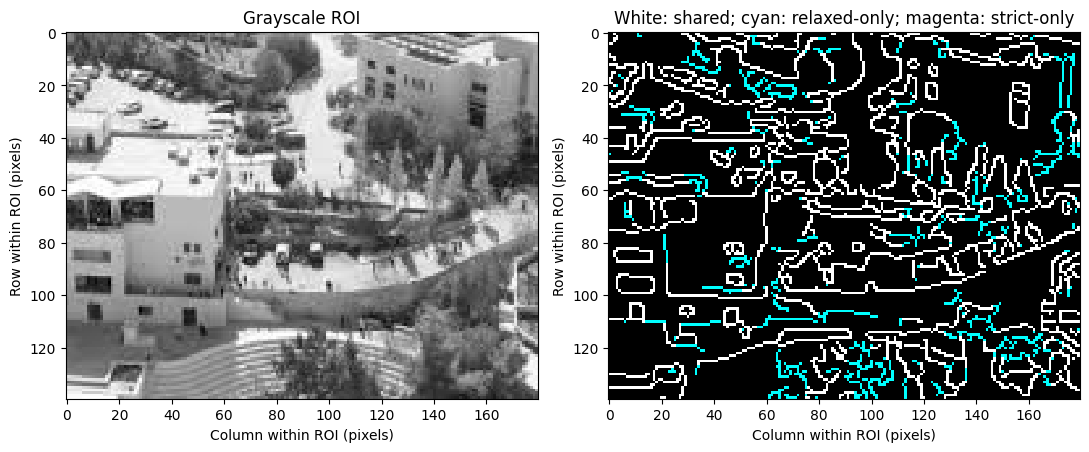

In [19]:
# Compare edge coordinates under stricter thresholds and magnify a fixed region.
ordered_threshold_pairs = [
    ((25, 150), (50, 150)), ((50, 150), (100, 150)),
    ((50, 75), (50, 150)), ((50, 150), (50, 225))
]
print(f"{'Relaxed -> stricter':>30} {'Shared pixels':>14} {'Stricter-only':>14}")
for relaxed_pair, strict_pair in ordered_threshold_pairs:
    relaxed_mask = connectivity_results[relaxed_pair] > 0
    strict_mask = connectivity_results[strict_pair] > 0
    shared_count = np.count_nonzero(relaxed_mask & strict_mask)
    strict_only_count = np.count_nonzero(strict_mask & ~relaxed_mask)
    print(f"{str(relaxed_pair) + ' -> ' + str(strict_pair):>30} {shared_count:14,d} {strict_only_count:14,d}")
roi_rows, roi_columns = slice(160, 300), slice(250, 430)
relaxed_roi = connectivity_results[(25, 150)][roi_rows, roi_columns] > 0
strict_roi = connectivity_results[(100, 150)][roi_rows, roi_columns] > 0
coordinate_overlay = np.zeros((*relaxed_roi.shape, 3), dtype=np.uint8)
coordinate_overlay[relaxed_roi & strict_roi] = [255, 255, 255]
coordinate_overlay[relaxed_roi & ~strict_roi] = [0, 255, 255]
coordinate_overlay[strict_roi & ~relaxed_roi] = [255, 0, 255]
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(gray[roi_rows, roi_columns], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[0].set_title("Grayscale ROI")
axes[1].imshow(coordinate_overlay, interpolation="nearest")
axes[1].set_title("White: shared; cyan: relaxed-only; magenta: strict-only")
for ax in axes:
    ax.set_xlabel("Column within ROI (pixels)")
    ax.set_ylabel("Row within ROI (pixels)")
plt.tight_layout()
plt.show()

**Interpretation:** In these controlled runs, stricter settings retain a subset of the relaxed edge coordinates (see the stricter-only counts). Shared responses remain at identical pixel positions, while weaker segments disappear. This is selection and loss of coverage, not evidence that the retained edges move toward a true boundary. Smoothing scale, derivative estimation, and non-maximum suppression govern the candidate positions. Without annotated boundaries, we cannot report localization error or claim that higher thresholds improve positional accuracy.

#### 6.3 False-positive detections

A **false positive (FP)** is a detected edge that does not match a target edge in a labeled reference. A **false negative (FN)** is a target edge that the detector misses. **Ground truth** is the annotated reference defining which boundaries count as targets.

Texture (repeated fine intensity changes) and shadows can produce genuine image gradients without indicating the object boundaries of interest. They are not automatically false positives: the judgment depends on the target definition. Here, visual inspection focuses on recognizable building and path boundaries; no pixel-level ground truth is available.

Lower thresholds can admit noise-driven responses and additional texture; higher thresholds suppress many weak responses but can also discard valid low-contrast boundaries. The following fixed ROI samples vegetation and foreground texture. It varies only the upper threshold (75, 150, 225), keeping the lower at 50 and all preprocessing unchanged. Counts of added or removed pixels describe sensitivity, not verified FP/FN counts.

Texture ROI: rows 330–459, columns 50–299
 Lower  Upper  ROI edges  ROI density %  Added vs baseline  Removed vs baseline
    50     75      6,439          19.81             12,791                    0
    50    150      4,919          15.14                  0                    0
    50    225      3,679          11.32                  0               10,947


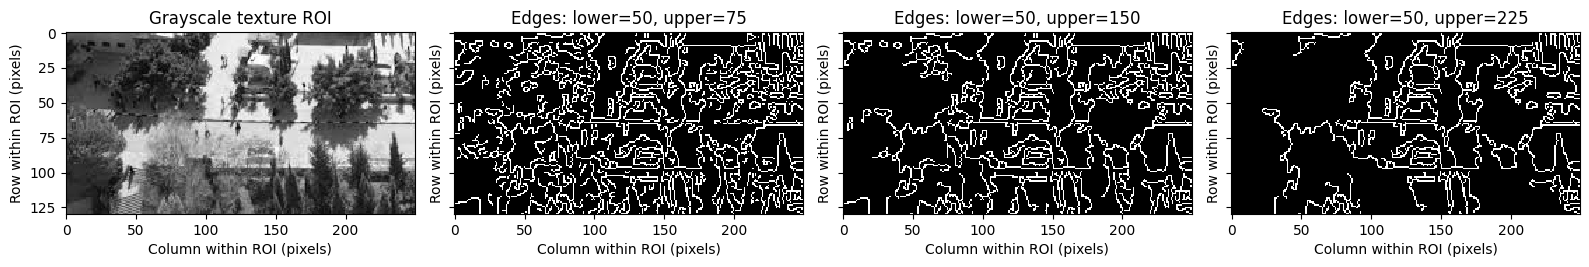

Added/removed counts use the full image; ROI counts use the displayed crop.
No annotated reference: FP counts, FN counts, and false-positive rates are not measured.


In [20]:
# Inspect textured foreground responses without treating extra edge pixels as confirmed errors.
texture_rows, texture_columns = slice(330, 460), slice(50, 300)
fp_pairs = [(50, 75), (50, 150), (50, 225)]
baseline_mask = connectivity_results[(50, 150)] > 0
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
axes[0].imshow(gray[texture_rows, texture_columns], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[0].set_title("Grayscale texture ROI")
print("Texture ROI: rows 330–459, columns 50–299")
print(f"{'Lower':>6} {'Upper':>6} {'ROI edges':>10} {'ROI density %':>14} {'Added vs baseline':>18} {'Removed vs baseline':>20}")
for ax, pair in zip(axes[1:], fp_pairs):
    trial_mask = connectivity_results[pair] > 0
    roi_mask = trial_mask[texture_rows, texture_columns]
    added_pixels = np.count_nonzero(trial_mask & ~baseline_mask)
    removed_pixels = np.count_nonzero(baseline_mask & ~trial_mask)
    print(f"{pair[0]:6d} {pair[1]:6d} {np.count_nonzero(roi_mask):10,d} {100 * np.mean(roi_mask):14.2f} {added_pixels:18,d} {removed_pixels:20,d}")
    ax.imshow(roi_mask, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(f"Edges: lower={pair[0]}, upper={pair[1]}")
for ax in axes:
    ax.set_xlabel("Column within ROI (pixels)")
    ax.set_ylabel("Row within ROI (pixels)")
plt.tight_layout()
plt.show()
print("Added/removed counts use the full image; ROI counts use the displayed crop.")
print("No annotated reference: FP counts, FN counts, and false-positive rates are not measured.")

**Interpretation:** Compare the cropped edge maps against the grayscale texture: stricter settings remove many responses invegetation, but a cleaner-looking result alone does not establish fewer errors. The full-image threshold sweep also shows loss of weaker contours. Thus threshold selection balances additional responses against missing useful structure; the selected (50, 150) pair is a visual compromise for this image.

**finding:** Thresholds change edge survival and connectivity. With fixed smoothing and derivatives, shared edge coordinates remain unchanged. Without labeled target boundaries, localization error and false-positive rates cannot be quantified from edge density or component counts.

## Task 3: Gaussian Filtering and Comparison

### 1. Apply a Gaussian filter with standard deviation σ = 2√2.

A **Gaussian filter** smooths the image using a normalized, bell-shaped weighting kernel. **Standard deviation** $\sigma$ sets its spatial spread in pixels; **variance** is $\sigma^2$. Here $\sigma=2\sqrt{2}\approx2.8284$ pixels and variance is 8 pixels².

Use the original Task 1 grayscale image, not the Canny-smoothed input. For a reproducible finite kernel, choose radius $r=\lceil3\sigma\rceil$ and odd side length $k=2r+1$, giving 19 × 19. The **ceiling** operation rounds upward; this 3σ support rule is an implementation choice, not an assignment requirement. **Truncation** means omitting the Gaussian's infinite tails.

`astype(np.float64)` converts the stored intensities to 64-bit floating point without rescaling 0–255. It avoids rounding each filtering result back to `uint8`, which would obscure the later comparison. Set equal `sigmaX` and `sigmaY` for equal smoothing in both axes, and explicitly use reflected borders.

In [21]:
# Apply one Gaussian pass to the original grayscale image using explicit support and precision.
gray_float = gray.astype(np.float64)
sigma_single = 2.0 * np.sqrt(2.0)
support_sigmas = 3.0
radius_single = int(np.ceil(support_sigmas * sigma_single))
kernel_single = 2 * radius_single + 1
gaussian_border = cv2.BORDER_REFLECT_101
gaussian_single = cv2.GaussianBlur(
    gray_float, (kernel_single, kernel_single),
    sigmaX=sigma_single, sigmaY=sigma_single, borderType=gaussian_border
)
print("Input source: original Task 1 grayscale image")
print(f"Standard deviation: 2*sqrt(2) = {sigma_single:.8f} pixels")
print(f"Variance: {sigma_single**2:.4f} pixels squared")
print(f"Support rule: radius = ceil({support_sigmas:g} * sigma)")
print(f"Kernel radius: {radius_single} pixels; kernel size: {kernel_single} x {kernel_single}")
print("Border handling: BORDER_REFLECT_101")
print(f"Input/output data type: {gray_float.dtype} / {gaussian_single.dtype}")
print(f"Output shape: {gaussian_single.shape}")
print(f"Observed output range: [{gaussian_single.min():.4f}, {gaussian_single.max():.4f}]")

Input source: original Task 1 grayscale image
Standard deviation: 2*sqrt(2) = 2.82842712 pixels
Variance: 8.0000 pixels squared
Support rule: radius = ceil(3 * sigma)
Kernel radius: 9 pixels; kernel size: 19 x 19
Border handling: BORDER_REFLECT_101
Input/output data type: float64 / float64
Output shape: (476, 645)
Observed output range: [17.1685, 255.0000]


**Interpretation:** This produces one smoothed floating-point image with unchanged spatial dimensions. Fractional values are retained for the subsequent two-pass comparison; the original `gray` array remains unchanged.

### 2. Apply a Gaussian filter twice, using σ = 2 for each operation.

A **pass** is one application of a filter. Start from `gray_float`, the original Task 1 grayscale image converted to floating point, then filter the first result again. Filtering the original independently twice would not accumulate smoothing.

For ideal continuous Gaussian convolution, **variances add**:

$$\sigma_{\mathrm{effective}}^2=\sigma_1^2+\sigma_2^2=2^2+2^2=8,\qquad \sigma_{\mathrm{effective}}=2\sqrt{2}.$$

The standard deviations themselves do not add. This predicts agreement with Step 1 in the ideal continuous setting. Finite sampled kernels, borders, and numerical arithmetic can produce practical differences, investigated in Step 6.

Apply the same support rule $r=\lceil3\sigma\rceil$, giving a 13 × 13 kernel for each pass. Keep `float64` throughout and the same border rule as Step 1. The composed finite kernel has a wider support than either individual kernel; it is not simply a single 13 × 13 filter.

In [22]:
# Apply two successive sigma-2 Gaussian passes to the original floating-point grayscale image.
sigma_pass = 2.0
radius_pass = int(np.ceil(support_sigmas * sigma_pass))
kernel_pass = 2 * radius_pass + 1
gaussian_pass1 = cv2.GaussianBlur(
    gray_float, (kernel_pass, kernel_pass),
    sigmaX=sigma_pass, sigmaY=sigma_pass, borderType=gaussian_border
)
gaussian_twice = cv2.GaussianBlur(
    gaussian_pass1, (kernel_pass, kernel_pass),
    sigmaX=sigma_pass, sigmaY=sigma_pass, borderType=gaussian_border
)
sigma_effective = np.sqrt(sigma_pass**2 + sigma_pass**2)
print("Pass 1 input: original Task 1 grayscale image converted to float64")
print("Pass 2 input: output of pass 1")
print(f"Sigma per pass: {sigma_pass:.1f} pixels; variance per pass: {sigma_pass**2:.1f} pixels squared")
print(f"Kernel per pass: {kernel_pass} x {kernel_pass}; radius: {radius_pass} pixels")
print(f"Ideal combined variance: {2 * sigma_pass**2:.1f} pixels squared")
print(f"Ideal effective sigma: {sigma_effective:.8f} pixels")
print("Border handling for both passes: BORDER_REFLECT_101")
for label, result in (("Pass 1", gaussian_pass1), ("Pass 2", gaussian_twice)):
    print(f"{label}: shape={result.shape}, dtype={result.dtype}, range=[{result.min():.4f}, {result.max():.4f}]")

Pass 1 input: original Task 1 grayscale image converted to float64
Pass 2 input: output of pass 1
Sigma per pass: 2.0 pixels; variance per pass: 4.0 pixels squared
Kernel per pass: 13 x 13; radius: 6 pixels
Ideal combined variance: 8.0 pixels squared
Ideal effective sigma: 2.82842712 pixels
Border handling for both passes: BORDER_REFLECT_101
Pass 1: shape=(476, 645), dtype=float64, range=[14.1084, 255.0000]
Pass 2: shape=(476, 645), dtype=float64, range=[17.1629, 255.0000]


**Interpretation:** `gaussian_twice` stores the sequential two-pass result. Its ideal effective standard deviation matches Step 1; numerical equality of the actual images remains to be tested in the following steps.

### 3. Display both resulting images.

Use the same grayscale colormap and **display limits** (`vmin=0`, `vmax=255`) for both floating-point results. The conversion to `float64` did not rescale the intensities to 0–1. Fixed limits avoid independent contrast stretching that could distort the visual comparison. Displaying the arrays does not round or overwrite their values.

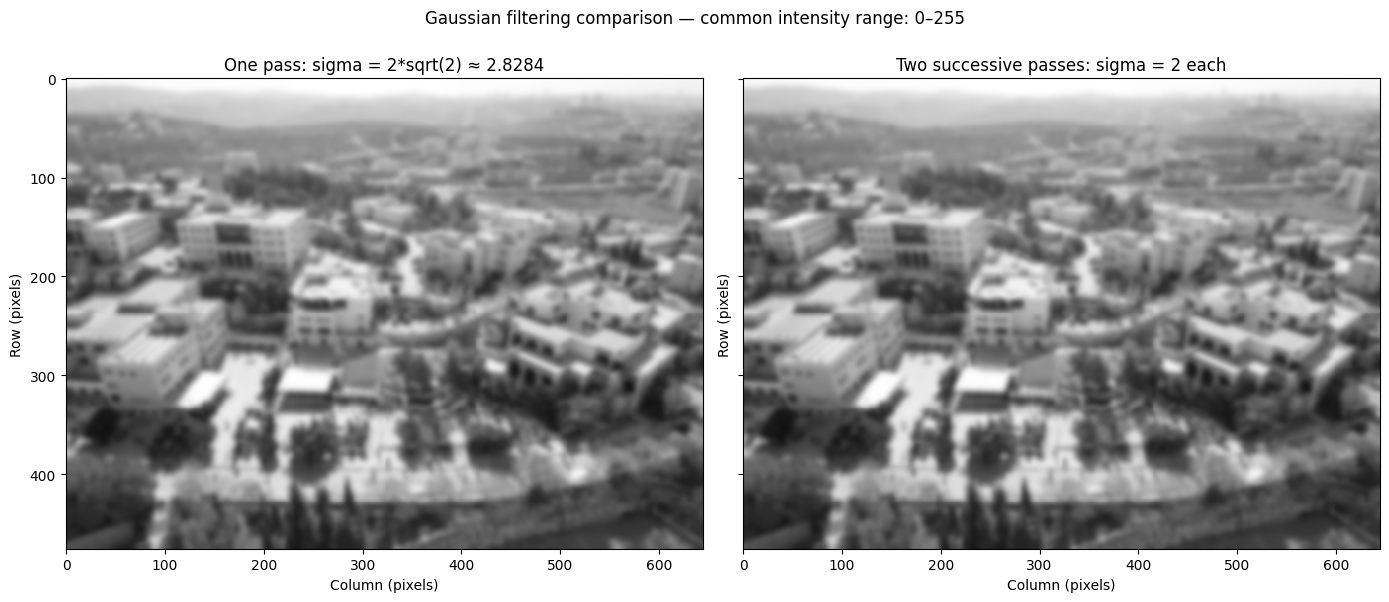

In [23]:
# Display the single-pass and two-pass Gaussian results using identical intensity scales.
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
gaussian_display_results = [
    (gaussian_single, f"One pass: sigma = 2*sqrt(2) ≈ {sigma_single:.4f}"),
    (gaussian_twice, "Two successive passes: sigma = 2 each")
]
for ax, (result, title) in zip(axes, gaussian_display_results):
    ax.imshow(result, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("Column (pixels)")
    ax.set_ylabel("Row (pixels)")
fig.suptitle("Gaussian filtering comparison — common intensity range: 0–255")
plt.tight_layout()
plt.show()

**Observation:** At this display scale, the two results appear very similar: both soften fine texture and edges while retaining the overall scene structure. Visual similarity does not establish pixel-wise equality; the next step computes their absolute difference.

### 4. Compute the absolute pixel-wise difference between the two filtered images.

A **pixel-wise difference** compares values at matching row and column coordinates. The **absolute value** removes the sign, so the difference measures the size of a disagreement rather than which result is brighter:

$$D(x,y)=\left|I_{\mathrm{single}}(x,y)-I_{\mathrm{twice}}(x,y)\right|.$$

Retain `float64` values during subtraction: converting to `uint8` would discard fractional differences, and unsigned subtraction can wrap around. **Mean absolute difference** averages $D$ across all pixels; **maximum absolute difference** reports the largest disagreement. Both use the original 0–255 intensity units, not percentages.

A **tolerance** is a chosen numerical cutoff for reporting small differences. We additionally count values above $10^{-6}$ intensity units; this is a reporting convention, not a perceptual threshold.

In [24]:
# Compute absolute differences in floating point and report their size and frequency.
absolute_difference = np.abs(gaussian_single - gaussian_twice)
difference_tolerance = 1e-6
exact_nonzero_count = np.count_nonzero(absolute_difference)
above_tolerance_count = np.count_nonzero(absolute_difference > difference_tolerance)
print(f"Difference shape: {absolute_difference.shape}; dtype: {absolute_difference.dtype}")
print("Difference units: intensity units on the original 0–255 scale")
print(f"Minimum absolute difference: {absolute_difference.min():.10f}")
print(f"Maximum absolute difference: {absolute_difference.max():.10f}")
print(f"Mean absolute difference: {absolute_difference.mean():.10f}")
print(f"Exactly nonzero differences: {exact_nonzero_count:,} / {absolute_difference.size:,}")
print(f"Reporting tolerance: {difference_tolerance:g} intensity units")
print(f"Differences above tolerance: {above_tolerance_count:,} ({100 * above_tolerance_count / absolute_difference.size:.2f}%)")

Difference shape: (476, 645); dtype: float64
Difference units: intensity units on the original 0–255 scale
Minimum absolute difference: 0.0000000000
Maximum absolute difference: 0.2165555895
Mean absolute difference: 0.0257480288
Exactly nonzero differences: 306,860 / 307,020
Reporting tolerance: 1e-06 intensity units
Differences above tolerance: 306,762 (99.92%)


**Interpretation:** A large count of nonzero differences does not by itself mean a large discrepancy; floating-point arrays can differ by tiny amounts at many pixels. Use the reported magnitudes together with the difference image in the next step.

### 5. Display the difference image and briefly explain the observed results.

**Display scaling** maps numerical values to colors without changing the stored difference array. The left panel uses the original 0–255 intensity scale; the right panel expands the display range to 0–the observed maximum difference. A **colorbar** identifies the numerical value represented by each display color. The expanded view reveals spatial patterns but visually exaggerates their small amplitude.

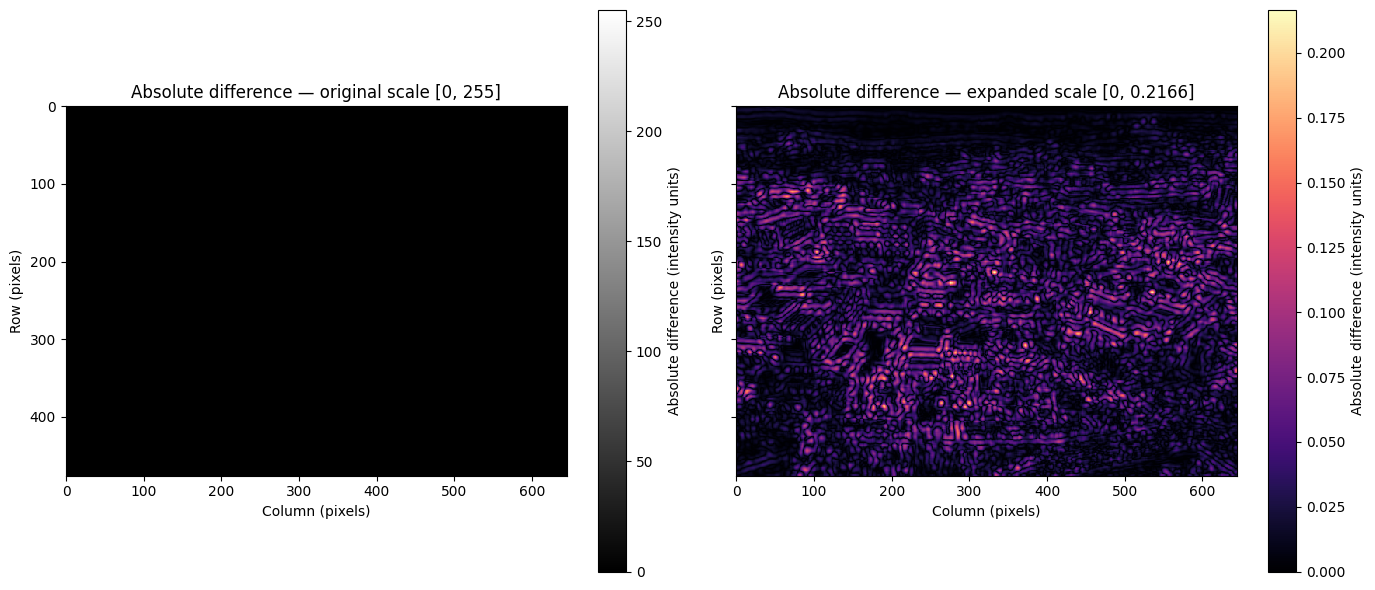

Maximum difference as a percentage of the 255-unit range: 0.0849%
Expanded display changes only color mapping; difference values remain unchanged.


In [25]:
# Show absolute differences on the original scale and an explicitly expanded scale.
max_difference = float(absolute_difference.max())
expanded_limit = max_difference if max_difference > 0 else 1.0
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
original_scale_plot = axes[0].imshow(
    absolute_difference, cmap="gray", vmin=0, vmax=255, interpolation="nearest"
)
axes[0].set_title("Absolute difference — original scale [0, 255]")
fig.colorbar(original_scale_plot, ax=axes[0], label="Absolute difference (intensity units)")
expanded_scale_plot = axes[1].imshow(
    absolute_difference, cmap="magma", vmin=0, vmax=expanded_limit, interpolation="nearest"
)
axes[1].set_title(f"Absolute difference — expanded scale [0, {expanded_limit:.4f}]")
fig.colorbar(expanded_scale_plot, ax=axes[1], label="Absolute difference (intensity units)")
for ax in axes:
    ax.set_xlabel("Column (pixels)")
    ax.set_ylabel("Row (pixels)")
plt.tight_layout()
plt.show()
print(f"Maximum difference as a percentage of the 255-unit range: {100 * max_difference / 255:.4f}%")
print("Expanded display changes only color mapping; difference values remain unchanged.")

**Observation:** The original-scale difference image appears nearly black because the maximum discrepancy is about 0.2166 intensity units (0.0849% of the full 255-unit range); the mean is about 0.02575. The expanded view reveals nonuniform differences around scene detail and intensity transitions. Bright regions in that view indicate relatively larger discrepancies, not differences approaching 255.

The ideal variance-addition relation explains the similar smoothing, but the implemented finite filters are not numerically identical. The following step investigates truncation, sampling, normalization, borders, and numerical precision separately.

### 6. Investigate why the implementations may produce non-zero differences.

#### 6.1 Finite kernel truncation

An ideal Gaussian has **infinite support**: its weights are nonzero arbitrarily far from the center. **Finite support** limits the offsets included in a practical kernel. **Truncation** omits the outer tails; the retained sampled weights are then normalized to sum to one.

Vary only the support multiplier $t$ in $r=\lceil t\sigma\rceil$, using 2, 3, and 4. Keep the input, `float64` precision, sigma values, normalized OpenCV kernels, and reflected border handling fixed. The single-pass and composed two-pass kernels lose different tails, so finite implementations need not obey the ideal variance-addition identity exactly.

The **interior** excludes a border margin equal to the larger effective radius: $\max(r_{single},2r_{pass})$. This removes dependence on extrapolated pixels for both filtering routes. Interior differences help distinguish finite-kernel effects from boundary effects; residual sampling and arithmetic effects remain.

In [26]:
# Vary Gaussian support while keeping sigma, precision, normalization, and borders fixed.
truncation_results = []
print(f"{'Support':>8} {'Single k':>10} {'Pass k':>8} {'Margin':>8} {'Full mean':>13} {'Full max':>13} {'Interior mean':>15} {'Interior max':>14}")
for support in (2.0, 3.0, 4.0):
    single_radius = int(np.ceil(support * sigma_single))
    pass_radius = int(np.ceil(support * sigma_pass))
    single_size = 2 * single_radius + 1
    pass_size = 2 * pass_radius + 1
    single_trial = cv2.GaussianBlur(gray_float, (single_size, single_size),
                                  sigmaX=sigma_single, sigmaY=sigma_single,
                                  borderType=gaussian_border)
    first_trial = cv2.GaussianBlur(gray_float, (pass_size, pass_size),
                                 sigmaX=sigma_pass, sigmaY=sigma_pass,
                                 borderType=gaussian_border)
    twice_trial = cv2.GaussianBlur(first_trial, (pass_size, pass_size),
                                 sigmaX=sigma_pass, sigmaY=sigma_pass,
                                 borderType=gaussian_border)
    trial_difference = np.abs(single_trial - twice_trial)
    margin = max(single_radius, 2 * pass_radius)
    interior_difference = trial_difference[margin:-margin, margin:-margin]
    truncation_results.append((support, float(trial_difference.mean()),
                               float(interior_difference.mean())))
    print(f"{support:7.0f}σ {single_size:10d} {pass_size:8d} {margin:8d} {trial_difference.mean():13.8f} {trial_difference.max():13.8f} {interior_difference.mean():15.8f} {interior_difference.max():14.8f}")
print("Difference statistics are in original intensity units; interior margins are pixels.")

 Support   Single k   Pass k   Margin     Full mean      Full max   Interior mean   Interior max
      2σ         13        9        8    0.28791171    2.77464012      0.29392383     2.77464012
      3σ         19       13       12    0.02574803    0.21655559      0.02650613     0.21655559
      4σ         25       17       16    0.00070600    0.00570351      0.00073351     0.00570351
Difference statistics are in original intensity units; interior margins are pixels.


**Interpretation:** Enlarging support retains more of each Gaussian tail and tests how strongly the discrepancy depends on truncation. The baseline uses 3σ support. Differences remaining with wider support need not be rounding errors: sampling the continuous Gaussian on an integer grid also changes its composition behavior. This experiment varies support; it does not independently isolate every source of error.

**Observed result:** Full-image mean absolute differences decrease from 0.28791 (2σ) to 0.02575 (3σ) and 0.000706 (4σ). The same trend occurs in the interior, supporting a substantial contribution from finite support in this setup rather than a purely boundary-driven discrepancy. Each support uses its own sufficient interior margin.

#### 6.2 Discrete sampling

**Sampling** evaluates a continuous function at selected positions. A **pixel grid** uses integer offsets with unit spacing. A sampled Gaussian uses weights proportional to $\exp[-n^2/(2\sigma^2)]$ at integer $n$, then normalizes their sum.

Continuous convolution integrates over all positions, whereas **discrete convolution** sums over grid points. Sampling after continuous convolution is generally not identical to convolving already sampled kernels. Thus two sampled Gaussian kernels need not compose to exactly the sampled Gaussian with summed nominal variances.

Test the one-dimensional kernels directly to avoid image-border effects; the two-dimensional Gaussian is separable, meaning its kernel is a product of one-dimensional kernels. Use wide 8σ support to make omitted tails very small, and `float64` arithmetic. Include σ=0.5 and σ=1 as illustrative cases, plus the assignment's σ=2. `np.convolve(..., mode="full")` retains the complete composed finite kernel. Zero-padding aligns both kernel centers on the same integer-offset grid.

In [27]:
# Compare composed and directly sampled Gaussian kernels with negligible tail truncation.
sampling_kernel_results = []
print(f"{'Sigma per pass':>15} {'Composed sum':>15} {'Direct sum':>15} {'Max coefficient gap':>21}")
for sample_sigma in (0.5, 1.0, 2.0):
    sample_radius = int(np.ceil(8 * sample_sigma))
    sample_offsets = np.arange(-sample_radius, sample_radius + 1, dtype=np.float64)
    sampled_kernel = np.exp(-sample_offsets**2 / (2 * sample_sigma**2))
    sampled_kernel /= sampled_kernel.sum()
    composed_kernel = np.convolve(sampled_kernel, sampled_kernel, mode="full")
    direct_sigma = np.sqrt(2) * sample_sigma
    direct_radius = int(np.ceil(8 * direct_sigma))
    direct_offsets = np.arange(-direct_radius, direct_radius + 1, dtype=np.float64)
    direct_kernel = np.exp(-direct_offsets**2 / (2 * direct_sigma**2))
    direct_kernel /= direct_kernel.sum()
    common_radius = max(2 * sample_radius, direct_radius)
    composed_aligned = np.pad(composed_kernel, common_radius - 2 * sample_radius)
    direct_aligned = np.pad(direct_kernel, common_radius - direct_radius)
    coefficient_gap = float(np.max(np.abs(composed_aligned - direct_aligned)))
    sampling_kernel_results.append((sample_sigma, coefficient_gap))
    print(f"{sample_sigma:15.1f} {composed_kernel.sum():15.12f} {direct_kernel.sum():15.12f} {coefficient_gap:21.12e}")
print("Kernel coefficients are dimensionless weights, not image intensity differences.")

 Sigma per pass    Composed sum      Direct sum   Max coefficient gap
            0.5  1.000000000000  1.000000000000    7.722592282874e-02
            1.0  1.000000000000  1.000000000000    2.917866383267e-05
            2.0  1.000000000000  1.000000000000    4.163336342344e-17
Kernel coefficients are dimensionless weights, not image intensity differences.


**Interpretation:** A clear coefficient discrepancy for narrow σ demonstrates that normalized sampled Gaussian kernels do not generally obey the continuous composition identity. For σ=2, the wide-support discrepancy may be near floating-point precision; this does not justify attributing the baseline image difference mainly to sampling. The earlier support sweep provides stronger evidence for truncation in the assignment's 3σ setup. This experiment greatly reduces truncation but does not eliminate finite-support and arithmetic effects entirely.

#### 6.3 Kernel normalization

**Normalization** divides every kernel coefficient by the sum of its coefficients:

$$K_{normalized}(i,j)=\frac{K_{raw}(i,j)}{\sum_{u,v}K_{raw}(u,v)}.$$

The normalized weights sum to 1. This sum is the filter's **DC gain**, meaning its response multiplier for a constant image. A unit DC gain preserves constant intensity when boundary extension also preserves the constant. It does not mean every image's global mean is exactly preserved under every boundary rule.

OpenCV's Gaussian coefficients are normalized. Because a Gaussian is **separable**, its two-dimensional kernel is the outer product of two one-dimensional kernels; the 2D sum is the product of their sums. The **outer product** multiplies every coefficient of one vector by every coefficient of the other.

After truncation, normalizing different retained supports changes the relative scaling of their coefficients. Both resulting filters can sum to 1 yet have different shapes. The following check tests the assignment's normalized kernels and a constant-image response, not a claim that missing normalization caused the observed discrepancy.

In [28]:
# Verify Gaussian kernel sums and constant-intensity preservation for both filtering routes.
normal_kernel_single = cv2.getGaussianKernel(kernel_single, sigma_single, cv2.CV_64F).ravel()
normal_kernel_pass = cv2.getGaussianKernel(kernel_pass, sigma_pass, cv2.CV_64F).ravel()
normal_kernel_composed = np.convolve(normal_kernel_pass, normal_kernel_pass, mode="full")
print(f"Single-pass 1D kernel sum: {normal_kernel_single.sum():.16f}")
print(f"Per-pass 1D kernel sum: {normal_kernel_pass.sum():.16f}")
print(f"Composed two-pass 1D kernel sum: {normal_kernel_composed.sum():.16f}")
print(f"Single-pass 2D kernel sum: {np.outer(normal_kernel_single, normal_kernel_single).sum():.16f}")
print(f"Per-pass 2D kernel sum: {np.outer(normal_kernel_pass, normal_kernel_pass).sum():.16f}")
constant_image = np.full((64, 64), 100.0, dtype=np.float64)
constant_single = cv2.GaussianBlur(constant_image, (kernel_single, kernel_single),
                                  sigmaX=sigma_single, sigmaY=sigma_single,
                                  borderType=gaussian_border)
constant_first = cv2.GaussianBlur(constant_image, (kernel_pass, kernel_pass),
                                 sigmaX=sigma_pass, sigmaY=sigma_pass,
                                 borderType=gaussian_border)
constant_twice = cv2.GaussianBlur(constant_first, (kernel_pass, kernel_pass),
                                 sigmaX=sigma_pass, sigmaY=sigma_pass,
                                 borderType=gaussian_border)
print("Constant input: 100 intensity units; border: BORDER_REFLECT_101")
print(f"Single-pass maximum deviation from 100: {np.max(np.abs(constant_single - 100)):.12e}")
print(f"Two-pass maximum deviation from 100: {np.max(np.abs(constant_twice - 100)):.12e}")

Single-pass 1D kernel sum: 0.9999999999999999
Per-pass 1D kernel sum: 1.0000000000000000
Composed two-pass 1D kernel sum: 1.0000000000000004
Single-pass 2D kernel sum: 1.0000000000000000
Per-pass 2D kernel sum: 1.0000000000000002
Constant input: 100 intensity units; border: BORDER_REFLECT_101
Single-pass maximum deviation from 100: 1.421085471520e-14
Two-pass maximum deviation from 100: 4.263256414561e-14


**Interpretation:** Kernel sums near 1 and constant-image deviations near floating-point precision confirm normalization and constant preservation for these settings. They do not prove that the single and composed kernels match coefficient by coefficient. Renormalization of differently truncated kernels contributes to their shape differences, while failure to normalize would additionally change constant intensity.

#### 6.4 Boundary handling

**Boundary handling** specifies values outside the image when a filter neighborhood extends beyond its borders. **Extrapolation** estimates these unavailable values from a rule; they are not observed scene pixels.

| OpenCV rule | Extension outside the image |
| --- | --- |
| `BORDER_REFLECT_101` | Reflect values without repeating the boundary pixel. |
| `BORDER_REPLICATE` | Repeat the nearest boundary pixel. |
| `BORDER_CONSTANT` | Use zero for GaussianBlur's constant border. |

Keep the baseline kernels, sigma values, and `float64` input unchanged. Apply the selected rule on every pass. In the two-pass route, the second pass extrapolates the already filtered image; this can differ from filtering one consistently extended original image. The effect depends on the rule; reflection can be compatible with composition, so repeated filtering does not necessarily introduce an extra boundary discrepancy.

Define the **border band** as all pixels within 12 pixels of an image edge, using $\max(9,2\times6)=12$, the larger effective kernel radius. The **interior** is the complement and cannot depend on extrapolated values for these kernels.

In [29]:
# Compare Gaussian routes under three boundary rules, separating border and interior errors.
boundary_margin = max(radius_single, 2 * radius_pass)
border_band = np.ones(gray.shape, dtype=bool)
border_band[boundary_margin:-boundary_margin, boundary_margin:-boundary_margin] = False
boundary_modes = [
    ("REFLECT_101", cv2.BORDER_REFLECT_101),
    ("REPLICATE", cv2.BORDER_REPLICATE),
    ("CONSTANT_ZERO", cv2.BORDER_CONSTANT)
]
boundary_differences = {}
print(f"Border band width: {boundary_margin} pixels")
print(f"Border pixels: {np.count_nonzero(border_band):,}; interior pixels: {np.count_nonzero(~border_band):,}")
print(f"{'Border rule':>15} {'Border mean':>14} {'Border max':>14} {'Interior mean':>15} {'Interior max':>14}")
for boundary_name, boundary_mode in boundary_modes:
    boundary_single = cv2.GaussianBlur(gray_float, (kernel_single, kernel_single),
                                      sigmaX=sigma_single, sigmaY=sigma_single,
                                      borderType=boundary_mode)
    boundary_first = cv2.GaussianBlur(gray_float, (kernel_pass, kernel_pass),
                                     sigmaX=sigma_pass, sigmaY=sigma_pass,
                                     borderType=boundary_mode)
    boundary_twice = cv2.GaussianBlur(boundary_first, (kernel_pass, kernel_pass),
                                     sigmaX=sigma_pass, sigmaY=sigma_pass,
                                     borderType=boundary_mode)
    boundary_difference = np.abs(boundary_single - boundary_twice)
    boundary_differences[boundary_name] = boundary_difference
    border_values = boundary_difference[border_band]
    interior_values = boundary_difference[~border_band]
    print(f"{boundary_name:>15} {border_values.mean():14.8f} {border_values.max():14.8f} {interior_values.mean():15.8f} {interior_values.max():14.8f}")
print("All statistics are absolute differences in original intensity units.")

Border band width: 12 pixels
Border pixels: 26,328; interior pixels: 280,692
    Border rule    Border mean     Border max   Interior mean   Interior max
    REFLECT_101     0.01766564     0.16215195      0.02650613     0.21655559
      REPLICATE     0.11626865     8.70642668      0.02650613     0.21655559
  CONSTANT_ZERO     2.65574281    27.20059916      0.02650613     0.21655559
All statistics are absolute differences in original intensity units.


**Interpretation:** Compare the border statistics across rules while checking that interior statistics remain the same. Zero extension creates an artificial intensity drop outside the image, and repeated re-extension of the intermediate image can increase boundary discrepancies. Repeating boundary values can also alter the two-pass behavior. These are consequences of the chosen extension model, not evidence that the continuous Gaussian identity is false. The reflected baseline still has finite-kernel differences throughout the image.

**Observed result:** Mean border discrepancies are approximately 0.01767 (reflection), 0.11627 (replication), and 2.65574 (zero extension). The interior mean is 0.02650613 for every rule. This localizes the effect of changing the extension rule to the expected border region in this experiment.

#### 6.5 Numerical precision

**Floating-point precision** limits how accurately fractional values and arithmetic results can be represented. `float32` stores 32 bits per value; `float64` stores 64 and generally reduces rounding error. More precision does not remove finite-kernel or sampling differences.

**Rounding** replaces a result with a nearby representable value. **Quantization** restricts values to discrete levels; `uint8` filtering stores integer intensity values after each pass, discarding fractional information. Two successive integer-output passes can therefore differ from a single pass even beyond kernel-shape effects. Optimized integer implementations may also use different coefficient arithmetic.

Keep kernel sizes, sigma values, and border handling fixed. Compare each route with its corresponding `float64` result as a numerical reference, not an exact ground truth. Convert results to `float64` before subtraction to avoid unsigned wraparound.

In [30]:
# Compare output precision while keeping Gaussian kernels and border handling fixed.
precision_results = {}
print(f"{'Input dtype':>12} {'Route mean gap':>16} {'Route max gap':>16} {'Single vs f64 max':>19} {'Twice vs f64 max':>18}")
for precision_dtype in (np.float64, np.float32, np.uint8):
    precision_input = gray.astype(precision_dtype)
    precision_single = cv2.GaussianBlur(precision_input, (kernel_single, kernel_single),
                                       sigmaX=sigma_single, sigmaY=sigma_single,
                                       borderType=gaussian_border)
    precision_first = cv2.GaussianBlur(precision_input, (kernel_pass, kernel_pass),
                                      sigmaX=sigma_pass, sigmaY=sigma_pass,
                                      borderType=gaussian_border)
    precision_twice = cv2.GaussianBlur(precision_first, (kernel_pass, kernel_pass),
                                      sigmaX=sigma_pass, sigmaY=sigma_pass,
                                      borderType=gaussian_border)
    single_as_float = precision_single.astype(np.float64)
    twice_as_float = precision_twice.astype(np.float64)
    precision_gap = np.abs(single_as_float - twice_as_float)
    single_reference_gap = np.max(np.abs(single_as_float - gaussian_single))
    twice_reference_gap = np.max(np.abs(twice_as_float - gaussian_twice))
    precision_name = np.dtype(precision_dtype).name
    precision_results[precision_name] = (precision_single, precision_twice)
    print(f"{precision_name:>12} {precision_gap.mean():16.10f} {precision_gap.max():16.10f} {single_reference_gap:19.10f} {twice_reference_gap:18.10f}")
print("All gaps are in original intensity units. float64 is a comparison reference, not exact arithmetic.")

 Input dtype   Route mean gap    Route max gap   Single vs f64 max   Twice vs f64 max
     float64     0.0257480288     0.2165555895        0.0000000000       0.0000000000
     float32     0.0257483194     0.2165451050        0.0000784124       0.0000673036
       uint8     0.0768125855     1.0000000000        1.1196425030       0.8572176167
All gaps are in original intensity units. float64 is a comparison reference, not exact arithmetic.


**Interpretation:** Compare the reference gaps to distinguish numerical representation effects from the baseline single-versus-two-pass discrepancy. Integer results include per-pass quantization and possible optimized integer arithmetic, so they do not isolate floating-point rounding alone. A smaller single-versus-two-pass gap after quantization would not establish greater accuracy: rounding can hide fractional discrepancies.

**Task 3 finding:** The outputs are visually similar but not identical. Wider kernel support sharply reduces their discrepancy. Discrete sampling can violate the continuous composition identity, especially for narrow Gaussians; for σ=2 with wide support, the measured kernel gap is near arithmetic precision. Both kernels are normalized, border rules affect the boundary region, and reduced numerical precision adds representation effects. These mechanisms interact rather than forming an independently additive error budget.

**Observed result:** Maximum deviations of the float32 routes from their float64 references are below 0.00008 intensity units. The uint8 routes differ by as much as about 1.12 units from their references, and their mutual maximum gap is 1 unit. Thus the floating-point rounding effect is small relative to the baseline 3σ discrepancy here, while integer storage has a larger effect.

## Task 4: Salt-and-Pepper Noise Removal

### 1. Read uni.jpeg and convert it to grayscale.

Reload the original image to begin this experiment with an unfiltered reference. A **reference image** is the baseline against which later noisy and filtered results will be compared; here it is the decoded original, not a perfectly noise-free measurement of the scene.

**Grayscale** stores one intensity value per pixel. **BGR** means blue, green, red: the channel order returned by `cv2.imread(..., cv2.IMREAD_COLOR)`. `cv2.cvtColor` converts between color representations; `cv2.COLOR_BGR2GRAY` specifies the matching conversion:

$$Y = 0.299R + 0.587G + 0.114B.$$

The unequal weights approximate perceived brightness contributions. The conversion preserves spatial dimensions but loses color information. The output uses **uint8** (unsigned 8-bit integers), representing 256 levels from 0 (black) to 255 (white). Its **observed range** describes the values actually present, rather than every value allowed by the type.

| Name / operation | Meaning |
| --- | --- |
| `task4_image_path` | Path to the original JPEG input. |
| `task4_bgr` | Newly decoded three-channel color array. |
| `clean_gray` | Unfiltered grayscale reference for the noise-removal experiments. “Clean” distinguishes it from the synthetic noise added later. |
| `str(...)` | Converts the Path object into a filename string for OpenCV. |
| `is None` | Detects a failed image read before attempting conversion. |
| `np.array_equal` | Checks that shape and every pixel value match the Task 1 reference. |

We explicitly read color and then convert, matching Task 1. Direct grayscale decoding can use codec-specific conversion and need not give identical values.

In [31]:
# Reload the original image; do not use a Gaussian-filtered result from Task 3.
task4_image_path = DATA_DIR / "uni.jpeg"
task4_bgr = cv2.imread(str(task4_image_path), cv2.IMREAD_COLOR)
if task4_bgr is None:
    raise FileNotFoundError(f"Unable to read image: {task4_image_path}")
clean_gray = cv2.cvtColor(task4_bgr, cv2.COLOR_BGR2GRAY)

assert clean_gray.ndim == 2 and clean_gray.dtype == np.uint8
assert clean_gray.shape == task4_bgr.shape[:2]
assert np.array_equal(clean_gray, gray), "Reloaded reference differs from Task 1."
print(f"Input file: {task4_image_path}")
print("Read mode: cv2.IMREAD_COLOR; channel order: BGR")
print(f"Loaded color shape (height, width, channels): {task4_bgr.shape}")
print("Conversion: cv2.COLOR_BGR2GRAY; Y = 0.299R + 0.587G + 0.114B")
print(f"Reference shape (height, width): {clean_gray.shape}")
print("Grayscale channels: 1")
print(f"Reference dtype: {clean_gray.dtype}; representable range: [0, 255]")
print(f"Observed intensity range: [{clean_gray.min()}, {clean_gray.max()}]")
print(f"Spatial pixels: {clean_gray.size:,}")
print(f"Reference pixel-data memory: {clean_gray.nbytes:,} bytes")
print(f"Spatial dimensions preserved: {clean_gray.shape == task4_bgr.shape[:2]}")
print(f"Pixel-for-pixel match with Task 1: {np.array_equal(clean_gray, gray)}")
print("Reference status: original grayscale; no synthetic noise or smoothing applied.")

Input file: e:\dropbox\BZU-Sina Dropbox\Ruwa_AbuHweidi\GitHub_Projects\ComputerVision\Assignments\Assign_1\data\uni.jpeg
Read mode: cv2.IMREAD_COLOR; channel order: BGR
Loaded color shape (height, width, channels): (476, 645, 3)
Conversion: cv2.COLOR_BGR2GRAY; Y = 0.299R + 0.587G + 0.114B
Reference shape (height, width): (476, 645)
Grayscale channels: 1
Reference dtype: uint8; representable range: [0, 255]
Observed intensity range: [0, 255]
Spatial pixels: 307,020
Reference pixel-data memory: 307,020 bytes
Spatial dimensions preserved: True
Pixel-for-pixel match with Task 1: True
Reference status: original grayscale; no synthetic noise or smoothing applied.


**Observation:** The reloaded reference has shape (476, 645), one channel, dtype `uint8`, and observed range [0, 255]. Its pixel data occupies 307,020 bytes. It matches Task 1 pixel for pixel. Later noise generation must modify a copy so that this reference remains available for comparison.

### 2. Add 30% salt-and-pepper noise.

**Salt-and-pepper noise** is an **impulse noise** model: selected pixels are replaced by extreme intensities, producing white (salt, 255) and black (pepper, 0) specks. Replacement overwrites the original value rather than adding a small intensity offset.

**Noise density** $d$ is the fraction of spatial pixels selected for replacement. With $N=H\times W$, select $n=\mathrm{round}(dN)$ distinct locations. At $d=0.30$, this image has exactly 92,106 selected pixels. Use equal numbers of salt and pepper assignments (46,053 each), randomly distributed over these locations. For an odd selected count, the two groups differ by one pixel.

**Sampling without replacement** means each location is selected at most once. A **seed** initializes a pseudorandom number generator, allowing the same realization to be reproduced with the same code and NumPy environment. A **realization** is one specific random arrangement of noise; the seed does not make this arrangement optimal or representative of every possible arrangement.

| Name / operation | Meaning |
| --- | --- |
| `add_salt_pepper` | Reusable function returning a noisy copy and a selection mask. |
| `density` | Fraction of pixels selected, between 0 and 1. |
| `np.random.default_rng(seed)` | Creates a local random generator without changing NumPy's global random state. |
| `rng.choice(..., replace=False)` | Uniformly selects distinct flattened pixel indices. |
| `.flat` | Accesses the array through a one-dimensional sequence of pixel locations. |
| `.copy()` | Allocates a separate image so the reference remains unchanged. |
| `selected_mask` | Boolean array: True at selected locations, False elsewhere. |
| `np.count_nonzero` | Counts True values when applied to a Boolean condition. |

The **selected fraction** and **changed-value fraction** differ when a pixel already equals its assigned extreme. Such a pixel was selected and overwritten but its stored value did not change. Counting every 0 or 255 in the noisy image also counts extremes already present in the original, so it does not measure noise density.

In [32]:
# Select unique pixel locations and preserve the original reference.
def add_salt_pepper(image, density, seed=42):
    """Replace round(density * N) distinct uint8 grayscale pixels with 0 or 255."""
    if image.ndim != 2 or image.dtype != np.uint8:
        raise ValueError("Expected a two-dimensional uint8 grayscale image.")
    if not np.isfinite(density) or not 0 <= density <= 1:
        raise ValueError("density must be finite and between 0 and 1.")
    rng = np.random.default_rng(seed)
    n_selected = int(round(density * image.size))
    selected_indices = rng.choice(image.size, size=n_selected, replace=False)
    n_pepper = n_selected // 2
    noisy = image.copy()
    noisy.flat[selected_indices[:n_pepper]] = 0
    noisy.flat[selected_indices[n_pepper:]] = 255
    selected_mask = np.zeros(image.shape, dtype=bool)
    selected_mask.flat[selected_indices] = True
    return noisy, selected_mask

noise_density = 0.30
noise_seed = 42
noisy_gray_30, noise_mask_30 = add_salt_pepper(clean_gray, noise_density, noise_seed)
selected_count_30 = int(np.count_nonzero(noise_mask_30))
pepper_count_30 = int(np.count_nonzero(noise_mask_30 & (noisy_gray_30 == 0)))
salt_count_30 = int(np.count_nonzero(noise_mask_30 & (noisy_gray_30 == 255)))
changed_count_30 = int(np.count_nonzero(noisy_gray_30 != clean_gray))

assert selected_count_30 == round(noise_density * clean_gray.size)
assert pepper_count_30 + salt_count_30 == selected_count_30
assert np.array_equal(noisy_gray_30[~noise_mask_30], clean_gray[~noise_mask_30])
assert np.array_equal(clean_gray, gray), "The original reference was modified."
print(f"NumPy version: {np.__version__}; generator: default_rng; seed: {noise_seed}")
print(f"Noise model: salt-and-pepper replacement; requested density: {noise_density:.0%}")
print("Location sampling: uniform, without replacement; balanced salt/pepper assignments")
print(f"Total spatial pixels: {clean_gray.size:,}")
print(f"Selected pixels: {selected_count_30:,} ({selected_count_30 / clean_gray.size:.4%})")
print(f"Pepper assignments (0): {pepper_count_30:,} ({pepper_count_30 / clean_gray.size:.4%} of image)")
print(f"Salt assignments (255): {salt_count_30:,} ({salt_count_30 / clean_gray.size:.4%} of image)")
print(f"Actually changed values: {changed_count_30:,} ({changed_count_30 / clean_gray.size:.4%})")
print(f"Selected but already equal to assigned value: {selected_count_30 - changed_count_30:,}")
print(f"Unselected pixels: {clean_gray.size - selected_count_30:,}; all unchanged: True")
print(f"Noisy image shape: {noisy_gray_30.shape}; dtype: {noisy_gray_30.dtype}")
print(f"Observed noisy intensity range: [{noisy_gray_30.min()}, {noisy_gray_30.max()}]")
print(f"Reference preserved: {np.array_equal(clean_gray, gray)}")

NumPy version: 1.26.4; generator: default_rng; seed: 42
Noise model: salt-and-pepper replacement; requested density: 30%
Location sampling: uniform, without replacement; balanced salt/pepper assignments
Total spatial pixels: 307,020
Selected pixels: 92,106 (30.0000%)
Pepper assignments (0): 46,053 (15.0000% of image)
Salt assignments (255): 46,053 (15.0000% of image)
Actually changed values: 91,717 (29.8733%)
Selected but already equal to assigned value: 389
Unselected pixels: 214,914; all unchanged: True
Noisy image shape: (476, 645); dtype: uint8
Observed noisy intensity range: [0, 255]
Reference preserved: True


**Interpretation:** Exactly 30% of locations are selected, with 15% of the image assigned pepper and 15% assigned salt. The printed changed-value count may be lower for the reason above. Retain `noisy_gray_30` as the common input for all three filters so comparisons use the same noise realization. The next step displays this image.

### 3. Display the noisy image.

Display the existing `noisy_gray_30` without generating a second noise realization. White salt and black pepper specks interrupt the grayscale scene.

A **colormap** maps intensity values to display colors; `cmap="gray"` maps low values to dark shades and high values to light shades. **Display limits** `vmin=0` and `vmax=255` keep the full 8-bit intensity scale fixed. **Nearest-neighbor interpolation** (`interpolation="nearest"`) avoids blending neighboring pixel values during rendering, although a scaled full-image view cannot guarantee that every source pixel is individually visible. `aspect="equal"` gives rows and columns equal spatial scale. The **colorbar** identifies the displayed intensity scale; it is not a noise-probability scale.

These display settings do not modify the stored image. The title reports the selected-location density, as distinguished from the changed-value fraction in Step 2.

Displayed array: noisy_gray_30; shape: (476, 645); dtype: uint8
Selected noise density: 30.00%; seed: 42
Display: grayscale; fixed intensity limits [0, 255]; nearest-neighbor interpolation


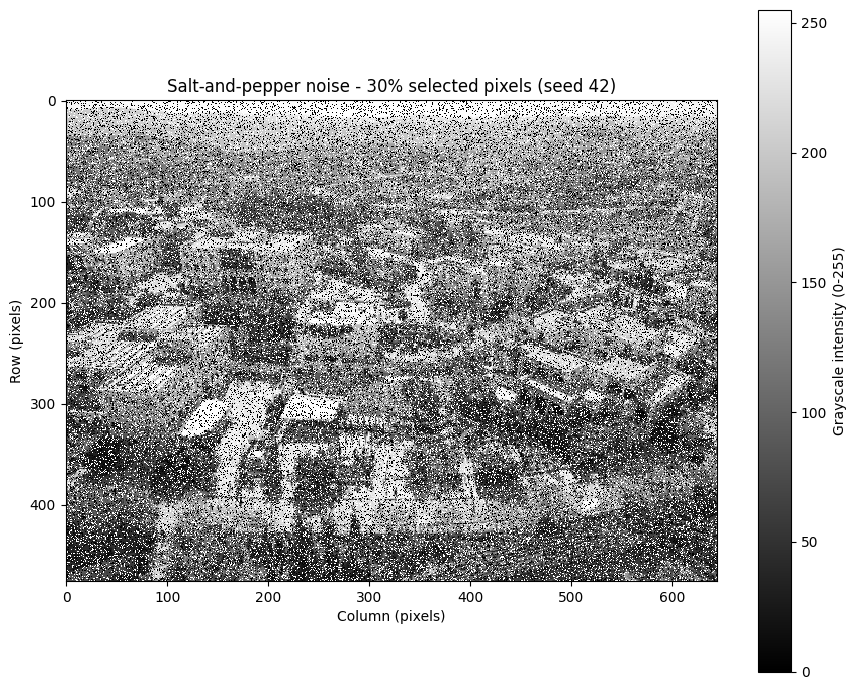

In [33]:
# Display the same 30% noisy realization that will be used for all filters.
print(f"Displayed array: noisy_gray_30; shape: {noisy_gray_30.shape}; dtype: {noisy_gray_30.dtype}")
print(f"Selected noise density: {np.count_nonzero(noise_mask_30) / noisy_gray_30.size:.2%}; seed: {noise_seed}")
print("Display: grayscale; fixed intensity limits [0, 255]; nearest-neighbor interpolation")
fig, ax = plt.subplots(figsize=(9, 7))
noisy_plot = ax.imshow(noisy_gray_30, cmap="gray", vmin=0, vmax=255,
                       interpolation="nearest", aspect="equal")
ax.set_title(f"Salt-and-pepper noise - {noise_density:.0%} selected pixels (seed {noise_seed})")
ax.set_xlabel("Column (pixels)")
ax.set_ylabel("Row (pixels)")
fig.colorbar(noisy_plot, ax=ax, label="Grayscale intensity (0-255)")
plt.tight_layout()
plt.show()

**Observation:** Dense black and white specks cover the scene, interrupting smooth areas and obscuring fine details. The larger scene structures remain recognizable. This is the unfiltered noisy input; filter quality will be assessed after applying the three required filters to this same array.

### 4. Apply filters to the noisy image.

#### (a) Gaussian filter

A **Gaussian filter** replaces each pixel with a weighted average of its neighborhood. A **kernel** is the matrix of weights; nearby pixels receive greater weight than distant ones. For integer offsets $u,v$ from the center, the normalized finite kernel is

$$K(u,v)=\frac{\exp[-(u^2+v^2)/(2\sigma^2)]}{\sum_{i,j\ \mathrm{in\ kernel}}\exp[-(i^2+j^2)/(2\sigma^2)]},\qquad J(x,y)=\sum_{u,v}K(u,v)I(x-u,y-v).$$

Here $I$ is the noisy input, $J$ the filtered output, $x,y$ spatial coordinates, and $\sigma$ the standard deviation in pixels. **Normalization** makes the weights sum to one, preserving constant intensity with the chosen reflective border. **Smoothing** reduces rapid local intensity variations, including both noise and genuine fine detail. These weights depend on distance, not on whether an intensity is an outlier; extreme noisy values therefore enter the average.

Use an initial 7 × 7 kernel with $\sigma_x=\sigma_y=1$ pixel: the radius is 3 pixels, providing 3σ support on each axis. This is a starting setting; parameter selection and visual comparison follow in Steps 5–6.

| Parameter / name | Meaning |
| --- | --- |
| `noisy_gray_30` | Same 30% noisy realization used by all filters. |
| `noise_gaussian_kernel` / `ksize` | Kernel width and height, (7, 7); positive odd sizes center the neighborhood. |
| `noise_gaussian_sigma` / `sigmaX`, `sigmaY` | Spread of Gaussian weights along columns and rows; both explicitly set to 1 pixel. |
| `noise_gaussian_border` / `borderType` | `BORDER_REFLECT_101`: reflect values outside the image without repeating its boundary pixel. |
| `gaussian_noisy_30` | Gaussian-filtered result, stored separately from the noisy input. |
| `cv2.getGaussianKernel` | Returns normalized 1D Gaussian coefficients; their outer product gives the 2D kernel for this separable filter. |
| `np.outer` | Multiplies each coefficient of one vector by each coefficient of the other. |

OpenCV preserves the input data type here: `uint8` output stores integer levels, so fractional weighted averages are quantized. This differs from Task 3's deliberate `float64` analysis. No extra noise or preceding smoothing is applied.

In [34]:
# Apply Gaussian filtering directly to the shared noisy input.
noise_gaussian_kernel = (7, 7)
noise_gaussian_sigma = 1.0
noise_gaussian_border = cv2.BORDER_REFLECT_101
gaussian_noisy_30 = cv2.GaussianBlur(
    noisy_gray_30, ksize=noise_gaussian_kernel,
    sigmaX=noise_gaussian_sigma, sigmaY=noise_gaussian_sigma,
    borderType=noise_gaussian_border
)
noise_gaussian_1d = cv2.getGaussianKernel(
    noise_gaussian_kernel[0], noise_gaussian_sigma, cv2.CV_64F
).ravel()
noise_gaussian_2d = np.outer(noise_gaussian_1d, noise_gaussian_1d)

assert gaussian_noisy_30.shape == noisy_gray_30.shape
assert gaussian_noisy_30.dtype == noisy_gray_30.dtype
recreated_noisy_30, _ = add_salt_pepper(clean_gray, noise_density, noise_seed)
assert np.array_equal(noisy_gray_30, recreated_noisy_30), "Noisy input was modified."
assert np.array_equal(clean_gray, gray), "Original reference was modified."
print("Filter: cv2.GaussianBlur; input: noisy_gray_30 (no additional noise or smoothing)")
print(f"Selected noise density: {noise_density:.0%}; noise seed: {noise_seed}")
print(f"Kernel (width, height): {noise_gaussian_kernel}; radius: 3 pixels per axis")
print(f"sigmaX = sigmaY = {noise_gaussian_sigma:.1f} pixel; support: +/-3 sigma per axis")
print("Boundary rule: cv2.BORDER_REFLECT_101")
print(f"Normalized 1D coefficients: {np.array2string(noise_gaussian_1d, precision=8)}")
print(f"2D coefficient sum: {noise_gaussian_2d.sum():.16f}")
print(f"Input shape: {noisy_gray_30.shape}; dtype: {noisy_gray_30.dtype}; range: [{noisy_gray_30.min()}, {noisy_gray_30.max()}]")
print(f"Output shape: {gaussian_noisy_30.shape}; channels: 1; dtype: {gaussian_noisy_30.dtype}")
print(f"Observed output range: [{gaussian_noisy_30.min()}, {gaussian_noisy_30.max()}]")
print(f"Output pixel-data memory: {gaussian_noisy_30.nbytes:,} bytes")
print("Noisy input and original reference preserved: True")
print("Parameter status: initial setting; final visual selection follows in Step 5.")

Filter: cv2.GaussianBlur; input: noisy_gray_30 (no additional noise or smoothing)
Selected noise density: 30%; noise seed: 42
Kernel (width, height): (7, 7); radius: 3 pixels per axis
sigmaX = sigmaY = 1.0 pixel; support: +/-3 sigma per axis
Boundary rule: cv2.BORDER_REFLECT_101
Normalized 1D coefficients: [0.00443305 0.05400558 0.24203623 0.39905028 0.24203623 0.05400558
 0.00443305]
2D coefficient sum: 1.0000000000000000
Input shape: (476, 645); dtype: uint8; range: [0, 255]
Output shape: (476, 645); channels: 1; dtype: uint8
Observed output range: [11, 255]
Output pixel-data memory: 307,020 bytes
Noisy input and original reference preserved: True
Parameter status: initial setting; final visual selection follows in Step 5.


**Interpretation:** The normalized kernel forms a local average rather than explicitly identifying and replacing impulse outliers. The output range reports resulting stored values, not a measure of successful noise removal. Assess residual noise and lost detail visually when comparing filters; a narrower intensity range alone does not establish better restoration.

#### (b) Median filter

The **median** is the middle value after sorting an odd number of values in ascending order. A **median filter** replaces each pixel with the median of its local square neighborhood, including the center pixel:

$$J(x,y)=\operatorname{median}\{I(x+u,y+v): -r\leq u,v\leq r\},\qquad r=(k-1)/2.$$

Here $I$ is the noisy input, $J$ the output, $x,y$ pixel coordinates, $u,v$ integer offsets, $k$ the odd window side length, and $r$ its radius. For a 5 × 5 window, sorting 25 values makes the 13th value the output. Unlike the arithmetic **mean** (sum divided by count), the median is a **rank statistic**: it depends on the ordering of values. It is **nonlinear**, so it cannot generally be expressed as a fixed weighted sum of input pixels.

An isolated extreme value often moves to an end of the sorted list instead of controlling its middle. This makes median filtering useful for impulse noise. It can still alter thin structures and corners, and clusters of impulses may survive; an uncorrupted majority does not guarantee recovery of the exact original center value in a textured neighborhood.

| Parameter / name | Meaning |
| --- | --- |
| `noisy_gray_30` | Same unfiltered noisy input used for Gaussian filtering; filters are applied independently, not in sequence. |
| `noise_median_ksize` / `ksize` | Odd integer window side length greater than 1; initial value 5 gives a 5 × 5 window with radius 2 pixels. |
| `median_noisy_30` | Separate median-filtered output array. |
| `cv2.medianBlur` | OpenCV median filter; no sigma or Gaussian weight coefficients are used. |
| `BORDER_REPLICATE` | OpenCV's internal border rule for this function: repeat the nearest boundary pixel outside the image. `medianBlur` exposes no `borderType` argument. |
| `np.sort` / `np.median` | Sort values / compute the median, used below for a small numerical illustration. |

Use 5 × 5 as an initial setting; the later parameter comparison will assess the trade-off between residual noise and detail loss. The output retains the input shape and `uint8` type. Its median is an existing neighborhood intensity, rather than a fractional average requiring rounding. Gaussian and median filtering here use different border rules, so later comparisons near image borders must account for that difference.

In [35]:
# Apply the median filter directly to the shared noisy input, not the Gaussian output.
noise_median_ksize = 5
median_noisy_30 = cv2.medianBlur(noisy_gray_30, ksize=noise_median_ksize)

# Illustrate the median with one pepper impulse among eight nearby intensities.
median_example = np.array([[98, 100, 102], [99, 0, 101], [97, 103, 100]], dtype=np.uint8)
median_example_sorted = np.sort(median_example.ravel())
median_example_result = cv2.medianBlur(median_example, 3)[1, 1]
assert median_example_result == np.median(median_example)
assert median_noisy_30.shape == noisy_gray_30.shape
assert median_noisy_30.dtype == noisy_gray_30.dtype
median_recreated_input, _ = add_salt_pepper(clean_gray, noise_density, noise_seed)
assert np.array_equal(noisy_gray_30, median_recreated_input), "Noisy input was modified."
assert np.array_equal(clean_gray, gray), "Original reference was modified."
print("Filter: cv2.medianBlur; input: noisy_gray_30 (independent of Gaussian output)")
print(f"Selected noise density: {noise_density:.0%}; noise seed: {noise_seed}")
print(f"Window: {noise_median_ksize} x {noise_median_ksize}; radius: {noise_median_ksize // 2} pixels")
print(f"Values per window: {noise_median_ksize**2}; median rank (1-based): {noise_median_ksize**2 // 2 + 1}")
print("Boundary rule: BORDER_REPLICATE (internal to medianBlur)")
print(f"Output shape: {median_noisy_30.shape}; channels: 1; dtype: {median_noisy_30.dtype}")
print(f"Observed output range: [{median_noisy_30.min()}, {median_noisy_30.max()}]")
print(f"Output pixel-data memory: {median_noisy_30.nbytes:,} bytes")
print("Illustrative 3 x 3 neighborhood (not an extracted image patch):")
print(median_example)
print(f"Sorted values: {median_example_sorted}")
print(f"Original center: {median_example[1, 1]}; filtered center: {median_example_result}")
print(f"Neighborhood arithmetic mean: {median_example.mean():.4f}; median: {np.median(median_example):.1f}")
print("Noisy input and original reference preserved: True")
print("Parameter status: initial setting; final visual selection follows in Step 5.")

Filter: cv2.medianBlur; input: noisy_gray_30 (independent of Gaussian output)
Selected noise density: 30%; noise seed: 42
Window: 5 x 5; radius: 2 pixels
Values per window: 25; median rank (1-based): 13
Boundary rule: BORDER_REPLICATE (internal to medianBlur)
Output shape: (476, 645); channels: 1; dtype: uint8
Observed output range: [0, 255]
Output pixel-data memory: 307,020 bytes
Illustrative 3 x 3 neighborhood (not an extracted image patch):
[[ 98 100 102]
 [ 99   0 101]
 [ 97 103 100]]
Sorted values: [  0  97  98  99 100 100 101 102 103]
Original center: 0; filtered center: 100
Neighborhood arithmetic mean: 88.8889; median: 100.0
Noisy input and original reference preserved: True
Parameter status: initial setting; final visual selection follows in Step 5.


**Interpretation:** In the illustrative neighborhood, the center impulse of 0 is replaced by the median 100, whereas the arithmetic mean is about 88.89. This demonstrates resistance to a single impulse in an otherwise nearly uniform patch; it does not quantify restoration quality across the actual image. The actual output range is only a descriptive property. Visual comparison and parameter selection follow after implementing the bilateral filter.

#### (c) Bilateral filter

A **bilateral filter** computes a normalized weighted average using two kinds of similarity: closeness in spatial position and closeness in intensity. For a grayscale image,

$$J(p)=\frac{\sum_{q\in\Omega_p}w_s(p,q)w_r(p,q)I(q)}{\sum_{q\in\Omega_p}w_s(p,q)w_r(p,q)},$$
$$w_s(p,q)=\exp\!\left(-\frac{\|p-q\|^2}{2\sigma_s^2}\right),\qquad w_r(p,q)=\exp\!\left(-\frac{[I(p)-I(q)]^2}{2\sigma_r^2}\right).$$

Here $I$ is the noisy input, $J$ the output, $p$ the center pixel location, $q$ a neighboring location, and $\Omega_p$ its finite neighborhood. $\|p-q\|$ is Euclidean distance in pixels. The **spatial weight** $w_s$ favors nearby pixels; the **range weight** $w_r$ favors intensities similar to the center. The denominator normalizes the combined weights. **Range** here means intensity similarity, not image dimensions or the observed minimum-to-maximum interval.

This can preserve edges by reducing averaging across strong intensity changes. It is **nonlinear** because its weights depend on the input intensities. However, if the center itself is a salt or pepper impulse, valid neighbors may receive very small range weights, allowing the impulse to remain. A larger intensity sigma permits more mixing but can also blur genuine intensity boundaries.

| Parameter / name | Meaning |
| --- | --- |
| `noisy_gray_30` | Same unfiltered noisy realization used independently by Gaussian and median filters. |
| `noise_bilateral_d` / `d` | Neighborhood diameter in pixels; initial value 9. This is a diameter parameter, not a count of neighbors or passes. |
| `noise_bilateral_sigma_color` / `sigmaColor` | Range sigma $\sigma_r$, initially 75 intensity units on the 0–255 scale. Despite its name, it measures intensity differences for this grayscale input. |
| `noise_bilateral_sigma_space` / `sigmaSpace` | Spatial sigma $\sigma_s$, initially 3 pixels. Larger values broaden spatial weighting within the selected support. |
| Positive `d` | Fixes neighborhood size independently of `sigmaSpace`; increasing spatial sigma alone does not expand this fixed support. |
| `noise_bilateral_border` / `borderType` | `BORDER_REFLECT_101`, reflection without repeating the boundary pixel. |
| `bilateral_noisy_30` | Separate output array; OpenCV bilateral filtering does not support in-place operation. |

Use these as initial settings, with a single pass and `uint8` output. Weighted averages are quantized to integer levels. Step 5 will assess parameter alternatives rather than assume these values are optimal.

In [36]:
# Apply bilateral filtering directly to the shared noisy image.
noise_bilateral_d = 9
noise_bilateral_sigma_color = 75.0
noise_bilateral_sigma_space = 3.0
noise_bilateral_border = cv2.BORDER_REFLECT_101
bilateral_noisy_30 = cv2.bilateralFilter(
    noisy_gray_30, d=noise_bilateral_d,
    sigmaColor=noise_bilateral_sigma_color,
    sigmaSpace=noise_bilateral_sigma_space,
    borderType=noise_bilateral_border
)
assert bilateral_noisy_30.shape == noisy_gray_30.shape
assert bilateral_noisy_30.dtype == noisy_gray_30.dtype
bilateral_recreated_input, _ = add_salt_pepper(clean_gray, noise_density, noise_seed)
assert np.array_equal(noisy_gray_30, bilateral_recreated_input), "Noisy input was modified."
assert np.array_equal(clean_gray, gray), "Original reference was modified."
print("Filter: cv2.bilateralFilter; input: noisy_gray_30; passes: 1")
print(f"Selected noise density: {noise_density:.0%}; noise seed: {noise_seed}")
print(f"Neighborhood diameter d: {noise_bilateral_d} pixels (fixed positive diameter)")
print(f"sigmaColor (intensity similarity): {noise_bilateral_sigma_color:.1f} intensity units")
print(f"sigmaSpace (spatial distance): {noise_bilateral_sigma_space:.1f} pixels")
print("Boundary rule: cv2.BORDER_REFLECT_101")
print(f"Output shape: {bilateral_noisy_30.shape}; channels: 1; dtype: {bilateral_noisy_30.dtype}")
print(f"Observed output range: [{bilateral_noisy_30.min()}, {bilateral_noisy_30.max()}]")
print(f"Output pixel-data memory: {bilateral_noisy_30.nbytes:,} bytes")
print("Illustrative unnormalized range weights (before spatial weighting):")
for intensity_gap in (0.0, 25.0, 100.0, 255.0):
    range_weight = np.exp(-(intensity_gap**2) / (2 * noise_bilateral_sigma_color**2))
    print(f"  Absolute intensity difference {intensity_gap:5.1f}: range weight = {range_weight:.6f}")
print("These are weight examples, not measured noise-removal probabilities.")
print("Noisy input and original reference preserved: True")
print("Parameter status: initial setting; visual parameter selection follows in Step 5.")

Filter: cv2.bilateralFilter; input: noisy_gray_30; passes: 1
Selected noise density: 30%; noise seed: 42
Neighborhood diameter d: 9 pixels (fixed positive diameter)
sigmaColor (intensity similarity): 75.0 intensity units
sigmaSpace (spatial distance): 3.0 pixels
Boundary rule: cv2.BORDER_REFLECT_101
Output shape: (476, 645); channels: 1; dtype: uint8
Observed output range: [1, 255]
Output pixel-data memory: 307,020 bytes
Illustrative unnormalized range weights (before spatial weighting):
  Absolute intensity difference   0.0: range weight = 1.000000
  Absolute intensity difference  25.0: range weight = 0.945959
  Absolute intensity difference 100.0: range weight = 0.411112
  Absolute intensity difference 255.0: range weight = 0.003089
These are weight examples, not measured noise-removal probabilities.
Noisy input and original reference preserved: True
Parameter status: initial setting; visual parameter selection follows in Step 5.


**Interpretation:** The printed range weights decrease as intensity difference grows. This explains both reduced mixing across genuine edges and the risk of isolating an extreme noisy center from valid neighbors. These examples describe the weighting mechanism; neither they nor the output intensity range establish which filter restores this image best. All three required filters are now implemented independently on the same noisy input. Next, compare parameter alternatives before displaying the selected results together.

### 5. Select suitable parameters for each filter.

**Parameter selection** chooses filter settings for a stated objective. Here the objective is a visual balance between residual specks and preservation of structures such as roof boundaries and windows. **Residual noise** is unwanted corruption remaining after filtering; **detail loss** is suppression of genuine small structures.

Compare three candidates per family using the identical 30% noisy input and one pass each. For Gaussian filtering, vary sigma with an odd kernel covering at least 3σ per axis. For median filtering, vary window side length. For bilateral filtering, vary intensity sigma while fixing diameter and spatial sigma. This is a limited candidate comparison, not an exhaustive search.

Also report **mean absolute error (MAE)** against the original grayscale reference:

$$\mathrm{MAE}=\frac{1}{N}\sum_p |J(p)-I_{ref}(p)|.$$

$N$ is the full-image pixel count, $J$ the candidate output, and $I_{ref}$ the original grayscale image. Convert to `float64` before subtraction to prevent unsigned wraparound. Lower MAE means closer average pixel agreement in original intensity units; it does not fully measure edge quality or visual preference. The reference is available in this synthetic experiment; it would generally be unavailable for a naturally noisy photograph.

**Reading the plot:** Every panel uses the same fixed crop, rows [180, 340) and columns [220, 420), and the same display limits 0–255. Slice endpoints are excluded. The original reference is repeated per row to support comparison. Panel coordinates are relative to the crop; printed MAE values use the full image. No noise-selection mask is supplied to any filter. Boundary handling remains reflection for Gaussian/bilateral and replication for median, as documented above.

Reference: original grayscale; MAE in original intensity units (lower is better pixel agreement)
Unfiltered noisy input MAE: 38.2058
Gaussian   k=7, sigma=1                           MAE=25.4541; range=[11, 255]
Gaussian   k=11, sigma=1.5                        MAE=24.8703; range=[20, 254]
Gaussian   k=13, sigma=2                          MAE=25.4396; range=[26, 252]
Median     k=3                                    MAE=11.8922; range=[0, 255]
Median     k=5                                    MAE=13.4265; range=[0, 255]
Median     k=7                                    MAE=15.4079; range=[0, 255]
Bilateral  d=9, range=75, spatial=3               MAE=32.7817; range=[1, 255]
Bilateral  d=9, range=150, spatial=3              MAE=22.5506; range=[14, 255]
Bilateral  d=9, range=250, spatial=3              MAE=23.1857; range=[20, 255]


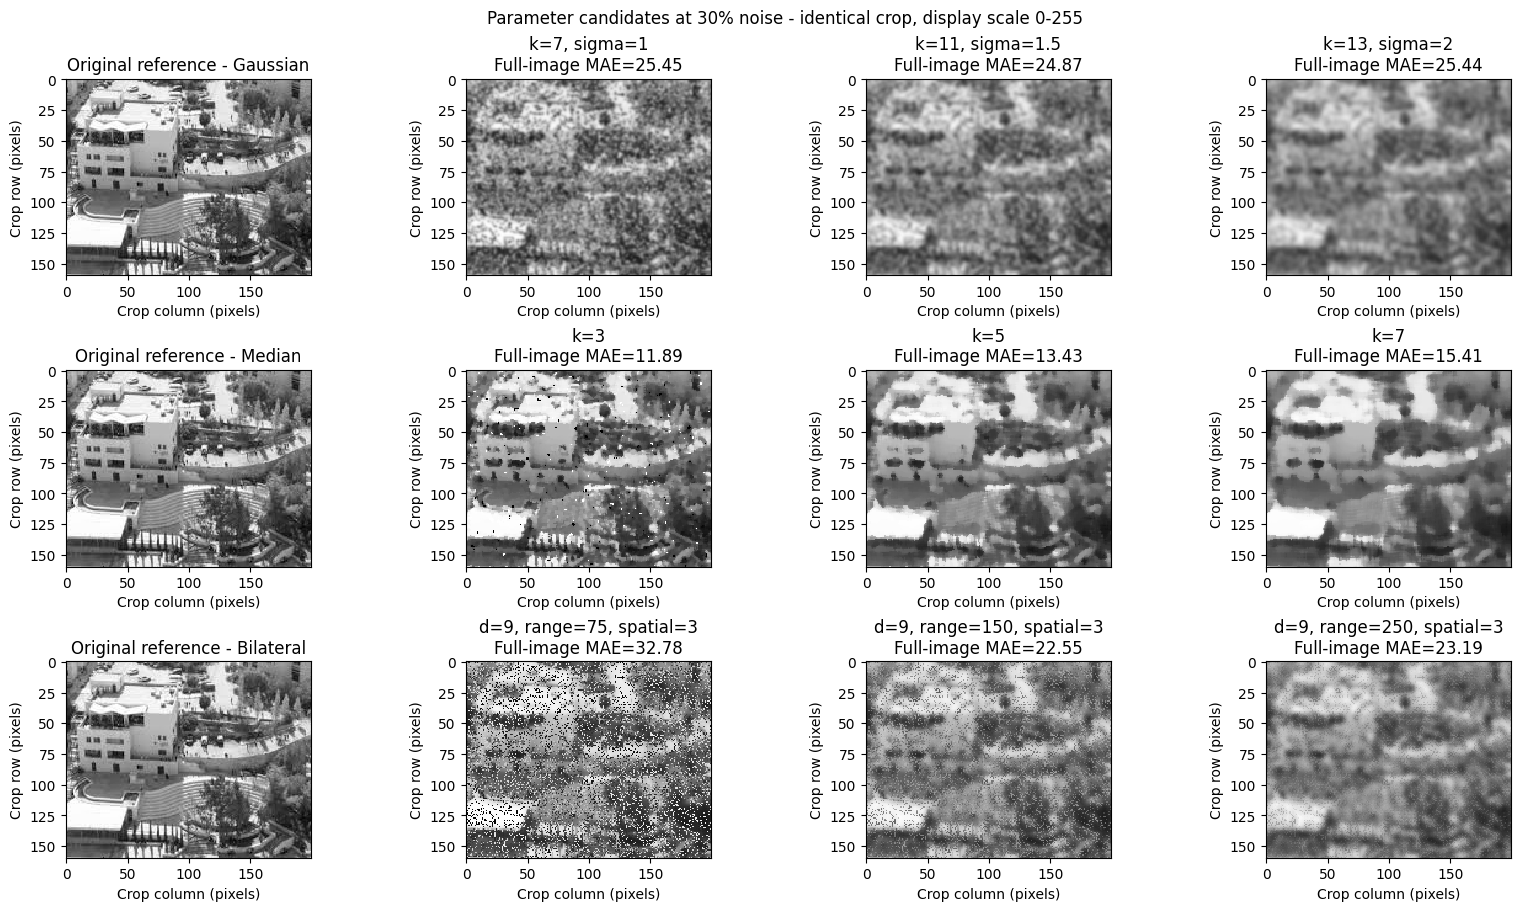

Crop: original rows [180, 340), columns [220, 420); plot coordinates are relative to this crop.


In [37]:
# Compare a small, declared candidate set on the identical 30% noisy input.
def reference_mae(result):
    return float(np.mean(np.abs(result.astype(np.float64) - clean_gray.astype(np.float64))))

gaussian_candidates = [(1.0, 7), (1.5, 11), (2.0, 13)]
median_candidates = [3, 5, 7]
bilateral_candidates = [(9, 75.0, 3.0), (9, 150.0, 3.0), (9, 250.0, 3.0)]
filter_trials = {"Gaussian": [], "Median": [], "Bilateral": []}
for sigma, size in gaussian_candidates:
    result = cv2.GaussianBlur(noisy_gray_30, (size, size), sigmaX=sigma, sigmaY=sigma,
                              borderType=cv2.BORDER_REFLECT_101)
    filter_trials["Gaussian"].append((f"k={size}, sigma={sigma:g}", result, reference_mae(result)))
for size in median_candidates:
    result = cv2.medianBlur(noisy_gray_30, size)
    filter_trials["Median"].append((f"k={size}", result, reference_mae(result)))
for diameter, sigma_color, sigma_space in bilateral_candidates:
    result = cv2.bilateralFilter(noisy_gray_30, diameter, sigma_color, sigma_space,
                                 borderType=cv2.BORDER_REFLECT_101)
    label = f"d={diameter}, range={sigma_color:g}, spatial={sigma_space:g}"
    filter_trials["Bilateral"].append((label, result, reference_mae(result)))
print("Reference: original grayscale; MAE in original intensity units (lower is better pixel agreement)")
print(f"Unfiltered noisy input MAE: {reference_mae(noisy_gray_30):.4f}")
for family, trials in filter_trials.items():
    for label, result, error in trials:
        print(f"{family:10s} {label:38s} MAE={error:.4f}; range=[{result.min()}, {result.max()}]")

# Inspect the same fixed crop across all candidates; no crop-specific tuning.
tuning_rows = slice(180, 340)
tuning_columns = slice(220, 420)
fig, axes = plt.subplots(3, 4, figsize=(16, 9), constrained_layout=True)
for row, (family, trials) in enumerate(filter_trials.items()):
    axes[row, 0].imshow(clean_gray[tuning_rows, tuning_columns], cmap="gray", vmin=0, vmax=255,
                        interpolation="nearest")
    axes[row, 0].set_title(f"Original reference - {family}")
    for col, (label, result, error) in enumerate(trials, start=1):
        axes[row, col].imshow(result[tuning_rows, tuning_columns], cmap="gray", vmin=0, vmax=255,
                              interpolation="nearest")
        axes[row, col].set_title(f"{label}\nFull-image MAE={error:.2f}")
    for ax in axes[row]:
        ax.set_xlabel("Crop column (pixels)")
        ax.set_ylabel("Crop row (pixels)")
fig.suptitle("Parameter candidates at 30% noise - identical crop, display scale 0-255")
plt.show()
print("Crop: original rows [180, 340), columns [220, 420); plot coordinates are relative to this crop.")


In [38]:
# Store visually selected settings and outputs for the next side-by-side display.
selected_gaussian_params = {"ksize": (11, 11), "sigmaX": 1.5, "sigmaY": 1.5,
                            "borderType": cv2.BORDER_REFLECT_101}
selected_median_ksize = 5
selected_bilateral_params = {"d": 9, "sigmaColor": 250.0, "sigmaSpace": 3.0,
                             "borderType": cv2.BORDER_REFLECT_101}
gaussian_selected_30 = filter_trials["Gaussian"][1][1]
median_selected_30 = filter_trials["Median"][1][1]
bilateral_selected_30 = filter_trials["Bilateral"][2][1]
print("Selected settings at 30% noise (visual trade-off within tested candidates):")
print(f"Gaussian: {selected_gaussian_params}; MAE={reference_mae(gaussian_selected_30):.4f}")
print(f"Median: ksize={selected_median_ksize}; border=BORDER_REPLICATE; MAE={reference_mae(median_selected_30):.4f}")
print(f"Bilateral: {selected_bilateral_params}; MAE={reference_mae(bilateral_selected_30):.4f}")
print("OpenCV border enum in dictionaries: BORDER_REFLECT_101 =", cv2.BORDER_REFLECT_101)
print("Selection is visual; the lowest-MAE candidate is not necessarily selected.")


Selected settings at 30% noise (visual trade-off within tested candidates):
Gaussian: {'ksize': (11, 11), 'sigmaX': 1.5, 'sigmaY': 1.5, 'borderType': 4}; MAE=24.8703
Median: ksize=5; border=BORDER_REPLICATE; MAE=13.4265
Bilateral: {'d': 9, 'sigmaColor': 250.0, 'sigmaSpace': 3.0, 'borderType': 4}; MAE=23.1857
OpenCV border enum in dictionaries: BORDER_REFLECT_101 = 4
Selection is visual; the lowest-MAE candidate is not necessarily selected.


**Selection and visual justification (this image, 30% noise, seed 42):**

| Filter | Selected setting | Reason and limitation |
| --- | --- | --- |
| Gaussian | 11 × 11, σ=1.5 | Smoother than σ=1 with less mottling; σ=2 further blurs small structures. Its MAE is also the lowest of the three Gaussian candidates (24.8703). Impulse contamination remains spread through neighborhoods. |
| Median | 5 × 5 | Reduces visible isolated specks relative to 3 × 3 while retaining more building structure than 7 × 7. The 3 × 3 option preserves more fine detail and has better MAE (11.8922 versus 13.4265), so 5 × 5 is an explicit visual preference for fewer specks, not an objective winner. |
| Bilateral | d=9, sigmaColor=250, sigmaSpace=3 | Leaves fewer strong isolated specks than range sigma 75 or 150 in the inspected crop. It also loses detail and behaves more like spatial averaging as range weights become less selective. SigmaColor=150 has lower MAE (22.5506 versus 23.1857); choosing 250 favors suppression of visible impulses. |

**Limits:** These are suitable settings among the declared candidates for one image and one realization. They are not globally optimal, independently validated, or necessarily appropriate at 10% and 50% noise. The crop highlights local differences and cannot represent every region. MAE is computed over the full image and includes borders with the documented differing rules. The next step displays the selected full-image results together; density experiments follow later.

### 6. Display the three filtered images side by side.

Display the selected outputs from Step 5, all computed independently from the same 30% noisy input. A **shared intensity scale** maps the same stored value to the same shade in every panel: `cmap="gray"`, `vmin=0`, and `vmax=255`. The common **colorbar** labels this mapping, not restoration error. `sharex=True` and `sharey=True` align spatial coordinates; `aspect="equal"` keeps square pixels. `interpolation="nearest"` avoids blending adjacent values during rendering, although a reduced full-image view cannot show every source pixel individually.

Titles identify the selected parameters. The arrays retain their original resolution; resizing the figure changes only their displayed size. The crop comparison in Step 5 complements this full-image view for fine-detail inspection.

Gaussian: 11 x 11, sigma=1.5: shape=(476, 645); dtype=uint8; range=[20, 254]
Median: 5 x 5: shape=(476, 645); dtype=uint8; range=[0, 255]
Bilateral: d=9, sigmaColor=250, sigmaSpace=3: shape=(476, 645); dtype=uint8; range=[20, 255]


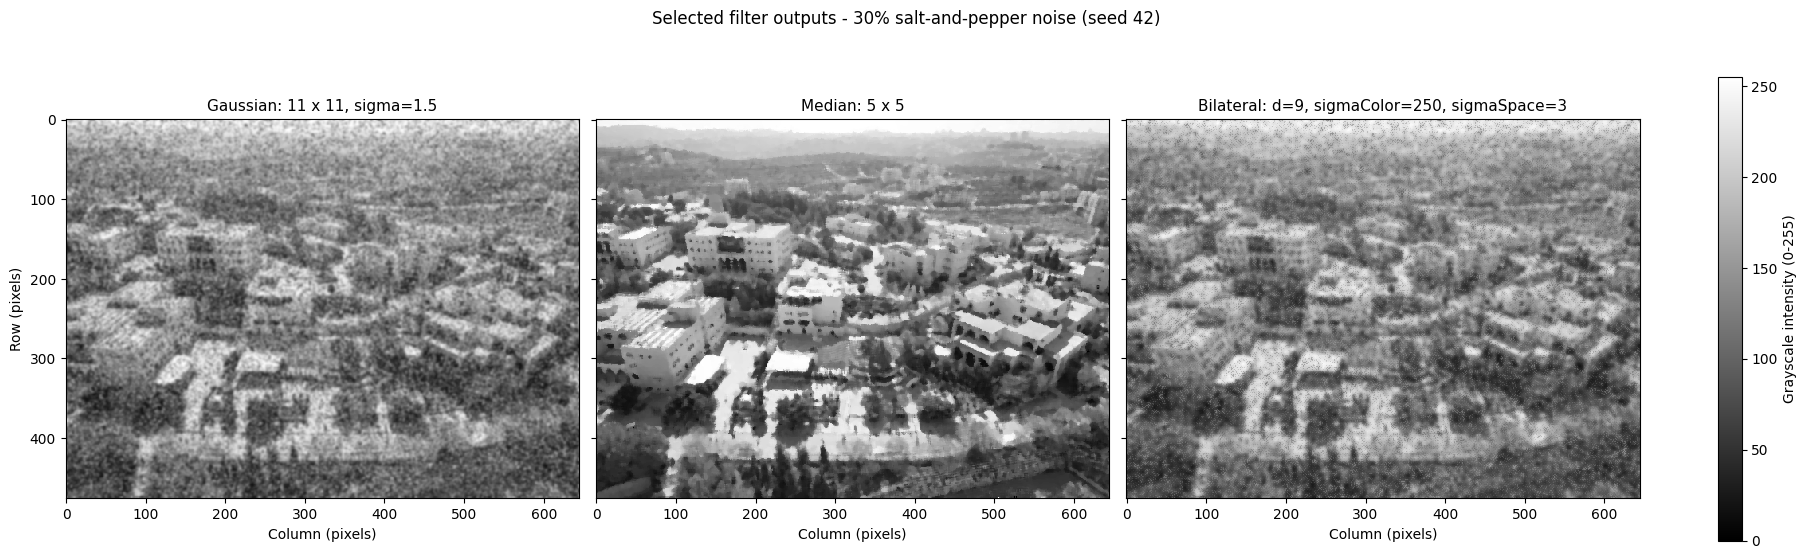

Common display limits: [0, 255]; identical input realization; one independent pass per filter.


In [39]:
# Display the already selected outputs without applying another filtering pass.
selected_filter_views = [
    ("Gaussian: 11 x 11, sigma=1.5", gaussian_selected_30),
    ("Median: 5 x 5", median_selected_30),
    ("Bilateral: d=9, sigmaColor=250, sigmaSpace=3", bilateral_selected_30)
]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.8), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, (label, result) in zip(axes, selected_filter_views):
    assert result.shape == clean_gray.shape and result.dtype == np.uint8
    filtered_plot = ax.imshow(result, cmap="gray", vmin=0, vmax=255,
                               interpolation="nearest", aspect="equal")
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("Column (pixels)")
    print(f"{label}: shape={result.shape}; dtype={result.dtype}; range=[{result.min()}, {result.max()}]")
axes[0].set_ylabel("Row (pixels)")
fig.colorbar(filtered_plot, ax=axes, label="Grayscale intensity (0-255)", shrink=0.85)
fig.suptitle(f"Selected filter outputs - {noise_density:.0%} salt-and-pepper noise (seed {noise_seed})")
plt.show()
print("Common display limits: [0, 255]; identical input realization; one independent pass per filter.")

**Observation:** The selected Gaussian output appears smoothed and mottled. The median output has fewer conspicuous impulse specks while losing some small structures. The selected bilateral output also smooths the scene, with residual uneven texture. These full-image views support qualitative comparison; the following discussion will relate the differences to each filtering mechanism and the limitations of this single realization.

### 7. Compare noise removal, image details, and edges.

**Noise suppression** reduces the synthetic corruption; **detail preservation** retains genuine small structures and texture. **Edge preservation** retains the location and contrast of meaningful intensity transitions, such as building boundaries. A smooth-looking image can still lose useful detail, and a sharp-looking speck can be noise. Consequently, visual smoothness alone is not a restoration-quality measure.

Compare the selected outputs shown in Step 6 and the enlarged crop in Step 5. The following table prints full-image MAE against the original grayscale reference. **MAE reduction** is the percentage decrease relative to the unfiltered noisy input, $100(\mathrm{MAE}_{noisy}-\mathrm{MAE}_{filtered})/\mathrm{MAE}_{noisy}$. It measures improvement in average pixel agreement, not the percentage of impulses removed or a direct edge-preservation score.

In [40]:
# Report reference agreement for the selected outputs without modifying any images.
comparison_outputs = [
    ("Noisy input", noisy_gray_30),
    ("Gaussian (11 x 11, sigma=1.5)", gaussian_selected_30),
    ("Median (5 x 5)", median_selected_30),
    ("Bilateral (9, 250, 3)", bilateral_selected_30)
]
noisy_reference_mae = reference_mae(noisy_gray_30)
print("Comparison: 30% selected salt-and-pepper locations; seed 42; same input for every filter")
print(f"{'Image / filter':<34} {'MAE (intensity units)':>23} {'MAE reduction (%)':>20}")
for label, result in comparison_outputs:
    error = reference_mae(result)
    reduction = 100 * (noisy_reference_mae - error) / noisy_reference_mae
    print(f"{label:<34} {error:23.4f} {reduction:20.2f}")
print("Lower MAE means closer average pixel agreement; it is not an edge-specific metric.")
print("Reference: original grayscale. No noise-selection mask is used by any filter.")

Comparison: 30% selected salt-and-pepper locations; seed 42; same input for every filter
Image / filter                       MAE (intensity units)    MAE reduction (%)
Noisy input                                        38.2058                 0.00
Gaussian (11 x 11, sigma=1.5)                      24.8703                34.90
Median (5 x 5)                                     13.4265                64.86
Bilateral (9, 250, 3)                              23.1857                39.31
Lower MAE means closer average pixel agreement; it is not an edge-specific metric.
Reference: original grayscale. No noise-selection mask is used by any filter.


**Evidence-based comparison:**

| Selected filter | Noise suppression in the displayed results | Details and edges | Explanation |
| --- | --- | --- | --- |
| Gaussian, 11 × 11, σ=1.5 | Strong impulses become less conspicuous but spread into local mottling. | Building and roof boundaries are softened; small structures are blurred. | Spatial averaging includes extreme corrupted values and smooths genuine transitions as well. |
| Median, 5 × 5 | Most conspicuous isolated specks are suppressed, giving the clearest overall scene of these selected outputs. Some corruption remains. | Major building boundaries remain more visually distinct, although fine texture, small windows, thin structures, and corners can be altered. | Selecting a neighborhood's middle-ranked value limits the influence of isolated extremes without averaging their amplitudes into nearby values. |
| Bilateral, d=9, sigmaColor=250, sigmaSpace=3 | Suppresses strong specks more than the lower range-sigma candidates, but leaves uneven texture. | Considerable smoothing remains; the large intensity sigma weakens selectivity across genuine boundaries. | Similarity weighting can preserve corrupted centers when range sigma is small; increasing it improves impulse mixing at the cost of greater cross-boundary averaging. |

**Conclusion for this experiment:** The selected 5 × 5 median filter gives the most convincing overall balance of impulse suppression and recognizable scene structure among the three selected results. It also has the lowest MAE of these outputs: 13.4265, compared with 24.8703 for Gaussian, 23.1857 for bilateral, and 38.2058 for the unfiltered noisy image. Thus the numerical reference agreement supports the visual preference for median filtering here, while not proving edge preservation separately.

**Important qualification:** Within the median candidates, 3 × 3 has an even lower MAE (11.8922) and retains more small detail, but leaves more visible specks. The 5 × 5 selection explicitly favors stronger visible speck suppression. A different visual objective could reasonably prefer 3 × 3. Neither choice recovers every original pixel, and neither is established as universally best.

**Limits of the evidence:** These observations concern one image, one random realization, and a small parameter set at 30% selected density. MAE uses the available original image and combines noise, blur, and other pixel differences; it is not a count of residual impulses. No edge-specific quantitative metric has been measured. Border rules differ between median and the other filters. The following density experiments will examine whether the behavior changes at 10% and 50%, without assuming that the present choices remain suitable.

### 8. Repeat the experiment at 10%, 30%, and 50% noise densities.

A **noise-density experiment** examines how filter behavior changes as a larger fraction of image pixels is corrupted. The density $d$ retains the definition from Step 2: with $N=H\times W$ pixels, `round(d*N)` distinct locations are selected and replaced by salt (255) or pepper (0). Increasing density therefore increases the number of impulses presented to every filter; it does not change the image dimensions, data type, or the meaning of the intensity scale.

The completed 30% experiment is retained as the middle-density case. Only the missing 10% and 50% realizations are generated here. This avoids repeating work already completed in Steps 2–7 and preserves the exact 30% outputs used for parameter selection and discussion.

A **controlled comparison** changes one experimental factor while holding the others fixed. Here the changing factor is noise density. The noise-generation procedure, seed, original grayscale reference, and selected filter settings from Step 5 are held fixed. The selected settings are therefore *transferred* to 10% and 50%; they are not re-tuned separately at each density. This isolates the effect of heavier or lighter impulse corruption from the effect of choosing different filter parameters.

| Quantity / setting | Role in this density experiment |
| --- | --- |
| `0.10`, `0.30`, `0.50` | Fractions of spatial pixels selected for salt-and-pepper replacement. |
| `noise_seed = 42` | Reproducibility control used by the same `add_salt_pepper` function at every density. |
| `selected_gaussian_params` | Gaussian setting selected in Step 5: 11 × 11 kernel with $\sigma_x=\sigma_y=1.5$ and `BORDER_REFLECT_101`. |
| `selected_median_ksize` | Median window selected in Step 5: 5 × 5, with OpenCV's internal replicated border. |
| `selected_bilateral_params` | Bilateral setting selected in Step 5: `d=9`, `sigmaColor=250`, `sigmaSpace=3`, `BORDER_REFLECT_101`. |
| `density_results` | Dictionary storing the noisy image, selection mask, and three independently filtered outputs for each tested density. |
| `reference_mae(...)` | Full-image mean absolute error against `clean_gray`; lower values mean closer average pixel agreement with the original grayscale reference. |

**Why reuse the same selected parameters?** Re-optimizing each filter at every density would answer a different question: *what is the best setting for each density?* Step 8 instead repeats the same experiment across densities, so retaining the previously selected settings makes the comparison interpretable. This does not imply that the 30% settings are optimal at 10% or 50%.

**Reading the comparison:** Rows correspond to 10%, 30%, and 50% selected noise density. Columns show the noisy input and the Gaussian, median, and bilateral outputs. Every image is displayed with `cmap="gray"`, fixed limits 0–255, nearest-neighbor interpolation, and equal pixel aspect. The MAE printed in each title and in the table is computed over the full image, not from the displayed panel size.

The same seed makes each density reproducible with this code and NumPy environment. Because `rng.choice` is called separately for each density, the selected locations are not assumed to form nested subsets. For example, the 10% selected locations are not claimed to be exactly the first 10% of the 50% realization.

Fixed filter settings from the completed 30% experiment:
  Gaussian: {'ksize': (11, 11), 'sigmaX': 1.5, 'sigmaY': 1.5, 'borderType': 4}
  Median: ksize = 5
  Bilateral: {'d': 9, 'sigmaColor': 250.0, 'sigmaSpace': 3.0, 'borderType': 4}
Noise seed for all densities: 42

 Density  Selected pixels    Noisy MAE   Gaussian MAE   Median MAE   Bilateral MAE
     10%           30,702      12.6752        16.7160      12.4300         17.1052
     30%           92,106      38.2058        24.8703      13.4265         23.1857
     50%          153,510      63.5814        33.2508      16.1756         31.4666


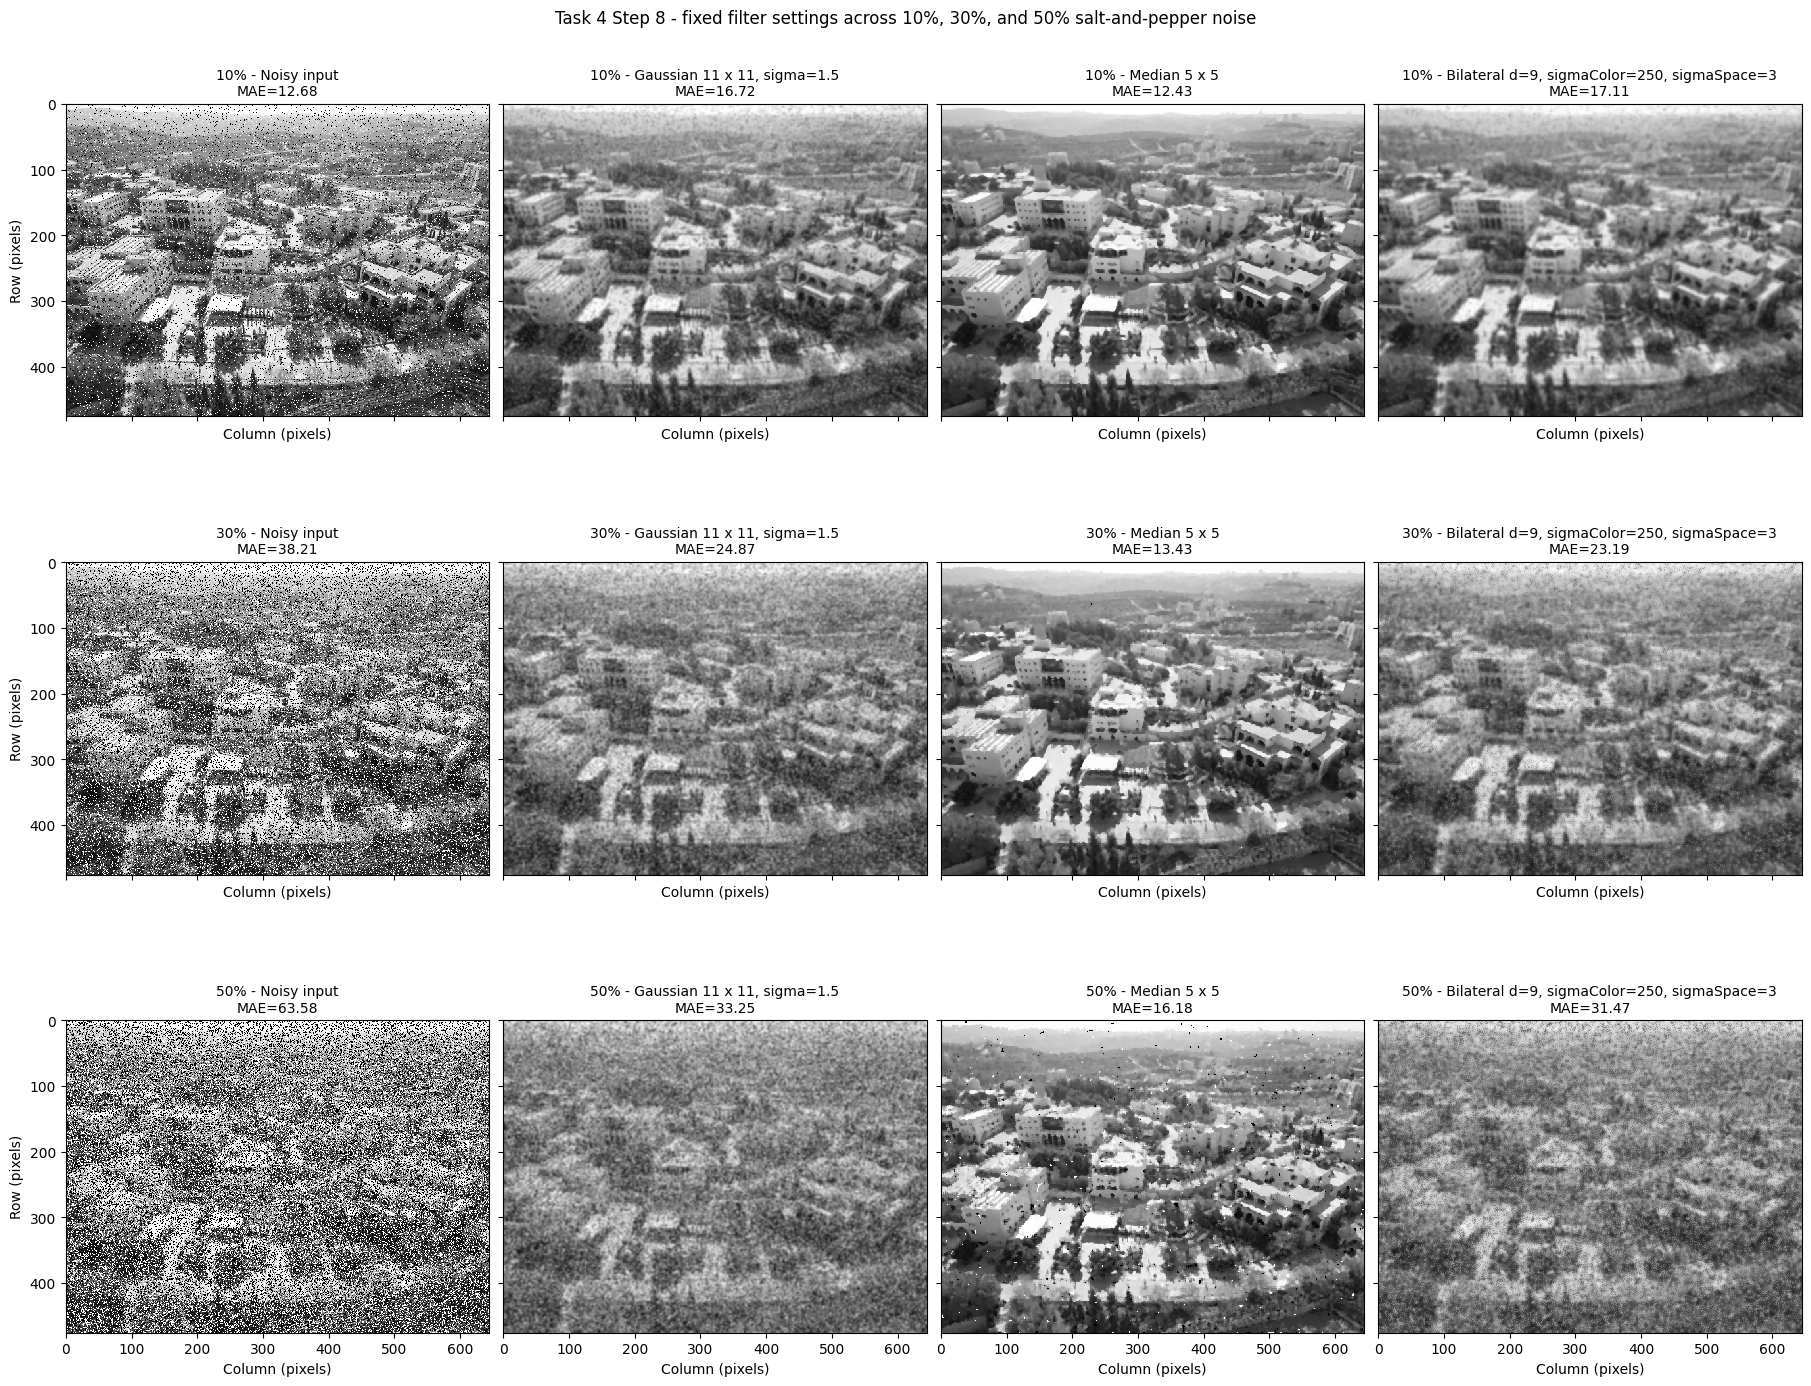

30% case reused unchanged: True


In [41]:
# Extend the completed 30% experiment to the missing 10% and 50% densities.
# Hold the noise model, seed, reference image, and selected filter parameters fixed.
density_results = {
    0.30: {
        "noisy": noisy_gray_30,
        "mask": noise_mask_30,
        "gaussian": gaussian_selected_30,
        "median": median_selected_30,
        "bilateral": bilateral_selected_30,
    }
}

# Generate only the two missing densities; the 30% arrays above are reused exactly.
for density in (0.10, 0.50):
    noisy, mask = add_salt_pepper(clean_gray, density, noise_seed)
    gaussian = cv2.GaussianBlur(noisy, **selected_gaussian_params)
    median = cv2.medianBlur(noisy, selected_median_ksize)
    bilateral = cv2.bilateralFilter(noisy, **selected_bilateral_params)

    # Verify the requested selected-pixel count and that unselected pixels are untouched.
    expected_selected = int(round(density * clean_gray.size))
    assert np.count_nonzero(mask) == expected_selected
    assert np.array_equal(noisy[~mask], clean_gray[~mask])
    # All filter outputs must preserve the grayscale image shape and uint8 type.
    for result in (gaussian, median, bilateral):
        assert result.shape == clean_gray.shape
        assert result.dtype == np.uint8

    density_results[density] = {
        "noisy": noisy,
        "mask": mask,
        "gaussian": gaussian,
        "median": median,
        "bilateral": bilateral,
    }

# Report the controls before comparing numerical reference agreement.
print("Fixed filter settings from the completed 30% experiment:")
print("  Gaussian:", selected_gaussian_params)
print("  Median: ksize =", selected_median_ksize)
print("  Bilateral:", selected_bilateral_params)
print(f"Noise seed for all densities: {noise_seed}")
print()
print(f"{'Density':>8} {'Selected pixels':>16} {'Noisy MAE':>12} {'Gaussian MAE':>14} {'Median MAE':>12} {'Bilateral MAE':>15}")
for density in (0.10, 0.30, 0.50):
    results = density_results[density]
    selected = int(np.count_nonzero(results["mask"]))
    print(
        f"{density:8.0%} {selected:16,d} "
        f"{reference_mae(results['noisy']):12.4f} "
        f"{reference_mae(results['gaussian']):14.4f} "
        f"{reference_mae(results['median']):12.4f} "
        f"{reference_mae(results['bilateral']):15.4f}"
    )

# Display every density with the same spatial scale and 0-255 intensity mapping.
fig, axes = plt.subplots(3, 4, figsize=(18, 14), sharex=True, sharey=True, constrained_layout=True)
column_specs = [
    ("noisy", "Noisy input"),
    ("gaussian", "Gaussian 11 x 11, sigma=1.5"),
    ("median", "Median 5 x 5"),
    ("bilateral", "Bilateral d=9, sigmaColor=250, sigmaSpace=3"),
]
for row, density in enumerate((0.10, 0.30, 0.50)):
    results = density_results[density]
    for col, (key, label) in enumerate(column_specs):
        image = results[key]
        axes[row, col].imshow(image, cmap="gray", vmin=0, vmax=255, interpolation="nearest", aspect="equal")
        axes[row, col].set_title(f"{density:.0%} - {label}\nMAE={reference_mae(image):.2f}", fontsize=10)
        axes[row, col].set_xlabel("Column (pixels)")
    axes[row, 0].set_ylabel("Row (pixels)")
fig.suptitle("Task 4 Step 8 - fixed filter settings across 10%, 30%, and 50% salt-and-pepper noise")
plt.show()

# Confirm that Step 8 did not recompute or replace the completed 30% case.
assert np.array_equal(density_results[0.30]["noisy"], noisy_gray_30)
assert np.array_equal(density_results[0.30]["gaussian"], gaussian_selected_30)
assert np.array_equal(density_results[0.30]["median"], median_selected_30)
assert np.array_equal(density_results[0.30]["bilateral"], bilateral_selected_30)
print("30% case reused unchanged: True")


**Interpretation guide:** Increasing density places more extreme impulses in the image, so the unfiltered input is expected to depart further from the original reference on average. The filters do not receive the selection mask and therefore cannot directly identify which pixels were synthetically corrupted; each output is produced only from local image intensities and the fixed filter parameters.

When the cell is executed, compare both the full-image views and the printed MAE values. Look specifically for how the visible salt-and-pepper specks, fine architectural details, roof boundaries, windows, and local texture change from 10% to 30% to 50%. A lower MAE supports closer average pixel agreement, but it does not by itself establish better edge preservation or perceptual quality.

**Controlled-comparison limitation:** The fixed settings make density the main experimental variable, but they also mean that a filter may become under-smoothed or over-smoothed as corruption changes. The 5 × 5 median choice, for example, was selected visually at 30%; Step 8 tests how that same choice behaves elsewhere rather than claiming it is optimal at all densities. Gaussian and bilateral outputs likewise retain their selected 30% parameters for comparability.

**Additional limits:** Each density uses one pseudorandom realization, not repeated trials over many seeds. The original grayscale image is available as a reference because the noise is synthetic. MAE combines residual impulses, smoothing error, detail loss, and border effects into one number. Gaussian/bilateral filtering use `BORDER_REFLECT_101`, while `medianBlur` uses replicated borders internally, so exact errors near image boundaries are not governed by identical border rules.

**Step 8 completion criterion:** The required three densities are represented by the existing 30% case plus the new 10% and 50% cases, each compared using the same three filter families and fixed selected settings. No conclusion about the general theoretical suitability of Gaussian filtering for impulse noise is introduced here; that analysis belongs to Step 9.

### 9. Analyze why Gaussian filtering is generally suboptimal for impulse noise removal.

**Impulse noise** differs from small additive fluctuations because a corrupted pixel is replaced by an extreme value such as 0 or 255. A Gaussian filter does not detect or reject those extreme samples. Instead, it computes a **linear weighted average** of every value inside its neighborhood:

$$J(x,y)=\sum_{u,v}K(u,v)I(x-u,y-v),\qquad \sum_{u,v}K(u,v)=1.$$

The Gaussian weights $K(u,v)$ depend only on spatial distance from the center. They do not depend on whether a neighbor is a plausible image value or a salt/pepper outlier. Therefore, when an impulse lies inside the kernel, its extreme intensity contributes directly to the weighted sum.

| Property | Consequence for salt-and-pepper noise |
| --- | --- |
| Linear weighted averaging | Corrupted values are included rather than explicitly rejected. |
| Extreme impulses at 0 or 255 | Even one corrupted sample can pull the local average away from nearby valid intensities. |
| Spatially distributed kernel weights | The effect of one impulse is spread over neighboring output pixels instead of remaining confined to one location. |
| Larger kernel or larger $\sigma$ | Stronger smoothing can make impulses less visually sharp, but also increases loss of fine detail and edge contrast. |
| No rank-based outlier suppression | The filter cannot exploit the fact that isolated 0/255 samples are often extreme relative to their local neighborhood. |

**Why this produces blur rather than robust restoration:** Suppose most pixels in a local region belong to a surface with similar gray levels and one pixel is replaced by 255. Gaussian filtering averages the 255 with its neighbors. The corrupted value is reduced at its own location, but part of its intensity is transferred to surrounding pixels through the convolution weights. The result may look smoother, yet several previously uncorrupted pixels can now differ from the original image. The same reasoning applies to a pepper impulse at 0.

This behavior explains the 30% experiment in Steps 5–7: the selected Gaussian result reduced the prominence of individual impulses, but the image became smoother and more mottled, with softened building and roof boundaries. Its full-image MAE, 24.8703, was lower than the unfiltered noisy input MAE of 38.2058, so Gaussian smoothing did improve average pixel agreement in that experiment. However, the selected 5 × 5 median result achieved a substantially lower MAE of 13.4265 while also giving the preferred visual trade-off for impulse suppression and recognizable structure. These values describe this notebook's completed 30% realization only; they are not a universal ranking.

**Why median filtering is usually better matched to isolated impulses:** A median filter is a **nonlinear rank filter**. It sorts neighborhood values and returns the middle-ranked value rather than averaging their amplitudes. An isolated salt or pepper sample is usually pushed toward one end of the sorted list, so it has little or no effect on the median when enough neighboring values are uncorrupted. This is why median filtering is commonly more robust to sparse impulse outliers while still avoiding the direct amplitude spreading produced by a Gaussian average.

**Important qualification:** Gaussian filtering is not useless. It is well suited to smoothing variations that are better modeled as small, spatially distributed intensity fluctuations, and in this notebook it did reduce MAE relative to the noisy input. The point is narrower: for **salt-and-pepper impulse noise**, its averaging mechanism is generally mismatched to the corruption model because it gives nonzero weight to extreme outliers and simultaneously smooths genuine image transitions.

**Connection to parameter choice:** Increasing Gaussian kernel size or $\sigma$ cannot remove this basic limitation. Stronger smoothing spreads each impulse over a wider neighborhood and further attenuates edges and fine structures. Weaker smoothing preserves more detail but leaves stronger impulse artifacts. This creates the trade-off observed during Step 5 parameter selection.

**Task 4 conclusion:** For the synthetic salt-and-pepper experiment used here, the median filter provides the strongest overall match to the corruption mechanism among the tested filters. Gaussian filtering can reduce visible impulse severity, but its linear averaging tends to spread outliers and blur real structure, making it generally suboptimal for this noise type.

## Task 5: Image Blending Using Laplacian Pyramids

### 1. Read apple.jpg and orange.jpg.

In [42]:
# Read both original color images in OpenCV BGR format.
apple_path = DATA_DIR / "apple.jpg"
orange_path = DATA_DIR / "orange.jpg"

apple_bgr = cv2.imread(str(apple_path), cv2.IMREAD_COLOR)
orange_bgr = cv2.imread(str(orange_path), cv2.IMREAD_COLOR)

if apple_bgr is None:
    raise FileNotFoundError(f"Unable to read image: {apple_path}")
if orange_bgr is None:
    raise FileNotFoundError(f"Unable to read image: {orange_path}")

### 2. Ensure that both images have compatible dimensions.

**Compatible dimensions** means that corresponding image arrays have the same height, width, and number of color channels. Laplacian pyramid blending combines corresponding levels element by element, so their shapes must agree.

The two input images already have matching dimensions, so no resizing is required. Avoiding unnecessary resizing preserves their original pixel values before pyramid construction.

In [43]:
# Report both image shapes and verify that they are directly compatible.
print(f"Apple shape:  {apple_bgr.shape}")
print(f"Orange shape: {orange_bgr.shape}")

if apple_bgr.shape != orange_bgr.shape:
    raise ValueError(
        f"Images must have matching dimensions for pyramid blending: "
        f"apple={apple_bgr.shape}, orange={orange_bgr.shape}"
    )

blend_height, blend_width, blend_channels = apple_bgr.shape
print(f"Compatible dimensions: {blend_height} x {blend_width} pixels, {blend_channels} channels")

Apple shape:  (307, 307, 3)
Orange shape: (307, 307, 3)
Compatible dimensions: 307 x 307 pixels, 3 channels


**Observation:** Both images have shape (307, 307, 3), so they have identical spatial dimensions and the same three-channel color representation. They can therefore be used directly to construct corresponding pyramid levels without geometric resizing.

### 3. Construct Gaussian pyramids for both images.

A **Gaussian pyramid** is a sequence of progressively smaller, smoothed images. Each level is obtained by low-pass filtering the previous level and then reducing its spatial resolution. In OpenCV, `cv2.pyrDown` performs this smoothing-and-downsampling operation.

The original image is level 0. Each following level has approximately half the previous height and width; for odd dimensions, OpenCV handles the size according to its pyramid sampling rule. Keep the color channels unchanged so that corresponding levels from the apple and orange pyramids remain compatible for later blending.

Use six pyramid levels including the original image. This gives several spatial scales while keeping the smallest level large enough to retain meaningful image structure.

In [44]:
# Construct matching Gaussian pyramids for the apple and orange images.
pyramid_levels = 6
gaussian_apple = [apple_bgr.copy()]
gaussian_orange = [orange_bgr.copy()]

for _ in range(1, pyramid_levels):
    gaussian_apple.append(cv2.pyrDown(gaussian_apple[-1]))
    gaussian_orange.append(cv2.pyrDown(gaussian_orange[-1]))

for level, (apple_level, orange_level) in enumerate(zip(gaussian_apple, gaussian_orange)):
    if apple_level.shape != orange_level.shape:
        raise ValueError(
            f"Gaussian pyramid level {level} has incompatible shapes: "
            f"apple={apple_level.shape}, orange={orange_level.shape}"
        )
    print(f"Level {level}: shape={apple_level.shape}")

Level 0: shape=(307, 307, 3)
Level 1: shape=(154, 154, 3)
Level 2: shape=(77, 77, 3)
Level 3: shape=(39, 39, 3)
Level 4: shape=(20, 20, 3)
Level 5: shape=(10, 10, 3)


**Interpretation:** Each pyramid level represents the same scene at a coarser spatial scale. Repeated `pyrDown` operations reduce high-frequency detail before subsampling, which helps limit aliasing during resolution reduction. The apple and orange pyramids are constructed with the same number of levels and matching shapes, so corresponding levels can be combined in later pyramid operations.

### 4. Construct Laplacian pyramids for both images.

A **Laplacian pyramid** stores the image information lost between adjacent Gaussian pyramid levels. For level $i$, expand the next coarser Gaussian level back to the size of the current level and subtract it:

$$L_i = G_i - \operatorname{expand}(G_{i+1}).$$

The expanded image is a low-frequency prediction of $G_i$. Their difference therefore emphasizes detail and intensity changes that are not represented at the coarser scale. The coarsest Gaussian level is kept directly as the final Laplacian level so that the pyramid can later be reconstructed.

Because the input size is odd, repeated downsampling can produce levels whose doubled dimensions differ by one pixel from the finer level. Pass the target width and height explicitly to `cv2.pyrUp` so that each expanded image matches the corresponding Gaussian level before subtraction.

In [45]:
# Construct Laplacian pyramids from adjacent Gaussian pyramid levels.
laplacian_apple = []
laplacian_orange = []

for level in range(pyramid_levels - 1):
    apple_size = (gaussian_apple[level].shape[1], gaussian_apple[level].shape[0])
    orange_size = (gaussian_orange[level].shape[1], gaussian_orange[level].shape[0])

    apple_expanded = cv2.pyrUp(gaussian_apple[level + 1], dstsize=apple_size)
    orange_expanded = cv2.pyrUp(gaussian_orange[level + 1], dstsize=orange_size)

    apple_laplacian = cv2.subtract(gaussian_apple[level], apple_expanded)
    orange_laplacian = cv2.subtract(gaussian_orange[level], orange_expanded)

    laplacian_apple.append(apple_laplacian)
    laplacian_orange.append(orange_laplacian)

# Keep the coarsest Gaussian image as the final pyramid level for reconstruction.
laplacian_apple.append(gaussian_apple[-1].copy())
laplacian_orange.append(gaussian_orange[-1].copy())

for level, (apple_level, orange_level) in enumerate(zip(laplacian_apple, laplacian_orange)):
    if apple_level.shape != orange_level.shape:
        raise ValueError(
            f"Laplacian pyramid level {level} has incompatible shapes: "
            f"apple={apple_level.shape}, orange={orange_level.shape}"
        )
    print(f"Level {level}: shape={apple_level.shape}")

Level 0: shape=(307, 307, 3)
Level 1: shape=(154, 154, 3)
Level 2: shape=(77, 77, 3)
Level 3: shape=(39, 39, 3)
Level 4: shape=(20, 20, 3)
Level 5: shape=(10, 10, 3)


**Interpretation:** The finer Laplacian levels contain the detail removed when moving to coarser Gaussian levels, while the final level stores the lowest-resolution image content. Corresponding apple and orange levels have identical shapes, which is required before combining them during multiresolution blending.

### 5. Create a blending mask and construct its Gaussian pyramid.

A **blending mask** specifies which source image contributes at each spatial location. Use a mask value of 1 for the apple region and 0 for the orange region. Here the image is divided vertically at its center, so the left side selects the apple and the right side selects the orange.

A hard 0-to-1 transition would create an abrupt seam if it were applied directly at full resolution. Constructing a **Gaussian pyramid of the mask** smooths that transition progressively at coarser scales. The mask pyramid must have the same number of levels and matching spatial dimensions as the image pyramids so that corresponding levels can be combined element by element.

In [46]:
# Create a left-apple / right-orange blending mask in floating-point form.
blend_mask = np.zeros(apple_bgr.shape, dtype=np.float32)
split_column = blend_width // 2
blend_mask[:, :split_column, :] = 1.0

# Construct a Gaussian pyramid for the mask using the same number of levels.
gaussian_mask = [blend_mask]
for _ in range(1, pyramid_levels):
    gaussian_mask.append(cv2.pyrDown(gaussian_mask[-1]))

for level, (mask_level, apple_level) in enumerate(zip(gaussian_mask, gaussian_apple)):
    if mask_level.shape != apple_level.shape:
        raise ValueError(
            f"Mask pyramid level {level} does not match the image pyramid: "
            f"mask={mask_level.shape}, image={apple_level.shape}"
        )
    print(
        f"Level {level}: shape={mask_level.shape}; "
        f"mask range=[{mask_level.min():.4f}, {mask_level.max():.4f}]"
    )

Level 0: shape=(307, 307, 3); mask range=[0.0000, 1.0000]
Level 1: shape=(154, 154, 3); mask range=[0.0000, 1.0000]
Level 2: shape=(77, 77, 3); mask range=[0.0000, 1.0000]
Level 3: shape=(39, 39, 3); mask range=[0.0000, 1.0000]
Level 4: shape=(20, 20, 3); mask range=[0.0000, 1.0000]
Level 5: shape=(10, 10, 3); mask range=[0.0000, 1.0000]


**Interpretation:** The finest mask contains a sharp vertical division: values of 1 select the apple on the left and values of 0 select the orange on the right. After repeated `pyrDown` operations, intermediate values appear near the transition because Gaussian smoothing mixes neighboring mask values. These gradual weights allow coarse pyramid levels to blend across a wider region instead of switching abruptly at one column.

**Reference — assignment and documentation:** The assignment specifies a blending mask and its Gaussian pyramid following the multiresolution blending approach of Burt and Adelson (1983). [OpenCV: Image Pyramids](https://docs.opencv.org/4.x/d4/d1f/tutorial_pyramids.html) documents `pyrDown` for Gaussian pyramid construction.

### 6. Blend the corresponding levels of the Laplacian pyramids using the mask pyramid.

At each pyramid level, combine the apple and orange Laplacian images using the corresponding Gaussian mask level. If $M_i$ is the mask, $L_i^A$ the apple Laplacian level, and $L_i^O$ the orange Laplacian level, then

$$L_i^{blend} = M_i\,L_i^A + (1-M_i)\,L_i^O.$$

Mask values near 1 favor the apple, values near 0 favor the orange, and intermediate values mix the two. Because the mask is smoother at coarser scales, the transition is distributed across spatial frequencies instead of being imposed as one sharp seam at full resolution.

Convert the Laplacian levels to floating point before multiplication so that fractional mask weights are preserved during the blend.

In [47]:
# Blend corresponding Laplacian levels using the Gaussian mask pyramid.
blended_laplacian = []

for level, (apple_level, orange_level, mask_level) in enumerate(
    zip(laplacian_apple, laplacian_orange, gaussian_mask)
):
    if apple_level.shape != orange_level.shape or apple_level.shape != mask_level.shape:
        raise ValueError(
            f"Pyramid level {level} has incompatible shapes: "
            f"apple={apple_level.shape}, orange={orange_level.shape}, mask={mask_level.shape}"
        )

    apple_float = apple_level.astype(np.float32)
    orange_float = orange_level.astype(np.float32)
    blended_level = mask_level * apple_float + (1.0 - mask_level) * orange_float
    blended_laplacian.append(blended_level)

    print(
        f"Level {level}: shape={blended_level.shape}; "
        f"range=[{blended_level.min():.2f}, {blended_level.max():.2f}]"
    )

Level 0: shape=(307, 307, 3); range=[0.00, 63.00]
Level 1: shape=(154, 154, 3); range=[0.00, 60.00]
Level 2: shape=(77, 77, 3); range=[0.00, 58.00]
Level 3: shape=(39, 39, 3); range=[0.00, 59.00]
Level 4: shape=(20, 20, 3); range=[0.00, 58.00]
Level 5: shape=(10, 10, 3); range=[20.00, 249.00]


**Interpretation:** Each combined level contains apple detail on the left, orange detail on the right, and a scale-dependent transition near the center. Fine pyramid levels keep the transition relatively localized, while coarser levels mix information across a wider region. The resulting `blended_laplacian` pyramid is ready for reconstruction in the next step.

**Reference — assignment:** Step 6 requires blending corresponding Laplacian levels using the mask pyramid. The multiresolution blending formulation follows Burt and Adelson (1983), as cited in the assignment.

### 7. Reconstruct the final blended image from the blended Laplacian pyramid.

**Pyramid reconstruction** reverses the multiscale decomposition. Start from the coarsest blended level, expand it to the size of the next finer level, and add that finer Laplacian level:

$$R_i = \operatorname{expand}(R_{i+1}) + L_i^{blend}.$$

Repeat this process from coarse to fine until the original spatial resolution is reached. The expanded coarse image supplies the lower-frequency content, while each Laplacian level restores detail associated with its scale.

Use floating-point arithmetic during reconstruction so that the blended pyramid values are not clipped or rounded at intermediate stages. Because the original image size is odd, specify the target size explicitly in each `pyrUp` call.

In [48]:
# Reconstruct the blended image from the coarsest level to full resolution.
blended_reconstructed = blended_laplacian[-1].copy()

for level in range(pyramid_levels - 2, -1, -1):
    target_size = (
        blended_laplacian[level].shape[1],
        blended_laplacian[level].shape[0]
    )
    blended_reconstructed = cv2.pyrUp(
        blended_reconstructed,
        dstsize=target_size
    )
    blended_reconstructed = blended_reconstructed + blended_laplacian[level]

if blended_reconstructed.shape != apple_bgr.shape:
    raise ValueError(
        f"Reconstructed image has unexpected shape: "
        f"{blended_reconstructed.shape}, expected {apple_bgr.shape}"
    )

blended_bgr = np.clip(blended_reconstructed, 0, 255).astype(np.uint8)
print(f"Reconstructed blended image shape: {blended_bgr.shape}")
print(f"Data type: {blended_bgr.dtype}; range=[{blended_bgr.min()}, {blended_bgr.max()}]")

Reconstructed blended image shape: (307, 307, 3)
Data type: uint8; range=[24, 255]


**Interpretation:** Reconstruction combines the low-frequency blended base with progressively finer Laplacian detail until the original 307 × 307 resolution is restored. The final clipping step limits values to the valid 8-bit image range before conversion to `uint8`; it is applied only after all pyramid levels have been combined.

### 8. Display the original images and the final blended result.

OpenCV stores the color images in **BGR** order, while Matplotlib displays them correctly when the channels are arranged as **RGB**. Convert the apple, orange, and reconstructed blend only for visualization; the underlying BGR arrays remain unchanged.

Display all three images with the same spatial orientation so that the transition between the two source images can be inspected directly.

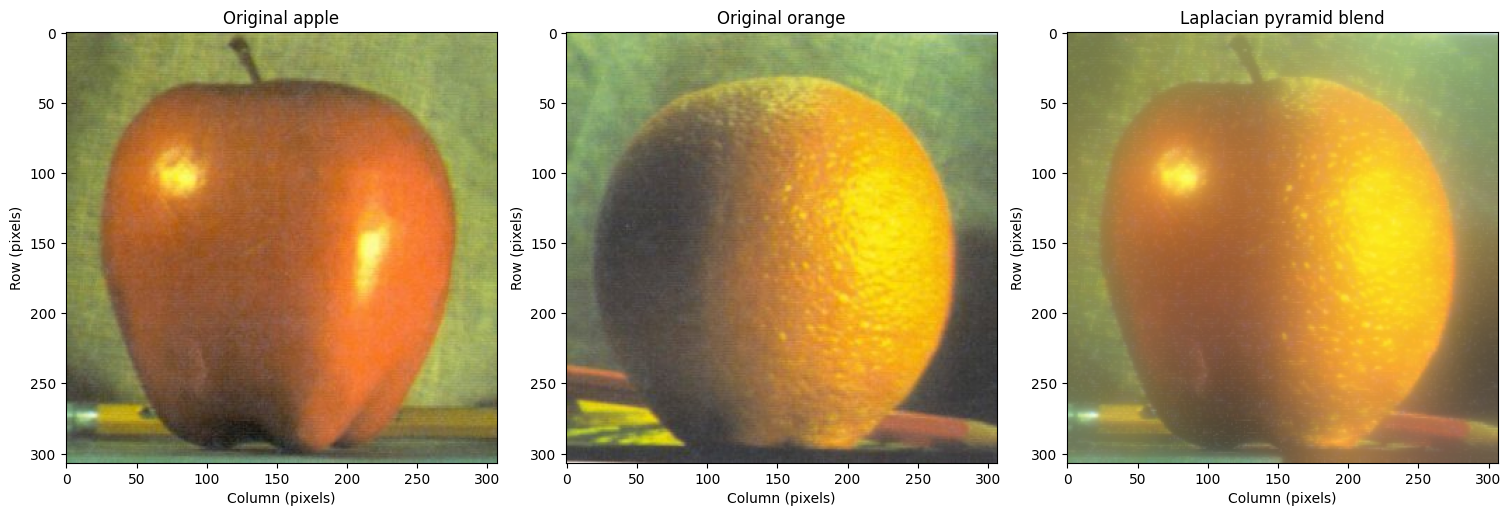

In [49]:
# Convert BGR images to RGB for Matplotlib display.
apple_rgb = cv2.cvtColor(apple_bgr, cv2.COLOR_BGR2RGB)
orange_rgb = cv2.cvtColor(orange_bgr, cv2.COLOR_BGR2RGB)
blended_rgb = cv2.cvtColor(blended_bgr, cv2.COLOR_BGR2RGB)

# Display the two source images and the reconstructed Laplacian blend side by side.
fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
display_images = [
    ("Original apple", apple_rgb),
    ("Original orange", orange_rgb),
    ("Laplacian pyramid blend", blended_rgb),
]

for ax, (title, image) in zip(axes, display_images):
    ax.imshow(image)
    ax.set_title(title)
    ax.set_xlabel("Column (pixels)")
    ax.set_ylabel("Row (pixels)")

plt.show()

**Observation:** The final panel shows the reconstructed multiresolution blend, combining the apple region from the left with the orange region from the right. The transition is produced through the Gaussian mask and Laplacian pyramid levels rather than by directly joining the two full-resolution images at one column.

Visual inspection of this panel is used to assess whether the composite appears smooth across the central transition while preserving recognizable structure from both source images.

## Conclusion

The experiments show a consistent relationship between the mathematical behavior of each image-processing method and the observed outputs. Grayscale conversion reduced the color image to one intensity channel while preserving spatial structure. Canny edge detection showed that hysteresis thresholds mainly control which candidate edges survive: stricter thresholds reduced weak responses and altered connectivity, while the available data did not support claims about true localization accuracy without annotated boundaries.

For Gaussian filtering, applying $\sigma=2$ twice produced a result very close to one filter with $\sigma=2\sqrt{2}$, consistent with variance addition for ideal Gaussians. The remaining small differences were explained by practical implementation effects such as finite support, sampling, borders, and numerical precision.

In the salt-and-pepper experiment, the median filter gave the best overall visual trade-off among the selected filters and also the lowest MAE of the selected 30% outputs. This agrees with its rank-based mechanism, which is less sensitive to isolated extreme values than Gaussian averaging. Finally, Laplacian pyramid blending combined image content across multiple spatial scales, allowing the apple and orange images to transition through scale-dependent mask weights rather than through a single hard boundary.

Overall, the results support the broader principle that image-processing performance depends on matching the method to the structure of the signal and the corruption or transformation being modeled.

## Alternative Evidence-Based Conclusion

The experiments in this assignment illustrate how the behavior of classical image-processing methods can be understood by relating their mathematical mechanisms to the observed image results.

The grayscale conversion in Task 1 reduced each color pixel to a single intensity value while preserving the original spatial dimensions. This simplification made the image suitable for later intensity-based operations such as filtering and edge detection, while also demonstrating that color information is necessarily discarded during the conversion.

The Canny experiments in Task 2 showed that edge detection depends not only on local intensity changes, but also on smoothing, gradient estimation, non-maximum suppression, and hysteresis thresholding. Changing the lower and upper thresholds altered the number and connectivity of retained edge responses. Lower thresholds preserved more weak structures but also retained more texture-related responses, whereas stricter thresholds removed many weak responses and sometimes fragmented contours. These observations support interpreting the thresholds as controls on edge survival rather than as direct measures of edge accuracy. Because no annotated ground-truth boundaries were available, the experiments do not establish which threshold pair is objectively optimal in terms of localization or false-positive rate.

Task 3 examined the relationship between Gaussian filtering with $\sigma=2\sqrt{2}$ and two sequential Gaussian filters with $\sigma=2$. The two outputs were visually very similar and differed only slightly numerically. This is consistent with the theoretical result that Gaussian variances add under convolution, since $2^2+2^2=8$ and therefore the effective standard deviation is $2\sqrt{2}$. The remaining non-zero differences are consistent with practical effects introduced by finite kernel truncation, discrete sampling, normalization, border handling, and numerical computation. The experiment therefore supports the theoretical variance-addition relation while also showing why finite digital implementations need not be exactly identical.

The salt-and-pepper experiments in Task 4 demonstrated that the suitability of a filter depends strongly on the noise model. For the completed 30% case, the selected median filter provided the best overall visual balance among the tested settings and also produced the lowest MAE among the selected Gaussian, median, and bilateral outputs. This result is consistent with the median filter's rank-based operation, which limits the influence of isolated extreme values. Gaussian filtering reduced some visible impulse severity but also spread corrupted intensities through local averaging and softened image details. The bilateral filter preserved some structure through intensity-aware weighting, but its performance depended strongly on the selected range and spatial parameters. These findings are specific to the tested image, noise realization, and parameter choices and should not be interpreted as a universal ranking of the three filters.

Task 5 used Gaussian and Laplacian pyramids to perform multiresolution image blending. The image information was decomposed across spatial scales, corresponding Laplacian levels were combined using a Gaussian mask pyramid, and the final image was reconstructed from coarse to fine levels. This procedure allows the transition between the apple and orange images to be distributed across multiple spatial frequencies rather than imposed as a single hard boundary. The implementation therefore illustrates the main principle of Laplacian pyramid blending: low-frequency content can transition gradually across a broad region while finer-scale details remain more localized.

Taken together, the experiments suggest that effective image processing depends on matching the mathematical properties of an operation to the structure of the image and to the type of transformation or corruption being addressed. The results also show the importance of distinguishing theoretical expectations from empirical evidence: some conclusions are supported directly by measured outputs, while others remain qualitative because ground-truth annotations or broader repeated experiments were not available.

# AI Tools Disclosure

ChatGPT was used to support conceptual understanding, clarify assignment requirements, and review explanations.
OpenAI Codex was used to assist with code development, debugging, and implementation verification. The final work was reviewed and validated by me.

# References 
- https://docs.opencv.org/5.0/tutorials/tutorials.html
- https://www.geeksforgeeks.org/python/opencv-python-tutorial/


# Appendices

Task 1 — Image Loading and Grayscale Conversion
| Assignment requirement | Essential conceptual knowledge | Essential programming knowledge |
|---|---|---|
| **1. Read `uni.jpeg` using OpenCV** | A JPEG file on disk is compressed. After loading, OpenCV decodes it into a numerical pixel array. | `img = cv2.imread("uni.jpeg")`; verify loading with `img is not None`. The result is typically a `numpy.ndarray`. |
| **Understand digital image representation** | A digital image is a grid/matrix of pixel values. A pixel is a spatial location containing one intensity value or multiple channel values. | Treat the image as a NumPy array; access pixels using indexing such as `img[y, x]`. |
| **2a. Report spatial dimensions** | Spatial dimensions mean **height × width** only. Height corresponds to rows, width to columns. Channels are not spatial dimensions. | `img.shape` for a color image is usually `(H, W, C)`. Extract with `height, width, channels = img.shape`. |
| **Understand height/width ordering** | In ordinary notation we may say width × height, but NumPy `shape` returns height first, then width. | If `img.shape = (720, 1280, 3)`, then height = 720 and width = 1280. |
| **2b. Report number of color channels** | A color image usually has 3 channels. Each pixel contains three channel values. | `channels = img.shape[2]`. A color image is commonly `(H, W, 3)`. |
| **RGB vs BGR** | RGB means Red-Green-Blue, but OpenCV reads color images in **BGR** order by default. | `cv2.imread()` gives BGR. Before displaying with Matplotlib, use `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)`. |
| **2c. Report data type** | `dtype` defines how pixel values are stored numerically. A common type is `uint8`. | Use `img.dtype`. For `uint8`, each channel value uses 1 byte. |
| **Understand `uint8`** | `uint8` = unsigned 8-bit integer. It can represent \(2^8=256\) values, from 0 to 255. | Be aware that later arithmetic with `uint8` may involve clipping or overflow issues. |
| **2d. Report numerical intensity range** | Distinguish between **representable range** and **observed range**. `uint8` can represent 0–255, but the actual image may contain only, for example, 10–245. | Use `img.min()` and `img.max()` to obtain the actual observed range. |
| **Understand intensity** | In grayscale, 0 = black and 255 = white. Intermediate values represent gray levels. In color images, each channel has its own intensity values. | `img.min()` and `img.max()` on a color image search across all channel values. |
| **2e. Report memory requirements** | Memory depends on \(H \times W \times C \times \text{bytes per value}\). Number of pixels is \(H \times W\), not \(H \times W \times C\). | Use `img.nbytes`, or compute `img.size * img.itemsize`. |
| **Memory vs JPEG file size** | JPEG file size is not the same as decoded image memory. JPEG is compressed; the NumPy image array stores decoded pixel values. | Do not use file size as a substitute for `img.nbytes`. |
| **Display the original image** | Correct display requires handling the BGR-to-RGB difference. | `img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` then `plt.imshow(img_rgb)`. |
| **3. Convert the image to grayscale** | Grayscale reduces each color pixel from three channel values to one intensity value. It is not simply selecting one channel. | `gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)`. |
| **Understand what changes after grayscale conversion** | Before: `(H, W, 3)`. After: `(H, W)`. Height and width stay the same; color information is removed. | Check `gray.shape` and `gray.ndim`. Typically `gray.ndim == 2`. |
| **Avoid a common mistake** | `img[:, :, 0]` is not grayscale; it is only one channel. In OpenCV, it is the Blue channel. | Use `cv2.cvtColor(..., cv2.COLOR_BGR2GRAY)` instead of slicing. |
| **4. Display the grayscale image** | A grayscale image is a 2D intensity map. | `plt.imshow(gray, cmap="gray")` and `plt.axis("off")`. |
| **Understand `shape` vs `ndim`** | `shape` gives the size of each array dimension. `ndim` gives the number of array dimensions. A color image with `ndim=3` is not spatially 3D. | Color image: usually `ndim == 3`; grayscale: usually `ndim == 2`. |
| **Verification** | Do not only check that the code runs. Confirm that dimensions, channels, dtype, range, and visual output are logically correct. | Verify, for example, `img.shape[:2] == gray.shape`. |

Task 2 — Edge Detection Using Canny
| Assignment requirement | Essential conceptual knowledge | Essential programming knowledge |
|---|---|---|
| **1. Use the grayscale image from Task 1** | Canny mainly operates on intensity changes, so a single-channel grayscale image is appropriate. | Reuse the `gray` image created in Task 1. |
| **2. Apply Canny edge detection** | An edge is a location of rapid change in image intensity. Canny is a multi-stage pipeline, not just a thresholding operation. | `edges = cv2.Canny(gray, lower, upper)`. |
| **Understand what an edge is** | A sharp intensity transition, such as \(20,22,25,210,215\), indicates a likely boundary. | No separate code is required, but this concept is essential for interpreting the result. |
| **3. Display grayscale and edge images side by side** | Visual comparison helps relate image intensity structure to detected edges. | Use `plt.subplot(...)`, `plt.imshow(gray, cmap="gray")`, and `plt.imshow(edges, cmap="gray")`. |
| **4a. Gaussian smoothing** | Noise should be reduced before differentiation because derivatives amplify noise. Gaussian smoothing acts as a low-pass filter. | Can be illustrated with `cv2.GaussianBlur(gray, ...)`. |
| **Understand Gaussian parameters** | Larger \(\sigma\) means stronger smoothing: less noise, but potentially fewer fine details and weak edges. | Understand kernel size and `sigmaX` in `cv2.GaussianBlur`. |
| **4b. Gradient computation** | Compute image change in horizontal and vertical directions: \(G_x \approx \partial I/\partial x\), \(G_y \approx \partial I/\partial y\). | Can be implemented explicitly with `cv2.Sobel` for learning, even if the final solution uses `cv2.Canny()`. |
| **Understand discrete derivatives** | A digital image is discrete, so derivatives are approximated using finite differences. | Conceptual example: `I[x+1] - I[x]`. |
| **4c. Gradient magnitude** | Edge strength is measured by \(\sqrt{G_x^2 + G_y^2}\). Larger magnitude means stronger intensity change. | If implemented manually: `np.sqrt(Gx**2 + Gy**2)`. |
| **Gradient orientation** | Edge direction is related to the gradient orientation: \(\theta=\operatorname{atan2}(G_y,G_x)\). The gradient direction is perpendicular to the edge. | If needed manually: `np.arctan2(Gy, Gx)`. |
| **4d. Non-Maximum Suppression (NMS)** | NMS thins edges by keeping only local maxima along the gradient direction. | Usually handled internally by `cv2.Canny()`, but must be understood conceptually. |
| **Why NMS matters** | Without NMS, edge responses can be thick. NMS improves localization and produces thin edges. | No separate implementation is required unless explaining the pipeline manually. |
| **4e. Hysteresis thresholding** | Two thresholds are used: \(T_{low}\) and \(T_{high}\). Strong edges are above the high threshold; weak edges lie between the two. | In OpenCV: `cv2.Canny(gray, lower, upper)`. |
| **Why two thresholds?** | The high threshold identifies reliable edges. The low threshold allows weak edges to survive only when connected to strong edges. | Do not treat the thresholds as arbitrary numbers; justify them experimentally. |
| **Understand hysteresis connectivity** | A weak edge is kept only if connected to a strong edge. This improves continuity while rejecting isolated noise responses. | This is handled internally by `cv2.Canny()`. |
| **5. Report suitable lower and upper thresholds** | There is no universally correct pair. Suitable values depend on contrast, noise, and image content. | Example: `cv2.Canny(gray, 100, 200)`, but the final pair should be based on actual inspection of `uni.jpeg`. |
| **Justify threshold selection** | The chosen pair should balance edge continuity, preservation of meaningful boundaries, and rejection of irrelevant responses. | Compare several threshold pairs and justify the selected one. |
| **6. Investigate changing thresholds** | The task requires analysis, not only execution. You must study how threshold changes affect the edge map. | Try multiple pairs, for example `(50,100)`, `(100,200)`, `(150,250)`, or values better suited to the actual image. |
| **Effect on connectivity** | Lower thresholds may preserve more weak segments and improve continuity. Higher thresholds may break contours. | Compare the edge maps side by side. |
| **Effect on localization** | Good localization means detected edges lie close to the actual physical/image boundary. | Inspect where detected edges appear relative to visible object boundaries. |
| **False positives** | A false positive is a detected edge that is not a meaningful true boundary, often caused by noise or texture. | Lower thresholds usually increase false positives. |
| **False negatives** | A false negative is a real edge that was missed. | Higher thresholds usually increase false negatives. |
| **Effect of low thresholds** | More sensitivity, more detected edges, often better connectivity, but also more noise and texture responses. | Use a low threshold pair and note the increase in irrelevant edges. |
| **Effect of high thresholds** | Cleaner edge map, but weak real edges may disappear and contours may become fragmented. | Use a higher pair and compare missing edges and broken contours. |
| **Interpret the output** | Canny typically produces a binary-like edge image: 0 = non-edge, 255 = edge. | `edges.dtype` is usually `uint8`; `np.unique(edges)` can verify output values if needed. |
| **Understand Gaussian vs Canny** | Gaussian filtering is a smoothing operation. Canny uses smoothing as one stage before gradient analysis and thresholding. | Do not confuse `cv2.GaussianBlur()` with `cv2.Canny()`. |
| **Verification** | A "good" result is not simply the one with the most edges. It should balance connectivity, localization, noise suppression, and edge preservation. | Compare outputs visually and select a justified threshold pair. |

Task 3 — Gaussian Filtering and Comparison
| Assignment requirement | Essential conceptual knowledge | Essential programming knowledge |
|---|---|---|
| **1. Apply one Gaussian filter with \(\sigma=2\sqrt2\)** | Gaussian filtering performs weighted local averaging. Nearby pixels receive larger weights than distant pixels. Larger \(\sigma\) means stronger smoothing. | `cv2.GaussianBlur(gray, (0,0), sigmaX=2*np.sqrt(2))`. Using `(0,0)` lets OpenCV choose a suitable kernel size from \(\sigma\). |
| **Understand Gaussian filtering** | Gaussian is a **low-pass filter**: it suppresses high-frequency content such as noise and fine details. | Know the roles of kernel size and `sigmaX`; do not treat `GaussianBlur()` as a black box. |
| **2. Apply Gaussian twice with \(\sigma=2\)** | Two successive Gaussian filters combine according to their **variances**, not by directly adding standard deviations. | Apply the second blur to the output of the first: `g2a = GaussianBlur(gray, ..., 2)` then `g2 = GaussianBlur(g2a, ..., 2)`. |
| **Gaussian composition rule** | \(\sigma_c^2=\sigma_1^2+\sigma_2^2\). Therefore \(2^2+2^2=8\), so \(\sigma_c=\sqrt8=2\sqrt2\). | No special function is needed; this equation explains why the two implementations should be approximately equivalent. |
| **3. Display both results** | The two images should look almost identical because their theoretical effective Gaussian smoothing is the same. | Display both with `plt.imshow(..., cmap="gray")` and comparable plotting settings. |
| **4. Compute absolute pixel-wise difference** | Compare corresponding pixels using \(D(x,y)=|I_1(x,y)-I_2(x,y)|\). Zero means identical values. | Prefer `cv2.absdiff(g1, g2)` or safely convert dtype before manual subtraction. |
| **Understand why ordinary subtraction can be risky** | With `uint8`, negative differences cannot be represented naturally. | Avoid simply doing `g1 - g2` on `uint8` unless converting to a signed/float type first. `cv2.absdiff()` avoids this problem. |
| **5. Display difference image** | Dark pixels mean very small differences; brighter pixels mean larger differences. | `plt.imshow(diff, cmap="gray")`. Inspect `diff.min()`, `diff.max()`, or mean difference if useful. |
| **Interpret the difference** | Theoretically the results should match, but practical digital filtering is only an approximation of the continuous theory. | Do not claim exact equality just because the images look identical. Numerical inspection is useful. |
| **6a. Finite kernel truncation** | A true Gaussian extends infinitely, but a digital kernel must be finite. Truncating the tails introduces approximation. | Kernel choice/automatic kernel construction can slightly change results. |
| **6b. Discrete sampling** | Continuous Gaussian functions are sampled on a discrete pixel grid. | Both the image and kernel are discrete arrays. |
| **6c. Kernel normalization** | Gaussian weights ideally sum to 1, but discrete approximations and rounding can create tiny differences. | OpenCV performs normalization internally; understand why small numerical deviations can remain. |
| **6d. Boundary handling** | Near image borders, the full neighborhood is unavailable, so artificial boundary values must be generated. | OpenCV uses a border strategy; different border modes can change edge-region results. |
| **6e. Numerical precision** | Finite floating-point precision and conversion back to image dtype may cause small rounding differences. | Understand float calculations, rounding, clipping, and conversion to `uint8`. |
| **Final interpretation** | \(G_{2} * G_{2} \approx G_{2\sqrt2}\), but implementation details can make the pixel values slightly different. | Present both images, the difference image, and a short evidence-based explanation. |

Task 4 — Salt-and-Pepper Noise Removal
| Assignment requirement | Essential conceptual knowledge | Essential programming knowledge |
|---|---|---|
| **1. Read `uni.jpeg` and convert to grayscale** | Noise experiments are performed on a single intensity channel. | `img = cv2.imread(...)`, then `gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)`. |
| **2. Add 30% salt-and-pepper noise** | Salt-and-pepper is **impulse noise**. Random pixels are replaced by extreme values rather than slightly perturbed. | Select approximately 30% of pixel locations randomly and replace them with 0 or 255. |
| **Understand “salt” and “pepper”** | Salt = white impulses, usually 255. Pepper = black impulses, usually 0. | Use masks or random indices; do not add ordinary Gaussian random values. |
| **Understand noise density** | 30% density means approximately 30% of image pixels are corrupted. Likewise 10% and 50%. | Compute number corrupted from `density * gray.size`, or use a random mask. |
| **Random corruption** | Noise should affect random spatial locations rather than a fixed region. | Use NumPy random generation; setting a random seed is useful for reproducibility. |
| **3. Display noisy image** | Visually confirm that black and white impulse pixels appear across the image. | `plt.imshow(noisy, cmap="gray")`. |
| **4a. Apply Gaussian filter** | Gaussian replaces each pixel with a weighted average. It spreads extreme impulse values into neighboring pixels, so it is usually not ideal for salt-and-pepper noise. | `cv2.GaussianBlur(noisy, ...)`; tune kernel size/\(\sigma\). |
| **4b. Apply Median filter** | Median filtering replaces a pixel with the **median of its neighborhood**. Extreme 0/255 outliers have much less influence on the median. | `cv2.medianBlur(noisy, ksize)`. Kernel size must be an odd positive integer. |
| **Why Median is suitable** | It removes isolated impulse values without averaging them into neighboring pixels and tends to preserve edges better than simple averaging. | Compare multiple kernel sizes such as 3×3 and 5×5 rather than assuming one is always best. |
| **4c. Apply Bilateral filter** | Bilateral filtering considers both spatial closeness and intensity similarity. It smooths while trying to preserve edges. | `cv2.bilateralFilter(noisy, d, sigmaColor, sigmaSpace)`. Understand what each parameter controls. |
| **Bilateral intuition** | Nearby pixels contribute more, but pixels with very different intensities contribute less. | `sigmaColor` controls intensity similarity; `sigmaSpace` controls spatial influence. |
| **5. Select suitable parameters** | “Best” means balancing noise removal and preservation of meaningful image detail. | Experiment with kernel/filter parameters and document the selected values. |
| **6. Display three results side by side** | Direct visual comparison is necessary because filters behave differently on impulse noise. | Use consistent subplot layout and labels. |
| **7. Compare filters** | Evaluate both **noise removal** and **detail/edge preservation**. A smoother image is not automatically better. | Compare outputs visually and optionally with numerical metrics if useful. |
| **Gaussian result** | Often leaves or spreads impulse corruption and blurs edges. | Larger kernels remove more variation but cause stronger blur. |
| **Median result** | Usually strongest choice for salt-and-pepper noise because it rejects extreme outliers. | Kernel size matters: too small may leave specks; too large may remove details. |
| **Bilateral result** | Can preserve edges well, but impulse noise may remain because extreme corrupted pixels can be difficult to handle effectively. | Tune `d`, `sigmaColor`, and `sigmaSpace`; higher settings do not automatically mean better results. |
| **8. Repeat for 10%, 30%, 50% noise** | As noise density increases, restoration becomes harder because more true pixel information has been destroyed. | Use the same experimental pipeline for densities `0.1`, `0.3`, `0.5`. |
| **Compare across densities** | A filter that works well at 10% may lose detail or fail at 50%. Filter effectiveness depends on corruption severity. | Keep parameters controlled or clearly document when parameters change across densities. |
| **9. Explain why Gaussian is suboptimal** | Gaussian computes weighted averages, so an impulse value such as 255 contaminates neighboring outputs rather than simply being rejected. | Connect this explanation directly to observed Gaussian-filtered results. |
| **Reproducibility** | Random noise can produce different results each run. Fair comparisons should use the same noisy image for all filters at a given density. | Generate one noisy image per density, then apply all three filters to that same image; optionally set `np.random.seed(...)`. |

Task 5 — Image Blending Using Laplacian Pyramids
| Assignment requirement | Essential conceptual knowledge | Essential programming knowledge |
|---|---|---|
| **1. Read `apple.jpg` and `orange.jpg`** | These are the two source images to be combined. | `cv2.imread()`; remember BGR/RGB when displaying. |
| **2. Ensure compatible dimensions** | Corresponding pyramid levels must have compatible shapes for pixel-wise blending. | Resize/crop consistently if necessary. Check `apple.shape == orange.shape`. |
| **Understand direct blending problem** | Simply joining half an apple and half an orange often creates a visible seam because brightness, color, and structures change abruptly. | A simple concatenation is useful only as a baseline, not the final method. |
| **3. Construct Gaussian pyramids** | A Gaussian pyramid represents the image at progressively lower spatial resolutions. Before downsampling, smoothing is required to reduce aliasing. | Repeatedly use `cv2.pyrDown()`. Store each level in a list. |
| **Understand downsampling** | Each lower level contains fewer pixels and represents coarser image structure. | `pyrDown` performs smoothing + reduction. Dimensions are roughly halved each level. |
| **Why smooth before downsampling?** | Downsampling without low-pass filtering can cause aliasing because high-frequency information is undersampled. | Prefer `cv2.pyrDown()` rather than crude array skipping. |
| **4. Construct Laplacian pyramids** | A Laplacian level stores information lost between two Gaussian scales — roughly the detail/band-pass information at that scale. | Compute level-wise difference between a Gaussian level and the expanded next level. |
| **Core Laplacian equation** | \[L_k = G_k-\operatorname{Expand}(G_{k+1})\] | Expand using `cv2.pyrUp()`, resize if necessary to guarantee identical dimensions, then subtract. |
| **What each Laplacian level represents** | Fine levels contain fine details/edges; coarser levels contain broader structures. | Store Laplacian levels in the correct order for later reconstruction. |
| **5. Create blending mask** | The mask specifies which source contributes at each location. Typically values near 1 select one image and values near 0 select the other. | Create a NumPy mask with the same spatial dimensions as the images. |
| **Why not use only one sharp mask?** | A sharp mask at every scale produces an abrupt seam. The mask should become smoother at coarser scales. | Construct a **Gaussian pyramid of the mask** using `cv2.pyrDown()`. |
| **Mask Gaussian pyramid** | Different spatial scales require different transition widths. Fine details transition sharply; broad structures transition smoothly. | Keep mask pyramid levels aligned with the image pyramid levels. |
| **6. Blend corresponding Laplacian levels** | At each scale, combine image details using the corresponding smoothed mask. | Typically \(L_k = M_kL^A_k+(1-M_k)L^B_k\). |
| **Understand level-wise blending** | Instead of making one abrupt decision at full resolution, blending is distributed across spatial frequencies/scales. | Ensure mask values are floating point, usually in \([0,1]\), and shapes/channels match. |
| **Color image masks** | A 2D mask may need a channel axis so it can multiply a 3-channel image correctly. | Example: `mask[..., None]` or equivalent broadcasting arrangement. |
| **7. Reconstruct final image** | Reconstruction combines coarse structure with progressively finer Laplacian details. | Start from the coarsest blended level, repeatedly `pyrUp()` and add the next Laplacian level. |
| **Reconstruction principle** | Since \(L_k = G_k-\text{Expand}(G_{k+1})\), reversing gives \(G_k=L_k+\text{Expand}(G_{k+1})\). | `current = cv2.pyrUp(current)` then align size and add corresponding Laplacian level. |
| **8. Display originals and result** | The final blend should have a much smoother transition than a direct hard join. | Convert BGR→RGB for Matplotlib and display apple, orange, and blended output clearly. |
| **Why pyramid blending works** | Large-scale intensity/color differences are blended over wider regions, while fine details can transition over narrower regions. | The quality depends on number of pyramid levels and mask design. |
| **Number of pyramid levels** | Too few levels may leave a visible seam; too many can cause excessive broad mixing or shape-management issues. | Choose a sensible level count based on image size. |
| **Shape mismatch issue** | Odd image dimensions can cause `pyrDown`/`pyrUp` outputs to differ by one pixel. | Always verify shapes; use explicit destination sizing/resizing when reconstructing or subtracting. |
| **dtype consideration** | Laplacian values can be negative because they represent differences. | Use floating-point arrays for Laplacian operations rather than blindly subtracting `uint8`. |
| **Final clipping** | After reconstruction, values may fall outside the displayable image range. | Clip to valid range and convert back to `uint8` if needed. |
| **Verification** | A correct output should reconstruct logically, preserve recognizable content from both images, and reduce the central seam. | Check dimensions, mask alignment, pyramid level counts, and the final visual result. |